# Polarization Alignment Notebook

## Purpose
This notebook aligns positive (CPR) and negative (CPL) polarization ptychography image stacks and produces:
- **Charge Contrast (CC):** OD_pos + OD_neg_aligned
- **XMCD:** OD_neg_aligned - OD_pos

## Workflow
1. **Imports** 
2. **User Configuration** — all tunable parameters in one place
3. **Load Data** — read image stacks and angle arrays from disk
4. **Inspect & Clean** — identify and remove mismatched or duplicate scans
5. **Single-Scan Preview** — verify pipeline on one scan before batch processing
6. **Batch Alignment** — align all scans via phase cross-correlation
7. **I0 Normalization Check** — plot fiducial intensity vs. angle
8. **Compute OD, CC, XMCD** — convert to optical density and derive contrast stacks
9. **Review All Scans** — plot CC and XMCD across the full tilt series
10. **Angle Calibration** — fit cosine to NRMSE, find and shift true zero angle
11. **Regional Variance / PSD Quality Check** — flag scans with anomalous signal
12. **Optional Re-Alignment** — second pass with tighter bounds for flagged scans
13. **Optional: Build Skipped Dataset** — compact stack excluding bad scans
14. **Save Outputs** — write aligned stacks and angle arrays to disk

## Dependencies
All shared functions live in `Functions.py` (same directory as this notebook)
and are accessed as `register.function_name()`.

---
## Step 1 — Imports

In [2]:
import numpy as np
import os
import tifffile
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.fft import fftn, ifftn
from scipy.ndimage import fourier_shift
from scipy.optimize import curve_fit

# All shared functions are imported from Functions.py as 'register'
# so every call reads clearly as register.function_name(...)
import Functions as register

import itertools
from skimage import measure, transform
from scipy import ndimage


---
## Step 2 — User Configuration

**Edit this cell for every new dataset.** All parameters that vary between
samples or experiments are defined here and propagated automatically.

In [3]:
# --- Sample Identity ---------------------------------------------------------
sample = "105"          
Gamma  = "Gamma45"       
single_scan = False
pre_edge = False


data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
# --- Data Date / Version Tag -------------------------------------------------
# Appended to input and output filenames to version-control processing runs.

# --- Plot Colors -------------------------------------------------------------
# color_1 / color_2: light/dark pair for NRMSE cosine fit plots.


if sample == '270':
    fiduc_num = 3
    if Gamma == "Gamma90":
        date  = '_29APR26_og_ptycho'
        date1  = date  
        color_1 = 'm'          
        color_2 = 'darkmagenta' 
    elif Gamma == "Gamma0": 
        # date  = '_16MAR26_og_ptycho'
        date  = '_29APR26_og_ptycho_light_on'
        date1 = date            
        color_1 = 'cornflowerblue'          
        color_2 = 'royalblue' 

        systematic_noise = True ## light was left on 
            
    elif Gamma == 'Gamma45': 
        date  = '_29APR26_og_ptycho'
        date1  = date    
        color_1 = 'limegreen'           # e.g. 'm', 'cornflowerblue', 'tab:blue'
        color_2 = 'darkgreen' # e.g. 'darkmagenta', 'royalblue'


if sample == '452':
    fiduc_num = 3
    if Gamma == "Gamma90":
        date = '_16MAR26_og_ptycho'  
        date1  = '_16MAR26_og_ptycho_all_scans_failed_psd'
        color_1 = 'm'          
        color_2 = 'darkmagenta' 
    elif Gamma == "Gamma0": 
        if single_scan == True: 
            date  = '_09MAR26_large_Ni_Scan'
            date1 = date            
            color_1 = 'cornflowerblue'           
            color_2 = 'royalblue'
    
            data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
            pos_images = f"OD_pospol_stack{date}.tiff"
            neg_images = f"OD_negpol_stack{date}.tiff"
            
            # --- Load stacks and angle arrays --------------------------------------------
            image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
            image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
            
            angles_pospol = np.array([0])
            angles_negpol = np.array([0])

        elif pre_edge == True: 
            date  = '_21MAR26_Co_Ni_pre_edge'
            
            color_1 = 'k'          
            color_2 = 'k'
    
            data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
            pos_images = f"pre_edge_pospol_stack{date}.tiff"
            neg_images = f"pre_edge_negpol_stack{date}.tiff"
            
            # --- Load stacks and angle arrays --------------------------------------------
            image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
            image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
            
            angles_pospol = np.zeros((image_stack_pospol.shape[0]))
            angles_negpol = np.zeros((image_stack_pospol.shape[0]))
            print(angles_pospol.shape)
            
        else:
            # date  = '_16MAR26_og_ptycho'
            date  = '_1APR26_recon_ptycho'
            date1 = date            
            color_1 = 'cornflowerblue'          
            color_2 = 'royalblue' 
            
    elif Gamma == 'Gamma45': 
            if single_scan == True: 
                date  = '_18MAR26_Co_Ni_high_angle'
                date1  = '_21MAR26_og_ptycho_all_scans_failed_psd'          
                color_1 = 'limegreen'           # e.g. 'm', 'cornflowerblue', 'tab:blue'
                color_2 = 'darkgreen' # e.g. 'darkmagenta', 'royalblue'
    
            else:
                date  = '_21MAR26_og_ptycho'
                date1  = '_21MAR26_og_ptycho_all_scans_failed_psd'    
                color_1 = 'limegreen'           # e.g. 'm', 'cornflowerblue', 'tab:blue'
                color_2 = 'darkgreen' # e.g. 'darkmagenta', 'royalblue'


elif sample == '665':
    fiduc_num = 4
    if Gamma == 'Gamma0': 
        date = '_3AUG25_check_saturation_n50'
        date1 = date

        pos_images = f"OD_pospol_stack{date}.tiff"
        neg_images = f"OD_negpol_stack{date}.tiff"
        pos_angles = f"angles_pospol{date1}.txt"
        neg_angles = f"angles_negpol{date1}.txt"

        image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
        image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
        
        angles_pospol = np.loadtxt(os.path.join(data_dir, pos_angles))
        angles_negpol = np.loadtxt(os.path.join(data_dir, neg_angles))

        color_1 = 'cornflowerblue'          
        color_2 = 'royalblue' 

    elif Gamma == 'Gammaneg45':
        date = '_5AUG25_check_saturation_n50'
        date1 = date
        color_1 = 'limegreen'           # e.g. 'm', 'cornflowerblue', 'tab:blue'
        color_2 = 'darkgreen' # e.g. 'darkmagenta', 'royalblue'

        pos_images = f"OD_pospol_stack{date}.tiff"
        neg_images = f"OD_negpol_stack{date}.tiff"
        pos_angles = f"angles_pospol{date1}.txt"
        neg_angles = f"angles_negpol{date1}.txt"


        image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
        image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
        
        angles_pospol = np.loadtxt(os.path.join(data_dir, pos_angles))
        angles_negpol = np.loadtxt(os.path.join(data_dir, neg_angles))



elif sample == '105':
    fiduc_num = 3
    if Gamma == 'Gamma0': 
        date = '_17NOV25_auto_select_scans_fullrange'
        date1 = date

        pos_images = f"OD_pospol_stack{date}.tiff"
        neg_images = f"OD_negpol_stack{date}.tiff"
        pos_angles = f"angles_pospol{date1}.txt"
        neg_angles = f"angles_negpol{date1}.txt"

        image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
        image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
        
        angles_pospol = np.loadtxt(os.path.join(data_dir, pos_angles))
        angles_negpol = np.loadtxt(os.path.join(data_dir, neg_angles))

        color_1 = 'cornflowerblue'          
        color_2 = 'royalblue' 

    elif Gamma == 'Gamma45':
        date = '_19NOV25_select_fullrange'
        date1 = date
        color_1 = 'limegreen'           # e.g. 'm', 'cornflowerblue', 'tab:blue'
        color_2 = 'darkgreen' # e.g. 'darkmagenta', 'royalblue'

        pos_images = f"OD_pospol_stack{date}.tiff"
        neg_images = f"OD_negpol_stack{date}.tiff"
        pos_angles = f"angles_pospol{date1}.txt"
        neg_angles = f"angles_negpol{date1}.txt"


        image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
        image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
        
        angles_pospol = np.loadtxt(os.path.join(data_dir, pos_angles))
        angles_negpol = np.loadtxt(os.path.join(data_dir, neg_angles))

# CPL (negative) and CPR (positive) colors for histogram overlays
color_neg = 'blue'
color_pos = 'orange'

# --- Alignment Parameters ----------------------------------------------------
# factor: pixels above (factor * image_max) are treated as fiducial holes
# for cross-correlation masking. 0.7 = top 30% of intensity range.
factor = 0.7
set_factor = 1.75

# bound: half-width in pixels of the cross-correlation search window.
# Larger values allow larger shifts but increase compute time.
bound = 100
bin_size = 100 #100 

# --- Plotting Control --------------------------------------------------------
# Set True/False to control diagnostic output.
# Disabling histograms during batch loops reduces memory usage significantly.
PLOT_FIDUCIAL_HIST = True   # Histograms from auto_normalize_by_fiducial
PLOT_CHARGE_HIST   = False   # Histograms from auto_normalize_charge/OD_charge
PLOT_CROSSCORR     = False    # Before/after XMCD + cross-correlation per scan

# --- Summary -----------------------------------------------------------------
print(f"Configuration loaded: Sample {sample}, {Gamma}")
print(f"  Data tag   : {date}")
print(f"  Alignment  : factor={factor}, bound={bound}")
print(f"  Histograms : fiducial={PLOT_FIDUCIAL_HIST}, charge={PLOT_CHARGE_HIST}")
print(f"  Cross-corr : {PLOT_CROSSCORR}")

Configuration loaded: Sample 105, Gamma45
  Data tag   : _19NOV25_select_fullrange
  Alignment  : factor=0.7, bound=100
  Histograms : fiducial=True, charge=False
  Cross-corr : False


---
## Step 3 — Load Data

Reads the positive and negative polarization amplitude stacks and their
corresponding tilt angle arrays.

**Expected file naming convention:**
- `amplitude_pospol_stack{date}.tiff` / `amplitude_negpol_stack{date}.tiff`
- `angles_pospol{date}.txt` / `angles_negpol{date}.txt`

If your files follow a different pattern, update the filename strings below.

In [4]:
if sample == '452':
# --- Build file paths --------------------------------------------------------
    data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
    n_mode = 2
    
    pos_images = f"amplitude_pospol_stack{date}.tiff"
    neg_images = f"amplitude_negpol_stack{date}.tiff"
    pos_probe = f"probe_pospol_stack{date}_{n_mode}.tiff"
    neg_probe = f"probe_negpol_stack{date}_{n_mode}.tiff"
    pos_angles = f"angles_pospol{date}.txt"
    neg_angles = f"angles_negpol{date}.txt"
    
    # max_avg_diff_neg = f"max_avg_diff_neg_{date1}.txt"
    # max_avg_diff_pos = f"max_avg_diff_pos_{date1}.txt"
    
    # --- Load stacks and angle arrays --------------------------------------------
    image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
    image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
    
    angles_pospol = np.loadtxt(os.path.join(data_dir, pos_angles))
    angles_negpol = np.loadtxt(os.path.join(data_dir, neg_angles))

    probe_pos = tifffile.imread(os.path.join(data_dir, pos_probe))
    probe_neg = tifffile.imread(os.path.join(data_dir, neg_probe))
    
    # max_avg_diff_neg = np.loadtxt(os.path.join(data_dir, max_avg_diff_neg))
    # max_avg_diff_pos = np.loadtxt(os.path.join(data_dir, max_avg_diff_pos))
    
    print(f"Loaded: {data_dir}")
    print(f"  Positive stack : {image_stack_pospol.shape}")
    print(f"  Negative stack : {image_stack_negpol.shape}")
    print(f"  Positive probe : {probe_pos.shape}")
    print(f"  Negative probe : {probe_neg.shape}")
    print(f"  Positive angles: {angles_pospol.shape}")
    print(f"  Negative angles: {angles_negpol.shape}")
    # print(f"  max_avg_diff_pos: {max_avg_diff_pos.shape}")
    # print(f"  max_avg_diff_neg: {max_avg_diff_neg.shape}")

elif sample == '270': 
    data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
    n_mode = 2
    
    pos_images = f"amplitude_pospol_stack{date}.tiff"
    neg_images = f"amplitude_negpol_stack{date}.tiff"
    pos_probe = f"probe_pospol_stack{date}_{n_mode}.tiff"
    neg_probe = f"probe_negpol_stack{date}_{n_mode}.tiff"
    pos_angles = f"angles_pospol{date}.txt"
    neg_angles = f"angles_negpol{date}.txt"
    
    # max_avg_diff_neg = f"max_avg_diff_neg_{date1}.txt"
    # max_avg_diff_pos = f"max_avg_diff_pos_{date1}.txt"
    
    # --- Load stacks and angle arrays --------------------------------------------
    image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
    image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))
    
    angles_pospol = np.loadtxt(os.path.join(data_dir, pos_angles))
    angles_negpol = np.loadtxt(os.path.join(data_dir, neg_angles))

    probe_pos = tifffile.imread(os.path.join(data_dir, pos_probe))
    probe_neg = tifffile.imread(os.path.join(data_dir, neg_probe))
    
    # max_avg_diff_neg = np.loadtxt(os.path.join(data_dir, max_avg_diff_neg))
    # max_avg_diff_pos = np.loadtxt(os.path.join(data_dir, max_avg_diff_pos))
    
    print(f"Loaded: {data_dir}")
    print(f"  Positive stack : {image_stack_pospol.shape}")
    print(f"  Negative stack : {image_stack_negpol.shape}")
    print(f"  Positive probe : {probe_pos.shape}")
    print(f"  Negative probe : {probe_neg.shape}")
    print(f"  Positive angles: {angles_pospol.shape}")
    print(f"  Negative angles: {angles_negpol.shape}")
    # print(f"  max_avg_diff_pos: {max_avg_diff_pos.shape}")
    # print(f"  max_avg_diff_neg: {max_avg_diff_neg.shape}")

else: 
    data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
    
    pos_probe = []
    neg_probe = []

    
    # --- Load stacks and angle arrays --------------------------------------------

    print(f"Loaded: {data_dir}")
    print(f"  Positive stack : {image_stack_pospol.shape}")
    print(f"  Negative stack : {image_stack_negpol.shape}")
    print(f"  Positive angles: {angles_pospol.shape}")
    print(f"  Negative angles: {angles_negpol.shape}")


Loaded: /homes/emma/notebooks/RawData/105/Gamma45/
  Positive stack : (38, 514, 514)
  Negative stack : (38, 514, 514)
  Positive angles: (38,)
  Negative angles: (38,)


---
## Step 4 — Inspect & Clean: Identify Scans to Remove

Before alignment we check for two common data quality issues:

**Issue 1 — Angle mismatch:** If `|angle_neg[k] - angle_pos[k]| > 0.5 deg`,
the CPL and CPR scans at index `k` do not correspond to the same tilt position
and cannot be paired.

**Issue 2 — Repeated scan (bad acquisition):** If consecutive negative angles
differ by less than 0.5 deg, the same tilt position was acquired twice,
usually because the first acquisition was flagged as bad at the beamline.

Run the diagnostic cell first, review its output, then apply deletions below.

### Look at CPL to decide if deletions are needed

In [4]:
# for k in np.arange(0, image_stack_negpol.shape[0]):
#     print(k)
#     print(angles_pospol[k])
#     print(angles_negpol[k])
#     angle = angles_pospol[k]
#     register.plot_CLCR(image_stack_pospol[k], image_stack_negpol[k],  angle=angle, sample=sample, Gamma=Gamma)

### Apply Deletions

Based on the diagnostic output above, fill in the lists below.
Leave a list empty (`[]`) if no deletions are needed for that category.

In [5]:
def ID_angles_to_delete(angles_negpol, angles_pospol):
    print("=" * 60)
    print(f"Angle inspection -- Sample {sample}, {Gamma}")
    print("=" * 60)
    
    suggested_del_neg  = []   # negpol-only candidates
    suggested_del_both = []   # both-stack candidates


    minimum = min(angles_pospol.shape[0], angles_negpol.shape[0])

    print(f'minimum = {minimum}')
    
    n_scans = minimum - 1

    ct = 0
    for k in range(n_scans):
        angle_diff = angles_negpol[k] - angles_pospol[k]
    
        # Issue 1: pos/neg angle mismatch at this index
        if abs(angle_diff) > 0.5:
            if ct == 0: 
                ct = ct + 1
                k0 = k-1
                print(f"  [MISMATCH]  k={(k0):3d} | "
                      f"pos={angles_pospol[k0]:.2f}, neg={angles_negpol[k0]:.2f}, "
                      f"diff={angle_diff:.2f} -- consider deleting from negpol or pospol")
                print(f"  [MISMATCH]  k={k:3d} | "
                      f"pos={angles_pospol[k]:.2f}, neg={angles_negpol[k]:.2f}, "
                      f"diff={angle_diff:.2f} -- consider deleting from negpol or pospol")
            else: 
                print(f"  [MISMATCH]  k={k:3d} | "
                      f"pos={angles_pospol[k]:.2f}, neg={angles_negpol[k]:.2f}, "
                      f"diff={angle_diff:.2f} -- consider deleting from negpol or pospol")
            suggested_del_neg.append(k)
    
        # Issue 2: repeated angle in consecutive negpol scans
        if k < n_scans - 1:
            step = angles_negpol[k + 1] - angles_negpol[k]
            if abs(step) < 0.5:
                print(f"  [REPEAT]    k={k:3d}->{k+1} | "
                      f"neg[{k}]={angles_negpol[k]:.2f}, "
                      f"neg[{k+1}]={angles_negpol[k+1]:.2f}, "
                      f"step={step:.2f} -- consider deleting both")
                suggested_del_both.append(k)
        
    
    if not suggested_del_neg and not suggested_del_both:
        delete = False
        print("  No issues detected. All angle pairs appear consistent.")
    else:
        delete = True
        print(f"\nSuggested deletions:")
        print(f"  From negpol or pospol : {suggested_del_neg}")
        print(f"  From both stacks : {suggested_del_both}")
        print("\nEdit and apply deletions in the next cell.")

def apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both):
    # --- Apply deletions ---------------------------------------------------------
    print("=" * 60)
    print("Applying deletions...")
    
    if del_neg_only:
        print(f"  Removing {del_neg_only} from negpol "
              f"(angles: {angles_negpol[del_neg_only].tolist()})")
        angles_negpol      = np.delete(angles_negpol,      del_neg_only)
        probe_neg          = np.delete(probe_neg,      del_neg_only, axis = 0)
        image_stack_negpol = np.delete(image_stack_negpol, del_neg_only, axis=0)
    
    if del_pos_only:
        print(f"  Removing {del_pos_only} from pospol "
              f"(angles: {angles_pospol[del_pos_only].tolist()})")
        angles_pospol      = np.delete(angles_pospol,      del_pos_only)
        probe_pos          = np.delete(probe_pos,      del_pos_only, axis = 0)
        image_stack_pospol = np.delete(image_stack_pospol, del_pos_only, axis=0)
    
    if del_both:
        print(f"  Removing {del_both} from BOTH stacks")
        angles_negpol      = np.delete(angles_negpol,      del_both)
        image_stack_negpol = np.delete(image_stack_negpol, del_both, axis=0)
        angles_pospol      = np.delete(angles_pospol,      del_both)
        image_stack_pospol = np.delete(image_stack_pospol, del_both, axis=0)
        probe_pos          = np.delete(probe_pos,      del_both, axis = 0)
        probe_neg          = np.delete(probe_neg,      del_both, axis = 0)
    
    # --- Verify shapes match after deletions ------------------------------------
    print("\nPost-deletion shapes:")
    print(f"  pospol stack : {image_stack_pospol.shape}")
    print(f"  negpol stack : {image_stack_negpol.shape}")
    print(f"  pospol angles: {angles_pospol.shape}")
    print(f"  negpol angles: {angles_negpol.shape}")
    print(f"  probe_pos: {probe_pos.shape}")
    print(f"  probe_neg: {probe_neg.shape}")

    if angles_pospol.shape[0] == angles_negpol.shape[0]:
        delete = False
        print("\nAll shapes consistent. Ready to proceed.")
    else:
        delete = True
        ID_angles_to_delete(angles_negpol, angles_pospol)
        print("angle count does not match stack depth -- check deletion lists!")
    
    return angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos
    

In [6]:
ID_angles_to_delete(angles_negpol, angles_pospol)

Angle inspection -- Sample 105, Gamma45
minimum = 38
  [REPEAT]    k=  0->1 | neg[0]=-62.28, neg[1]=-61.85, step=0.43 -- consider deleting both
  [REPEAT]    k=  1->2 | neg[1]=-61.85, neg[2]=-61.40, step=0.46 -- consider deleting both

Suggested deletions:
  From negpol or pospol : []
  From both stacks : [0, 1]

Edit and apply deletions in the next cell.


In [7]:
# # Intentional stop -- review Step 11 output before proceeding.
# raise SystemExit("Apply deletions if necessary")

In [8]:
noise_compare_pospol = []
noise_compare_negpol = [] 
noise_compare_angle_pospol = []
noise_compare_angle_negpol = [] 

if sample =='452':
    if Gamma == 'Gamma90':
    
        # --- Indices to delete from NEGATIVE stack only ------------------------------
        # Reason: angle mismatch -- negpol scan does not pair with pospol at this index
        del_neg_only = [45 ] #[45]      # <-- edit this list
        
        # --- Indices to delete from POSITIVE stack only ------------------------------
        del_pos_only = [29 ]      # <-- edit this list
        
        # --- Indices to delete from BOTH stacks --------------------------------------
        # Reason: repeated angle / bad acquisition present in both
        del_both = [42, 43, 44]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
    
    elif Gamma == 'Gamma0':
        del_neg_only = [ ] 
        del_pos_only = [ ]      
        
        del_both = [0,7,10]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
    
    elif Gamma == 'Gamma45':
        del_neg_only = [51] 
        del_pos_only = [ ]      
        
        del_both = [1,4,6,9,11,13,15,17,20,21,23,26,28,29]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
    
        ### second deletion  
        del_neg_only = [] 
        del_pos_only = [ ]      
        
        del_both = [4,47]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)

elif sample == '270': 
    if Gamma == 'Gamma45':
        del_neg_only = [] 
        del_pos_only = [ ]      
        
        del_both = [12, 13]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
    
        ### second deletion  
        # del_neg_only = [] 
        # del_pos_only = [ ]      
        
        # del_both = [4,47]  # <-- edit this list
        
        # angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
    
    elif Gamma == 'Gamma90':
        del_neg_only = [26] 
        del_pos_only = [ ]      
        
        del_both = [21,22,23]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
    
        ## second deletion  
        del_neg_only = [20] 
        del_pos_only = [ 19]      
        
        del_both = [12]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)

    # elif Gamma == 'Gamma0': 

    #     del_neg_only = [] 
    #     del_pos_only = [ ]      
        
    #     del_both = [7,9,13, 16,17,18,19,20,21,22, 26, 28, 30]  # <-- edit this list
        
    #     angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
    
    #     ## second deletion  
    #     del_neg_only = [50] 
    #     del_pos_only = [30,21]      
        
    #     del_both = []  # <-- edit this list
        
    #     angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)


    #     ## fourth deletion  
    #     del_neg_only = [] 
    #     del_pos_only = [ ]      
        
    #     del_both = [28, 18, 16, 13, 11]
        
    #     angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)

    #     ## fourth deletion  
    #     del_neg_only = [] 
    #     del_pos_only = [ ]      
        
    #     del_both = [15]
        
    #     angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)


    #     ## third deletion  
    #     del_neg_only = [] 
    #     del_pos_only = [45]      
        
    #     del_both = [44]  # <-- edit this list
        
    #     angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)


    #     ## third deletion  
    #     del_neg_only = [] 
    #     del_pos_only = [44]      
        
    #     del_both = []  # <-- edit this list
        
    #     angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)


    elif Gamma == 'Gamma0': 

        del_neg_only = [] 
        del_pos_only = [ ]      
        
        del_both = [7,9,13, 16,17,18,19,20,21,22, 26, 28, 30]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)

            
        ## second deletion  
        del_neg_only = [] 
        del_pos_only = [20]      
        
        del_both = []  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)


        if systematic_noise == True: 
            k_list = [25] 
            for k in k_list:
                noise_compare_pospol.append(image_stack_pospol[k]) 
                noise_compare_negpol.append(image_stack_negpol[k]) 
                noise_compare_angle_pospol.append(angles_pospol[k]) 
                noise_compare_angle_negpol.append(angles_negpol[k]) 

        ## third deletion  
        del_neg_only = [] 
        del_pos_only = [29]      
        
        del_both = [25]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)


        if systematic_noise == True: 
            k_list = [51, 52] 
            for k in k_list:
                noise_compare_pospol.append(image_stack_pospol[k]) 
                noise_compare_negpol.append(image_stack_negpol[k]) 
                noise_compare_angle_pospol.append(angles_pospol[k]) 
                noise_compare_angle_negpol.append(angles_negpol[k]) 
                
        ## fourth deletion  
        del_neg_only = [] 
        del_pos_only = []      
        
        del_both = [52,51,18]  # <-- edit this list
        
        angles_negpol, angles_pospol,  image_stack_negpol, image_stack_pospol, probe_neg, probe_pos = apply_deletion(angles_negpol, angles_pospol, image_stack_negpol, image_stack_pospol, probe_neg, probe_pos, del_neg_only, del_pos_only, del_both)
            
else: 
    print(f'no deletions made for sample = {sample}')

no deletions made for sample = 105


### Look at all CPL and CPR to ensure stack makes sense

In [9]:
for k in np.arange(0, image_stack_pospol.shape[0]):
    print(k)
    print(angles_pospol[k])
    print(angles_negpol[k])
#     angle = angles_pospol[k]
#     register.plot_CLCR(image_stack_pospol[k], image_stack_negpol[k],  angle=angle, sample=sample, Gamma=Gamma)

0
-62.282844096
-62.282844096
1
-61.85268962399999
-61.85268962399999
2
-61.396598648
-61.397088016
3
-59.613831024
-59.613831024
4
-58.743734720000006
-58.743245352
5
-56.943349848000004
-56.94286048
6
-55.184561256
-55.18358252
7
-53.387112592
-53.387112592
8
-51.6160898
-51.616579168
9
-49.825981655999996
-49.825492288
10
-46.267297559999996
-46.267297559999996
11
-44.04312
-44.04312
12
-41.81894244
-41.818453072
13
-39.593786144
-39.594275511999996
14
-37.371076688
-37.37058732
15
-35.144941656
-35.145431024
16
-32.922232199999996
-32.921742832
17
-30.699522744
-30.700012112000003
18
-28.491494327999998
-28.490515591999998
19
-26.248231416
-26.248231416
20
-21.799386928
-21.799876296
21
-19.57472
-19.57472
22
-16.906196296
-16.906685664
23
-12.455394336
-12.455394336
24
-3.5767907119999998
-3.5767907119999998
25
0.8901603920000001
0.8901603920000001
26
5.330196256
5.330196256
27
9.78736
9.786870632
28
14.235225752
14.235225752
29
18.68651708
18.68651708
30
21.354062048
21.354062048

In [10]:
stop

NameError: name 'stop' is not defined

##  Quick peak at probe

In [ ]:
## Plot normalizing constant
plt.figure(figsize=(10, 4))
plt.plot(angles_negpol, np.sum(probe_neg, axis=(1, 2)), marker='o', color=color_neg, label='CPL')
plt.plot(angles_pospol, np.sum(probe_pos, axis=(1, 2)), marker='o', color=color_pos, label='CPR')
plt.xlabel('Tilt angle (deg)')
plt.ylabel('Sum')
plt.title(f"sum of probe mode {n_mode} vs. Tilt Angle, Sample {sample}, {Gamma}")
# plt.axvline(angles_pospol[15], color = 'red')
# plt.axvline(angles_pospol[16], color = 'red')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(angles_negpol, np.sum(np.abs(probe_neg), axis=(1, 2)), marker='o', color=color_neg, label='CPL')
plt.plot(angles_pospol, np.sum(np.abs(probe_pos), axis=(1, 2)), marker='o', color=color_pos, label='CPR')
plt.xlabel('Tilt angle (deg)')
plt.ylabel('Sum')
plt.title(f"sum of absolute value of probe mode {n_mode}, Sample {sample}, {Gamma}")
# plt.axvline(angles_pospol[15], color = 'red')
# plt.axvline(angles_pospol[16], color = 'red')
plt.legend()
plt.tight_layout()
plt.show()

k_list = [10,25,58]
for k in k_list:
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    norm_OD = mpl.colors.Normalize(vmin=np.min(np.abs(probe_neg[30])), vmax=np.max(np.abs(probe_neg[30])))
    CL = axes[0].imshow(np.abs(probe_neg[k]), norm=norm_OD)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"CPL Probe mode {n_mode} , Sample {sample}, {Gamma} @ {angles_pospol[k]:.2f}")
    CR = axes[1].imshow(np.abs(probe_pos[k]), norm=norm_OD)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"CPR Probe mode {n_mode} , Sample {sample}, {Gamma} @ {angles_pospol[k]:.2f}")
    plt.tight_layout(); plt.show()

In [ ]:
stop

---
## Step 5 — Single-Scan Preview

Inspect one scan interactively before batch processing to verify the pipeline
works correctly for this dataset. Steps shown:
- Raw CPL / CPR amplitude images
- Unaligned CC and XMCD
- Fiducial normalization and optical density
- Fiducial hole mask
- Cross-correlation alignment and result

Set `k` to any scan index you want to inspect.

In [11]:
# --- Select scan to preview --------------------------------------------------
k = 0  # <-- change to preview a different scan
bound_preview = 50   # smaller bound for faster preview (full bound used in batch) 
set_factor = 1.8

angle = angles_pospol[k]
print(f"Previewing k={k} | pos={angles_pospol[k]:.2f} deg, neg={angles_negpol[k]:.2f} deg")
# -----------------------------------------------------------------------------

Previewing k=0 | pos=-62.28 deg, neg=-62.28 deg


### Normalize by the max diffraction average

In [ ]:
## Plot normalizing constant
plt.figure(figsize=(10, 4))
plt.plot(angles_negpol, max_avg_diff_neg, marker='o', color=color_neg, label='CPL')
plt.plot(angles_pospol, max_avg_diff_pos, marker='o', color=color_pos, label='CPR')
plt.xlabel('Tilt angle (deg)')
plt.ylabel('Max value of average diffraction pattern')
plt.title(f"I0 vs. Tilt Angle, Sample {sample}, {Gamma}")
plt.axvline(angles_pospol[15], color = 'red')
plt.axvline(angles_pospol[16], color = 'red')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- Select scan to preview --------------------------------------------------
k = 16  # <-- change to preview a different scan
bound_preview = 50   # smaller bound for faster preview (full bound used in batch) 
# -----------------------------------------------------------------------------

angle = angles_pospol[k]
print(f"Previewing k={k} | pos={angles_pospol[k]:.2f} deg, neg={angles_negpol[k]:.2f} deg")

if single_scan == True: 
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]
    sample = '452, Ni'
else:
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]

    max_neg = max_avg_diff_neg[k]
    max_pos = max_avg_diff_pos[k]


print(f'image min = {np.min(img_neg)} and max = {np.max(img_neg)}')

# 1. Raw amplitude images
norm_raw = mpl.colors.Normalize(vmin=np.min(img_neg), vmax=np.max(img_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(img_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(img_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 2. Unaligned CC and XMCD (raw amplitude)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
axes[0].imshow(img_neg + img_pos,
               norm=mpl.colors.Normalize(vmin=np.min(img_neg+img_pos), vmax=np.max(img_neg+img_pos)))
axes[0].set_title(f"CPL+CPR unaligned CC, Sample {sample}, {Gamma} @ {angle:.2f}")
axes[1].imshow(img_neg - img_pos,
               norm=mpl.colors.Normalize(vmin=np.min(img_neg-img_pos), vmax=np.max(img_neg-img_pos)))
axes[1].set_title(f"CPL-CPR unaligned XMCD, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 3. Intensity histograms (raw)
register.plot_histogram(
    img_neg.flatten(), img_pos.flatten(),
    color_neg, color_pos,
    angle=angle, sample=sample, Gamma=Gamma, title='Raw amplitude'
)

# 4. Fiducial normalization
norm_neg = img_neg / max_neg
norm_pos = img_pos / max_pos

# 1. normalized amplitude images
norm_raw = mpl.colors.Normalize(vmin=np.min(norm_neg), vmax=np.max(norm_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(norm_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Normalized CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(norm_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Normalized CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 5. Optical density
OD_neg = -1 * np.log(norm_neg)
OD_pos = -1 * np.log(norm_pos)
norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(OD_neg, norm=norm_OD)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(OD_pos, norm=norm_OD)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 6. Fiducial hole mask (binary)
masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
axes[0].imshow(masked_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[0].set_title(f"Masked CPR, Sample {sample}, {Gamma} @ {angle:.2f}")
axes[1].imshow(masked_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[1].set_title(f"Masked CPL, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 7. Cross-correlation alignment
translation, corr = register.align_images_CC(masked_pos, masked_neg, bound_preview)
print(f"  Estimated translation: {translation}")

f_target         = fftn(norm_neg)
f_target_shifted = fourier_shift(f_target, translation)
translated_neg   = ifftn(f_target_shifted).real

unaligned_diffMap = OD_neg - OD_pos
aligned_diffMap   = (-1 * np.log(translated_neg)) - OD_pos

register.plot_XMCD_crosscorr(
    unaligned_diffMap, aligned_diffMap, corr,
    angle=angle, sample=sample, Gamma=Gamma
)

# 8. Aligned charge contrast
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
CC = axes[0].imshow((-1 * np.log(translated_neg)) + OD_pos,
            norm=mpl.colors.Normalize(vmin=np.min(OD_neg+OD_pos), vmax=np.max(OD_neg+OD_pos)))
axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(CC, ax=axes[0])
XMCD = axes[1].imshow((-1 * np.log(translated_neg)) - OD_pos,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(XMCD, ax=axes[1])
plt.tight_layout(); plt.show()

### Normalize by threshold

In [ ]:
angle = angles_pospol[k]
print(f"Previewing k={k} | pos={angles_pospol[k]:.2f} deg, neg={angles_negpol[k]:.2f} deg")

if single_scan == True: 
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]
    sample = '452, Ni'
else:
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]

print(f'image min = {np.min(img_neg)} and max = {np.max(img_neg)}')

# 1. Raw amplitude images
norm_raw = mpl.colors.Normalize(vmin=np.min(img_neg), vmax=np.max(img_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(img_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(img_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 2. Unaligned CC and XMCD (raw amplitude)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
axes[0].imshow(img_neg + img_pos,
               norm=mpl.colors.Normalize(vmin=np.min(img_neg+img_pos), vmax=np.max(img_neg+img_pos)))
axes[0].set_title(f"CPL+CPR unaligned CC -- Sample {sample}, {Gamma} @ {angle:.2f}")
axes[1].imshow(img_neg - img_pos,
               norm=mpl.colors.Normalize(vmin=np.min(img_neg-img_pos), vmax=np.max(img_neg-img_pos)))
axes[1].set_title(f"CPL-CPR unaligned XMCD -- Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 3. Intensity histograms (raw)
register.plot_histogram(
    img_neg.flatten(), img_pos.flatten(), bin_size,
    color_neg, color_pos,
    angle=angle, sample=sample, Gamma=Gamma, 
    label1 = 'CPL', label2 = 'CPR', title='Raw amplitude'
)

# 4. Fiducial normalization
norm_neg, fid_avg_neg, neg_px, mask_neg, threshold_neg, n_pixels_neg = register.auto_normalize_by_fiducial_threshold(img_neg, color_neg, bins=bin_size, stdev_threshold = 5,
                                plot_hist=True)
norm_pos, fid_avg_pos, pos_px, mask_pos, threshold_pos, n_pixels_pos =register.auto_normalize_by_fiducial_threshold(
    img_pos, color_pos, bins=bin_size, stdev_threshold = 5, plot_hist=True)
print(f"  Fiducial means -- neg: {fid_avg_neg:.4f}, pos: {fid_avg_pos:.4f}")

# 1. normalized amplitude images
norm_raw = mpl.colors.Normalize(vmin=0, vmax=1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(norm_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Normalized CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(norm_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Normalized CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 5. Optical density
OD_neg = -1 * np.log(norm_neg)
OD_pos = -1 * np.log(norm_pos)
norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(OD_neg, norm=norm_OD)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(OD_pos, norm=norm_OD)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# # 6. Fiducial hole mask (binary)
# fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
# axes[0].imshow(mask_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
# axes[0].set_title(f"Masked CPR, Sample {sample}, {Gamma} @ {angle:.2f}")
# axes[1].imshow(mask_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
# axes[1].set_title(f"Masked CPL, Sample {sample}, {Gamma} @ {angle:.2f}")
# plt.tight_layout(); plt.show()

# 7. Cross-correlation alignment
translation, corr = register.align_images_CC(mask_pos, mask_neg, bound_preview)
print(f"  Estimated translation: {translation}")

f_target         = fftn(norm_neg)
f_target_shifted = fourier_shift(f_target, translation)
translated_neg   = ifftn(f_target_shifted).real

unaligned_diffMap = OD_neg - OD_pos
aligned_diffMap   = (-1 * np.log(translated_neg)) - OD_pos

register.plot_XMCD_crosscorr(
    unaligned_diffMap, aligned_diffMap, corr,
    angle=angle, sample=sample, Gamma=Gamma
)

# 8. Aligned charge contrast
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
CC = axes[0].imshow((-1 * np.log(translated_neg)) + OD_pos,
            norm=mpl.colors.Normalize(vmin=np.min(OD_neg+OD_pos), vmax=np.max(OD_neg+OD_pos)))
axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(CC, ax=axes[0])
XMCD = axes[1].imshow((-1 * np.log(translated_neg)) - OD_pos,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(XMCD, ax=axes[1])
plt.tight_layout(); plt.show()

### Normalize by the max peak

In [ ]:
angle = angles_pospol[k]
print(f"Previewing k={k} | pos={angles_pospol[k]:.2f} deg, neg={angles_negpol[k]:.2f} deg")

if single_scan == True: 
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]
    sample = '452, Ni'
else:
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]

print(f'image min = {np.min(img_neg)} and max = {np.max(img_neg)}')

# 1. Raw amplitude images
norm_raw = mpl.colors.Normalize(vmin=np.min(img_neg), vmax=np.max(img_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(img_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(img_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 2. Unaligned CC and XMCD (raw amplitude)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
axes[0].imshow(img_neg + img_pos,
               norm=mpl.colors.Normalize(vmin=np.min(img_neg+img_pos), vmax=np.max(img_neg+img_pos)))
axes[0].set_title(f"CPL+CPR unaligned CC -- Sample {sample}, {Gamma} @ {angle:.2f}")
axes[1].imshow(img_neg - img_pos,
               norm=mpl.colors.Normalize(vmin=np.min(img_neg-img_pos), vmax=np.max(img_neg-img_pos)))
axes[1].set_title(f"CPL-CPR unaligned XMCD -- Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 3. Intensity histograms (raw)
register.plot_histogram(
    img_neg.flatten(), img_pos.flatten(), bin_size,
    color_neg, color_pos,
    angle=angle, sample=sample, Gamma=Gamma, 
    label1 = 'CPL', label2 = 'CPR', title='Raw amplitude'
)


# 4. Fiducial normalization
norm_neg, fid_avg_neg, neg_px = register.auto_normalize_by_fiducial(
    img_neg, color_neg, bins = bin_size, plot_hist=PLOT_FIDUCIAL_HIST
)
norm_pos, fid_avg_pos, pos_px = register.auto_normalize_by_fiducial(
    img_pos, color_pos, bins = bin_size, plot_hist=PLOT_FIDUCIAL_HIST
)
print(f"  Fiducial means -- neg: {fid_avg_neg:.4f}, pos: {fid_avg_pos:.4f}")


# 1. normalized amplitude images
norm_raw = mpl.colors.Normalize(vmin=0, vmax=1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(norm_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Normalized CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(norm_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Normalized CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()


# 5. Optical density
OD_neg = -1 * np.log(norm_neg)
OD_pos = -1 * np.log(norm_pos)
norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(OD_neg, norm=norm_OD)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(OD_pos, norm=norm_OD)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# # 6. Fiducial hole mask (binary)
# masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)
# fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
# axes[0].imshow(masked_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
# axes[0].set_title(f"Masked CPR, Sample {sample}, {Gamma} @ {angle:.2f}")
# axes[1].imshow(masked_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
# axes[1].set_title(f"Masked CPL, Sample {sample}, {Gamma} @ {angle:.2f}")
# plt.tight_layout(); plt.show()

# 7. Cross-correlation alignment
translation, corr = register.align_images_CC(masked_pos, masked_neg, bound_preview)
print(f"  Estimated translation: {translation}")

f_target         = fftn(norm_neg)
f_target_shifted = fourier_shift(f_target, translation)
translated_neg   = ifftn(f_target_shifted).real

unaligned_diffMap = OD_neg - OD_pos
aligned_diffMap   = (-1 * np.log(translated_neg)) - OD_pos

register.plot_XMCD_crosscorr(
    unaligned_diffMap, aligned_diffMap, corr,
    angle=angle, sample=sample, Gamma=Gamma
)

# 8. Aligned charge contrast
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
CC = axes[0].imshow((-1 * np.log(translated_neg)) + OD_pos,
            norm=mpl.colors.Normalize(vmin=np.min(OD_neg+OD_pos), vmax=np.max(OD_neg+OD_pos)))
axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(CC, ax=axes[0])
XMCD = axes[1].imshow((-1 * np.log(translated_neg)) - OD_pos,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(XMCD, ax=axes[1])
plt.tight_layout(); plt.show()

### Normalize by kmeans

In [ ]:
####################### NO CROSSCORR!!! #########################
angle = angles_pospol[k]
print(f"Previewing k={k} | pos={angles_pospol[k]:.2f} deg, neg={angles_negpol[k]:.2f} deg")

if single_scan == True: 
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]
    sample = '452, Ni'
else:
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]

print(f'image min = {np.min(img_neg)} and max = {np.max(img_neg)}')

# 1. Raw amplitude images
norm_raw = mpl.colors.Normalize(vmin=np.min(img_neg), vmax=np.max(img_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(img_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(img_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

mean_CPL = np.mean(img_neg) 
mean_CPR = np.mean(img_pos)

# 3. Intensity histograms (raw)
# register.plot_histogram(
#     img_neg.flatten(), img_pos.flatten(), bin_size,
#     color_neg, color_pos,
#     angle=angle, sample=sample, Gamma=Gamma, 
#     label1 = 'CPL', label2 = 'CPR', title='Raw amplitude'
# )

label1 = 'CPL'
label2 = 'CPR'
title='Raw amplitude'

plt.figure()
plt.hist(img_neg.flatten(), bins=bin_size, color=color_neg, label=f'{label1}', alpha=0.7)
plt.hist(img_pos.flatten(), bins=bin_size, color=color_pos, label=f'{label2}', alpha=0.7)
plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
plt.axvline(mean_CPR, color = color_pos, label = f'mean = {mean_CPR:.2f}')
plt.axvline(mean_CPL, color = color_neg, label = f'mean = {mean_CPL:.2f}')
# plt.ylim(0, 1000)
plt.legend()
plt.title(f"Sample {sample}, {Gamma} @ {angle:.2f}\n{title}")
plt.tight_layout()
plt.show()


##########################################################################################################################
# Subtract background 
neg_background = register.fit_background(img_neg) 
pos_background = register.fit_background(img_pos) 

# Plot background
norm_raw = mpl.colors.Normalize(vmin=np.min(neg_background), vmax=np.max(neg_background))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(neg_background, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Background CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(pos_background, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Background CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# subtract background from raw data
img_neg = img_neg - neg_background
img_pos = img_pos - pos_background

# restore the original means 
img_neg = img_neg - np.mean(img_neg) + mean_CPL
img_pos = img_pos - np.mean(img_pos) + mean_CPR

# Plot background subtracted image
norm_raw = mpl.colors.Normalize(vmin=0, vmax=2)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(img_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Background subtracted CPL image {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(img_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Background subtracted CPR image {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 3. Intensity histograms (raw)
# register.plot_histogram(
#     img_neg.flatten(), img_pos.flatten(), bin_size,
#     color_neg, color_pos,
#     angle=angle, sample=sample, Gamma=Gamma, 
#     label1 = 'CPL', label2 = 'CPR', title='Background subtracted amplitude'
# )

label1 = 'CPL'
label2 = 'CPR'
title='Background subtracted amplitude'

mean_CPL = np.mean(img_neg) 
mean_CPR = np.mean(img_pos)

plt.figure()
plt.hist(img_neg.flatten(), bins=bin_size, color=color_neg, label=f'{label1}', alpha=0.7)
plt.hist(img_pos.flatten(), bins=bin_size, color=color_pos, label=f'{label2}', alpha=0.7)
plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
plt.axvline(mean_CPR, color = color_pos, label = f'mean = {mean_CPR:.2f}')
plt.axvline(mean_CPL, color = color_neg, label = f'mean = {mean_CPL:.2f}')
# plt.ylim(0, 1000)
plt.legend()
plt.title(f"Sample {sample}, {Gamma} @ {angle:.2f}\n{title}")
plt.tight_layout()
plt.show()

##########################################################################################################################
# 4. Fiducial normalization
norm_neg, fid_mean_neg, neg_px, masked_neg = register.auto_normalize_by_fiducial_kmeans(
    img_neg,
    fiduc_num=fiduc_num,
    factor=set_factor,
    plot=PLOT_FIDUCIAL_HIST,
    sample=sample,
    Gamma=Gamma
)

norm_pos, fid_mean_pos, pos_px, masked_pos = register.auto_normalize_by_fiducial_kmeans(
    img_pos,
    fiduc_num=fiduc_num,
    factor=set_factor,
    plot=PLOT_FIDUCIAL_HIST,
    sample=sample,
    Gamma=Gamma
)


# 1. normalized amplitude images
norm_raw = mpl.colors.Normalize(vmin=0, vmax=2)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(norm_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Normalized CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(norm_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Normalized CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()


##########################################################################################################################
# 5. Optical density
OD_neg = -1 * np.log(norm_neg)
OD_pos = -1 * np.log(norm_pos)
norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(OD_neg, norm=norm_OD)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(OD_pos, norm=norm_OD)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

##########################################################################################################################
##########################################################################################################################
# 7. Rigid alignment (rotation + translation only, no shear/scale)

def _centroids_from_mask(mask):
    lbl = measure.label(mask > 0)
    props = measure.regionprops(lbl)
    pts = np.array([p.centroid for p in props])[:, ::-1]  # (x, y)
    return pts

def _best_euclidean(src_pts, dst_pts):
    # src -> dst with best correspondence (robust for small number of fiducials)
    if len(src_pts) != len(dst_pts):
        raise ValueError(f"Point count mismatch: src={len(src_pts)}, dst={len(dst_pts)}")
    if len(src_pts) < 2:
        raise ValueError("Need at least 2 points for rigid alignment.")
    
    best = None
    for perm in itertools.permutations(range(len(src_pts))):
        s = src_pts[list(perm)]
        tform = transform.EuclideanTransform.from_estimate(s, dst_pts)  # map src->dst
        pred = tform(s)
        err = np.sqrt(np.mean(np.sum((pred - dst_pts)**2, axis=1)))  # RMS residual (px)
        if (best is None) or (err < best[0]):
            best = (err, perm, tform)
    return best  # err, perm, tform

# CPR is reference (masked_pos), CPL is moving (masked_neg)
pts_pos = _centroids_from_mask(masked_pos)   # destination
pts_neg = _centroids_from_mask(masked_neg)   # source

err_rms, best_perm, tform = _best_euclidean(pts_neg, pts_pos)

theta_deg = np.degrees(tform.rotation)
tx, ty = tform.translation
print(f"  Rigid transform (CPL -> CPR): rotation={theta_deg:.6f} deg, tx={tx:.4f}, ty={ty:.4f}, RMS={err_rms:.4f}px")

# Apply same rigid transform to normalized CPL image (for OD/XMCD)
translated_neg = transform.warp(
    norm_neg.astype(float),
    inverse_map=tform.inverse,
    order=1,                 # intensity image
    preserve_range=True,
    mode='constant',
    cval=0.0
)

# Apply to mask for visual check
translated_neg_mask = transform.warp(
    (masked_neg > 0).astype(float),
    inverse_map=tform.inverse,
    order=0,                 # mask/label image
    preserve_range=True,
    mode='constant',
    cval=0.0
) > 0.5

# Diagnostic figure (same style as yours)
fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.5))
axes[0].imshow(masked_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[0].set_title(f"Masked CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")
axes[1].imshow(masked_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[1].set_title(f"Masked CPL, \n Sample {sample}, {Gamma} @ {angle:.2f}")

diff = masked_neg.astype(int) - masked_pos.astype(int)
axes[2].imshow(diff, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[2].set_title(f"Masked CPL - CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")

diff_trans = translated_neg_mask.astype(int) - masked_pos.astype(int)
axes[3].imshow(diff_trans, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[3].set_title(f"Masked rigid-aligned CPL - CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")

plt.tight_layout(); plt.show()


#### Look at the aligned vs unaligned XMCD ###
unaligned_diffMap = OD_neg - OD_pos
aligned_diffMap   = (-1 * np.log(translated_neg)) - OD_pos

# register.plot_XMCD_crosscorr(
#     unaligned_diffMap, aligned_diffMap, err_rms,   # pass RMS residual instead of corr
#     angle=angle, sample=sample, Gamma=Gamma
# )

# 8. Aligned charge contrast
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
CC = axes[0].imshow((-1 * np.log(translated_neg)) + OD_pos,
            norm=mpl.colors.Normalize(vmin=1.5, vmax=1.7))
axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(CC, ax=axes[0])
XMCD = axes[1].imshow((-1 * np.log(translated_neg)) - OD_pos,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(XMCD, ax=axes[1])
plt.tight_layout(); plt.show()

##########################################################################################################################





Previewing k=0 | pos=-62.28 deg, neg=-62.28 deg
image min = 0.37597447633743286 and max = 4.637734413146973


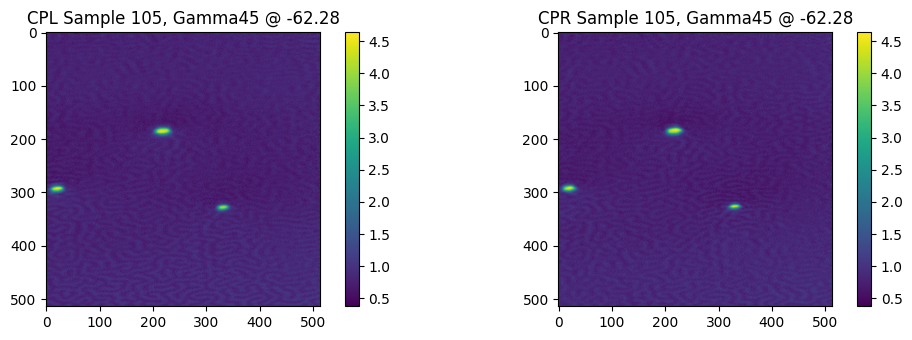

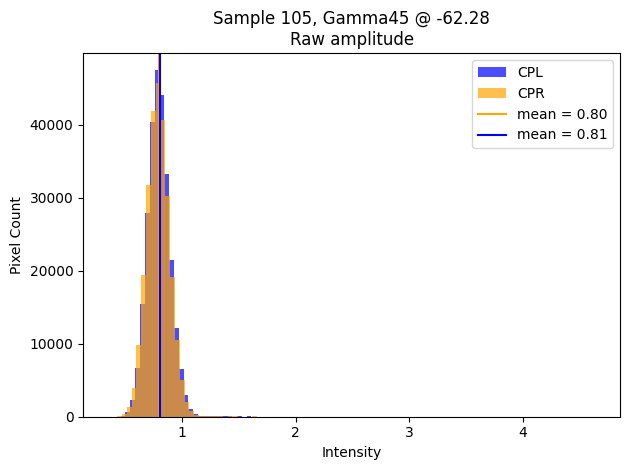

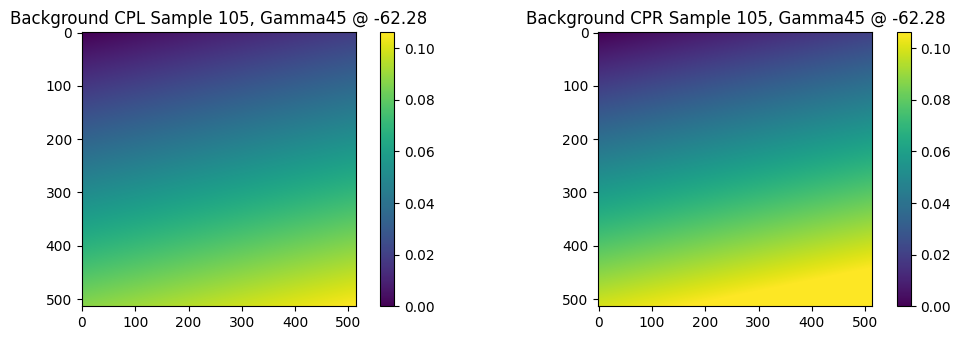

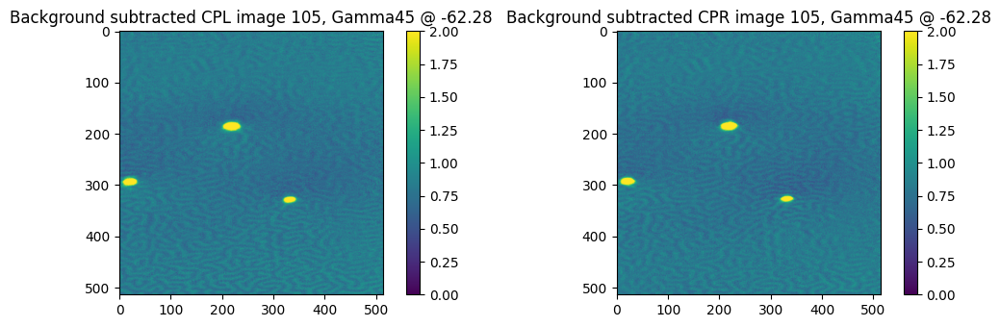

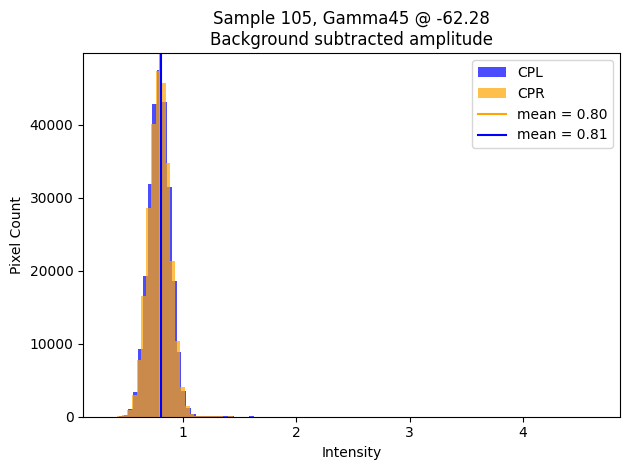

...

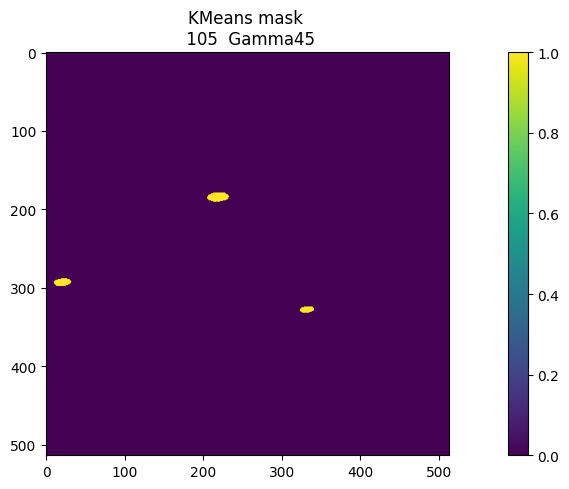

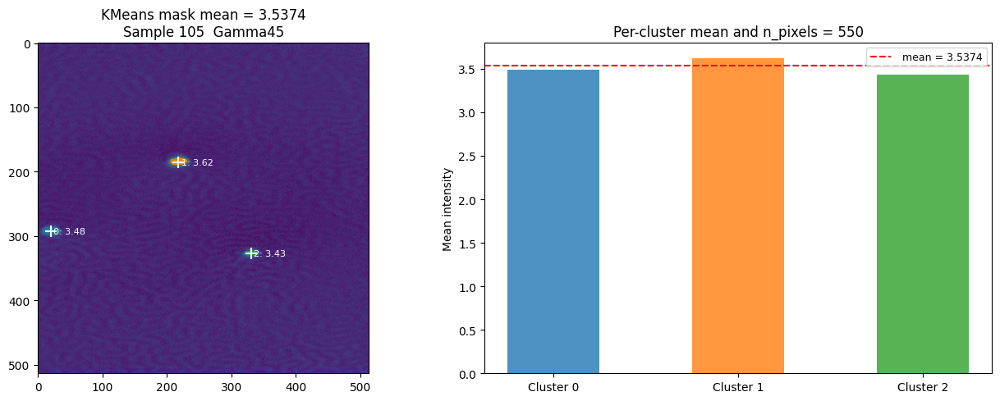

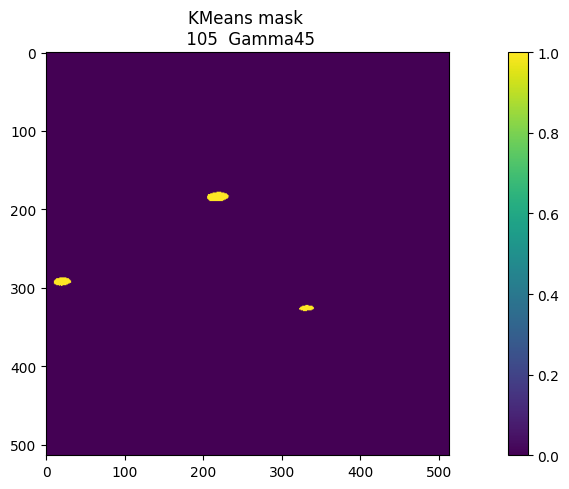

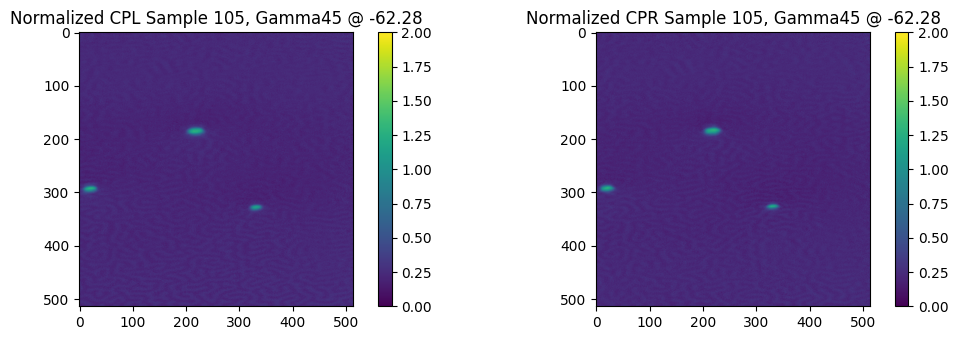

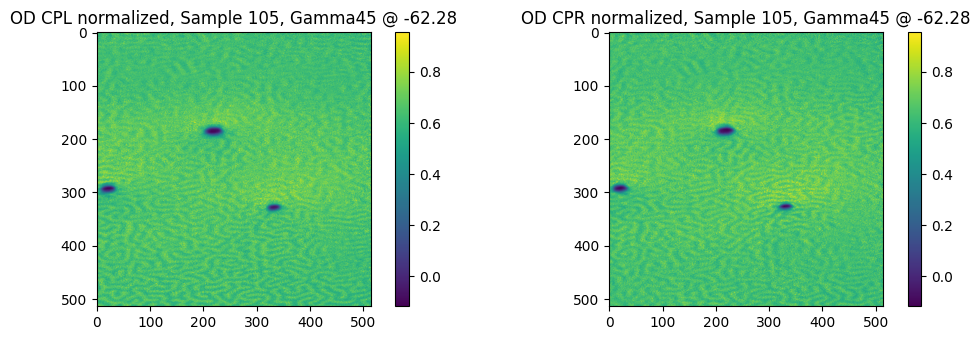

  Estimated translation: (-0.8652896486484849, -0.13285182644614935)


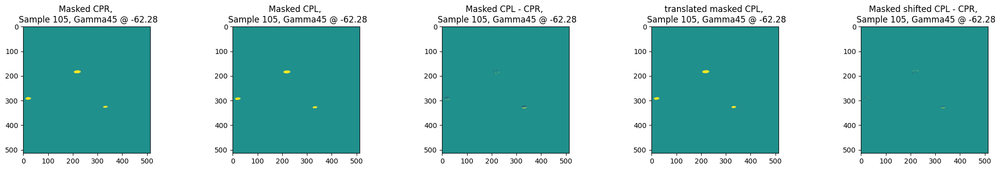

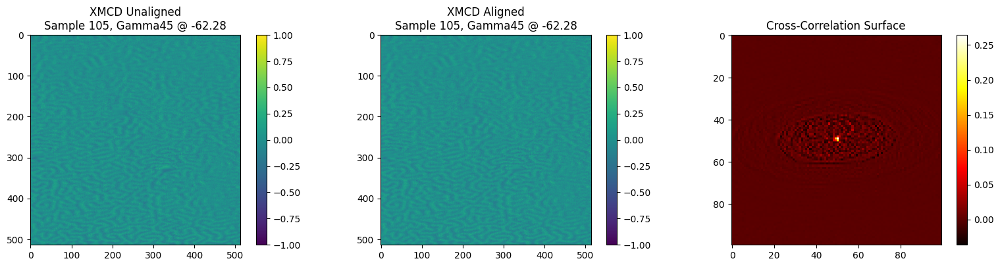

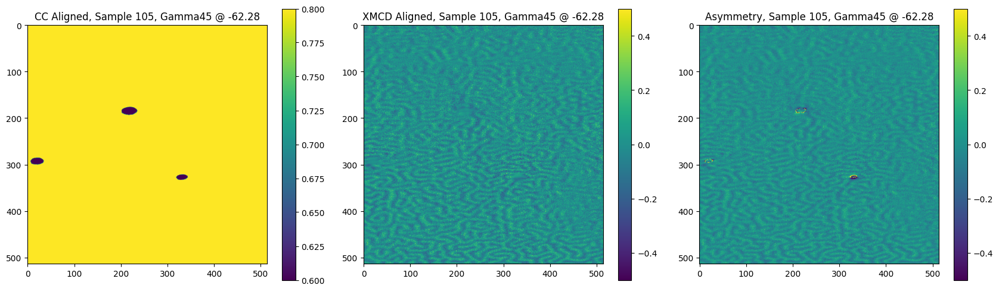

Rotation (deg): -0.12257532765929481
Translation (px): [-0.85468462  0.21793599]


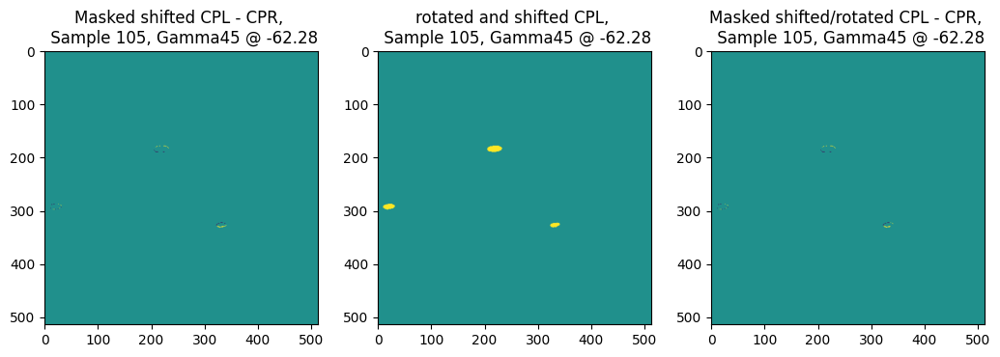

/tmp/ipykernel_4106217/254286374.py:243: RuntimeWarning: divide by zero encountered in log10
  CC = axes[0].imshow((-1 * np.log10(aligned_neg)) + OD_pos,
/tmp/ipykernel_4106217/254286374.py:247: RuntimeWarning: divide by zero encountered in log10
  XMCD = axes[1].imshow((-1 * np.log10(aligned_neg)) - OD_pos,
/tmp/ipykernel_4106217/254286374.py:252: RuntimeWarning: divide by zero encountered in log10
  asymm  = axes[2].imshow(((-1 * np.log10(aligned_neg)) - OD_pos)/((-1 * np.log10(aligned_neg)) + OD_pos),
/tmp/ipykernel_4106217/254286374.py:252: RuntimeWarning: invalid value encountered in divide
  asymm  = axes[2].imshow(((-1 * np.log10(aligned_neg)) - OD_pos)/((-1 * np.log10(aligned_neg)) + OD_pos),


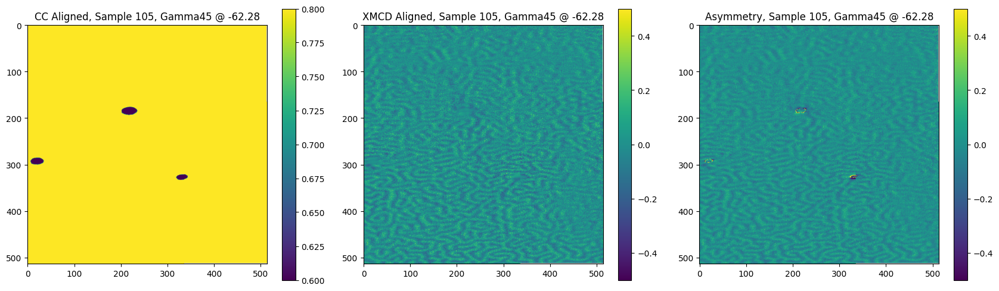

/tmp/ipykernel_4106217/254286374.py:261: RuntimeWarning: divide by zero encountered in log10
  CL = axes[0].plot(-1 * np.log10(aligned_neg))


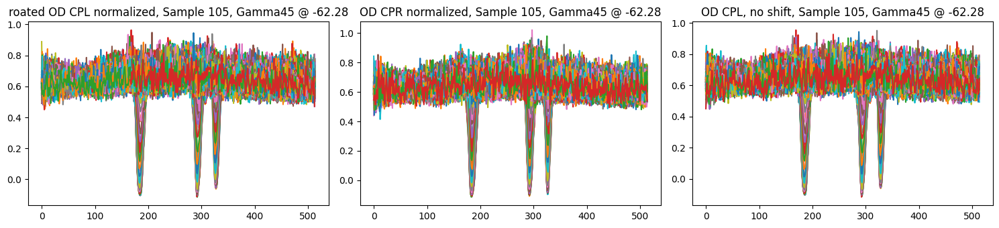

/tmp/ipykernel_4106217/254286374.py:271: RuntimeWarning: divide by zero encountered in log10
  OD_dif = (-1 * np.log10(aligned_neg)) - OD_pos
/tmp/ipykernel_4106217/254286374.py:272: RuntimeWarning: divide by zero encountered in log10
  CPL_diff = (-1 * np.log10(aligned_neg)) - OD_neg


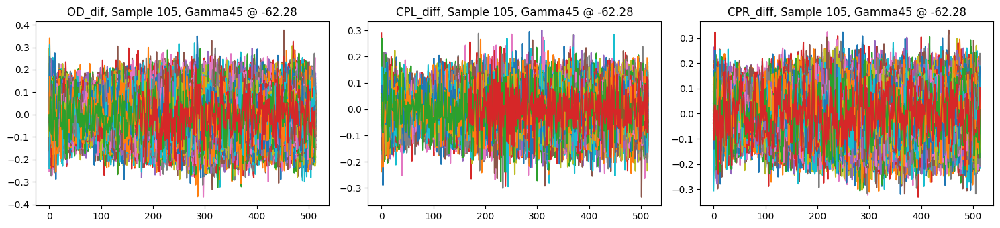

/homes/emma/code/Vector_Tomography/Functions.py:390: RuntimeWarning: invalid value encountered in log10
  return float(20 * np.log10(mean / std))


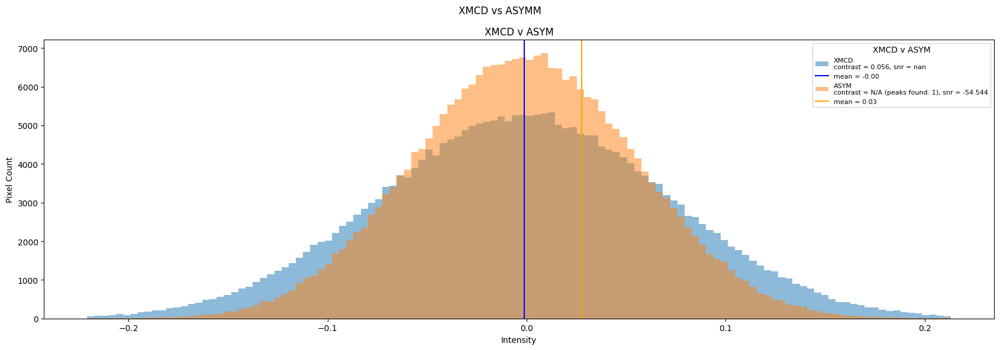

In [12]:
########### WITH CROSS CORR!!!  ############
angle = angles_pospol[k]
print(f"Previewing k={k} | pos={angles_pospol[k]:.2f} deg, neg={angles_negpol[k]:.2f} deg")

if single_scan == True: 
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]
    sample = '452, Ni'
else:
    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]

print(f'image min = {np.min(img_neg)} and max = {np.max(img_neg)}')

# 1. Raw amplitude images
norm_raw = mpl.colors.Normalize(vmin=np.min(img_neg), vmax=np.max(img_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(img_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(img_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

mean_CPL = np.mean(img_neg) 
mean_CPR = np.mean(img_pos)

# 3. Intensity histograms (raw)
# register.plot_histogram(
#     img_neg.flatten(), img_pos.flatten(), bin_size,
#     color_neg, color_pos,
#     angle=angle, sample=sample, Gamma=Gamma, 
#     label1 = 'CPL', label2 = 'CPR', title='Raw amplitude'
# )

label1 = 'CPL'
label2 = 'CPR'
title='Raw amplitude'

plt.figure()
plt.hist(img_neg.flatten(), bins=bin_size, color=color_neg, label=f'{label1}', alpha=0.7)
plt.hist(img_pos.flatten(), bins=bin_size, color=color_pos, label=f'{label2}', alpha=0.7)
plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
plt.axvline(mean_CPR, color = color_pos, label = f'mean = {mean_CPR:.2f}')
plt.axvline(mean_CPL, color = color_neg, label = f'mean = {mean_CPL:.2f}')
# plt.ylim(0, 1000)
plt.legend()
plt.title(f"Sample {sample}, {Gamma} @ {angle:.2f}\n{title}")
plt.tight_layout()
plt.show()


##########################################################################################################################
# Subtract background 
neg_background = register.fit_background(img_neg) 
pos_background = register.fit_background(img_pos) 

# Plot background
norm_raw = mpl.colors.Normalize(vmin=np.min(neg_background), vmax=np.max(neg_background))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(neg_background, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Background CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(pos_background, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Background CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# subtract background from raw data
img_neg = img_neg - neg_background
img_pos = img_pos - pos_background

# restore the original means 
img_neg = img_neg - np.mean(img_neg) + mean_CPL
img_pos = img_pos - np.mean(img_pos) + mean_CPR

# Plot background subtracted image
norm_raw = mpl.colors.Normalize(vmin=0, vmax=2)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(img_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Background subtracted CPL image {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(img_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Background subtracted CPR image {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

# 3. Intensity histograms (raw)
# register.plot_histogram(
#     img_neg.flatten(), img_pos.flatten(), bin_size,
#     color_neg, color_pos,
#     angle=angle, sample=sample, Gamma=Gamma, 
#     label1 = 'CPL', label2 = 'CPR', title='Background subtracted amplitude'
# )

label1 = 'CPL'
label2 = 'CPR'
title='Background subtracted amplitude'

mean_CPL = np.mean(img_neg) 
mean_CPR = np.mean(img_pos)

plt.figure()
plt.hist(img_neg.flatten(), bins=bin_size, color=color_neg, label=f'{label1}', alpha=0.7)
plt.hist(img_pos.flatten(), bins=bin_size, color=color_pos, label=f'{label2}', alpha=0.7)
plt.xlabel('Intensity')
plt.ylabel('Pixel Count')
plt.axvline(mean_CPR, color = color_pos, label = f'mean = {mean_CPR:.2f}')
plt.axvline(mean_CPL, color = color_neg, label = f'mean = {mean_CPL:.2f}')
# plt.ylim(0, 1000)
plt.legend()
plt.title(f"Sample {sample}, {Gamma} @ {angle:.2f}\n{title}")
plt.tight_layout()
plt.show()

##########################################################################################################################
# 4. Fiducial normalization
norm_neg, fid_mean_neg, neg_px, masked_neg = register.auto_normalize_by_fiducial_kmeans(
    img_neg,
    fiduc_num=fiduc_num,
    factor=set_factor,
    plot=PLOT_FIDUCIAL_HIST,
    sample=sample,
    Gamma=Gamma
)

norm_pos, fid_mean_pos, pos_px, masked_pos = register.auto_normalize_by_fiducial_kmeans(
    img_pos,
    fiduc_num=fiduc_num,
    factor=set_factor,
    plot=PLOT_FIDUCIAL_HIST,
    sample=sample,
    Gamma=Gamma
)


# 1. normalized amplitude images
norm_raw = mpl.colors.Normalize(vmin=0, vmax=2)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(norm_neg, norm=norm_raw)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"Normalized CPL Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(norm_pos, norm=norm_raw)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"Normalized CPR Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()


##########################################################################################################################
# 5. Optical density
OD_neg = -1 * np.log10(norm_neg)
OD_pos = -1 * np.log10(norm_pos)
norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
CL = axes[0].imshow(OD_neg, norm=norm_OD)
fig.colorbar(CL, ax=axes[0])
axes[0].set_title(f"OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].imshow(OD_pos, norm=norm_OD)
fig.colorbar(CR, ax=axes[1])
axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

##########################################################################################################################
# 7. Cross-correlation alignment
translation, corr = register.align_images_CC(masked_pos, masked_neg, bound_preview)
print(f"  Estimated translation: {translation}")

f_target         = fftn(norm_neg)
f_target_shifted = fourier_shift(f_target, translation)
translated_neg   = ifftn(f_target_shifted).real

## shift mask to also compare 
__, __, __, translated_neg_mask = register.auto_normalize_by_fiducial_kmeans(
    translated_neg, fiduc_num=fiduc_num, factor=set_factor,
    plot=False, sample=sample, Gamma=Gamma
)

# 6. Fiducial hole mask (binary)
# masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)
# Plot fiducial masks before and after CC
fig, axes = plt.subplots(1, 5, figsize=(21, 3.5))
axes[0].imshow(masked_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[0].set_title(f"Masked CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")
axes[1].imshow(masked_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[1].set_title(f"Masked CPL, \n Sample {sample}, {Gamma} @ {angle:.2f}")
diff = masked_neg.astype(int) - masked_pos.astype(int)
axes[2].imshow(diff, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[2].set_title(f"Masked CPL - CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")

axes[3].imshow(translated_neg_mask, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[3].set_title(f"translated masked CPL, \n Sample {sample}, {Gamma} @ {angle:.2f}")

diff_trans = translated_neg_mask.astype(int) - masked_pos.astype(int)
axes[4].imshow(diff_trans, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
axes[4].set_title(f"Masked shifted CPL - CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()


#### Look at the aligned vs unaligned XMCD ###
unaligned_diffMap = OD_neg - OD_pos
aligned_diffMap   = (-1 * np.log10(translated_neg)) - OD_pos

register.plot_XMCD_crosscorr(
    unaligned_diffMap, aligned_diffMap, corr,
    angle=angle, sample=sample, Gamma=Gamma
)

# 8. Aligned charge contrast
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

CC_L = (-1 * np.log10(translated_neg)) + OD_pos
CC = axes[0].imshow((-1 * np.log10(translated_neg)) + OD_pos,
            norm=mpl.colors.Normalize(vmin=0.6, vmax=0.8)) ########################################
axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(CC, ax=axes[0])

XMCD_L  = (-1 * np.log10(translated_neg)) - OD_pos
XMCD = axes[1].imshow((-1 * np.log10(translated_neg)) - OD_pos,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(XMCD, ax=axes[1])

ASYM_L = ((-1 * np.log10(translated_neg)) - OD_pos)/((-1 * np.log10(translated_neg)) + OD_pos)
asymm  = axes[2].imshow(((-1 * np.log10(translated_neg)) - OD_pos)/((-1 * np.log10(translated_neg)) + OD_pos),
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
axes[2].set_title(f"Asymmetry, Sample {sample}, {Gamma} @ {angle:.2f}")
fig.colorbar(asymm, ax=axes[2])

plt.tight_layout(); plt.show()



##########################################################################################################################

rotate = True 

if rotate == True: 
    aligned_neg, ___ = register.rotate_images_CC(masked_pos, translated_neg_mask, translated_neg, angle=angle, sample=sample, Gamma=Gamma, plot = True)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    CC = axes[0].imshow((-1 * np.log10(aligned_neg)) + OD_pos,
                norm=mpl.colors.Normalize(vmin=0.6, vmax=0.8))
    axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(CC, ax=axes[0])
    XMCD = axes[1].imshow((-1 * np.log10(aligned_neg)) - OD_pos,
                norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
    axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(XMCD, ax=axes[1])

    asymm  = axes[2].imshow(((-1 * np.log10(aligned_neg)) - OD_pos)/((-1 * np.log10(aligned_neg)) + OD_pos),
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
    axes[2].set_title(f"Asymmetry, Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(asymm, ax=axes[2])

    plt.tight_layout(); plt.show()


fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
CL = axes[0].plot(-1 * np.log10(aligned_neg))
axes[0].set_title(f"roated OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].plot(OD_pos)
axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
l = axes[2].plot(OD_neg)
axes[2].set_title(f"OD CPL, no shift, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))

OD_dif = (-1 * np.log10(aligned_neg)) - OD_pos
CPL_diff = (-1 * np.log10(aligned_neg)) - OD_neg
CPR_diff = OD_neg - OD_pos

CL = axes[0].plot(OD_dif)
axes[0].set_title(f"OD_dif, Sample {sample}, {Gamma} @ {angle:.2f}")
CR = axes[1].plot(CPL_diff)
axes[1].set_title(f"CPL_diff, Sample {sample}, {Gamma} @ {angle:.2f}")
l = axes[2].plot(CPR_diff)
axes[2].set_title(f"CPR_diff, Sample {sample}, {Gamma} @ {angle:.2f}")
plt.tight_layout(); plt.show()

############################################################################################################# 

compare_dict = {
    "XMCD v ASYM": {
        "XMCD": XMCD_L,
        "ASYM": ASYM_L,
    }
}

hist_colors = {
    "XMCD": "#1f77b4",  # blue
    "ASYM": "#ff7f0e",   # orange
}

mean_line_colors = {
    "XMCD": "blue",   # or color_pos
    "ASYM": "orange",      # or color_neg
}

register.plot_hist_compare_dict(
    compare_dict=compare_dict,
    bins=120,
    robust_range_pct=(0.1, 99.9),
    shared_range=True,
    report_clipped=True,
    use_safe_peak_contrast=True,   # <- your requested behavior
    peak_prominence=None,          # or set e.g. 200
    peak_distance=5,
    figsize=(17, 6),
    show_mean_lines=True, 
    hist_colors=hist_colors,
    mean_line_colors=mean_line_colors,
    suptitle="XMCD vs ASYMM"
)


#### compare contrast of CPL and CPR for with and without light on

In [ ]:
k = 0
if systematic_noise == True: 

    angle = noise_compare_angle_pospol[k]
    print(f"Previewing k={k} | pos={noise_compare_angle_pospol[k]:.2f} deg, neg={noise_compare_angle_negpol[k]:.2f} deg")
    
    img_neg = noise_compare_negpol[k]
    img_pos = noise_compare_pospol[k]

    print(img_neg.shape)
    
    print(f'image min = {np.min(img_neg)} and max = {np.max(img_neg)}')
    
    # 1. Raw amplitude images
    norm_raw = mpl.colors.Normalize(vmin=np.min(img_neg), vmax=np.max(img_neg))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    CL = axes[0].imshow(img_neg, norm=norm_raw)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"CPL Sample {sample}, {Gamma} @ {angle:.2f}")
    CR = axes[1].imshow(img_pos, norm=norm_raw)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"CPR Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()
    
    mean_CPL = np.mean(img_neg) 
    mean_CPR = np.mean(img_pos)
    
    # 3. Intensity histograms (raw)
    # register.plot_histogram(
    #     img_neg.flatten(), img_pos.flatten(), bin_size,
    #     color_neg, color_pos,
    #     angle=angle, sample=sample, Gamma=Gamma, 
    #     label1 = 'CPL', label2 = 'CPR', title='Raw amplitude'
    # )
    
    label1 = 'CPL'
    label2 = 'CPR'
    title='Raw amplitude'
    
    plt.figure()
    plt.hist(img_neg.flatten(), bins=bin_size, color=color_neg, label=f'{label1}', alpha=0.7)
    plt.hist(img_pos.flatten(), bins=bin_size, color=color_pos, label=f'{label2}', alpha=0.7)
    plt.xlabel('Intensity')
    plt.ylabel('Pixel Count')
    plt.axvline(mean_CPR, color = color_pos, label = f'mean = {mean_CPR:.2f}')
    plt.axvline(mean_CPL, color = color_neg, label = f'mean = {mean_CPL:.2f}')
    # plt.ylim(0, 1000)
    plt.legend()
    plt.title(f"Sample {sample}, {Gamma} @ {angle:.2f}\n{title}")
    plt.tight_layout()
    plt.show()
    
    
    ##########################################################################################################################
    # Subtract background 
    neg_background = register.fit_background(img_neg) 
    pos_background = register.fit_background(img_pos) 
    
    # Plot background
    norm_raw = mpl.colors.Normalize(vmin=np.min(neg_background), vmax=np.max(neg_background))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    CL = axes[0].imshow(neg_background, norm=norm_raw)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"Background CPL Sample {sample}, {Gamma} @ {angle:.2f}")
    CR = axes[1].imshow(pos_background, norm=norm_raw)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"Background CPR Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()
    
    # subtract background from raw data
    img_neg = img_neg - neg_background
    img_pos = img_pos - pos_background
    
    # restore the original means 
    img_neg = img_neg - np.mean(img_neg) + mean_CPL
    img_pos = img_pos - np.mean(img_pos) + mean_CPR
    
    # Plot background subtracted image
    norm_raw = mpl.colors.Normalize(vmin=0, vmax=2)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    CL = axes[0].imshow(img_neg, norm=norm_raw)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"Background subtracted CPL image {sample}, {Gamma} @ {angle:.2f}")
    CR = axes[1].imshow(img_pos, norm=norm_raw)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"Background subtracted CPR image {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()
    
    # 3. Intensity histograms (raw)
    # register.plot_histogram(
    #     img_neg.flatten(), img_pos.flatten(), bin_size,
    #     color_neg, color_pos,
    #     angle=angle, sample=sample, Gamma=Gamma, 
    #     label1 = 'CPL', label2 = 'CPR', title='Background subtracted amplitude'
    # )
    
    label1 = 'CPL'
    label2 = 'CPR'
    title='Background subtracted amplitude'
    
    mean_CPL = np.mean(img_neg) 
    mean_CPR = np.mean(img_pos)
    
    plt.figure()
    plt.hist(img_neg.flatten(), bins=bin_size, color=color_neg, label=f'{label1}', alpha=0.7)
    plt.hist(img_pos.flatten(), bins=bin_size, color=color_pos, label=f'{label2}', alpha=0.7)
    plt.xlabel('Intensity')
    plt.ylabel('Pixel Count')
    plt.axvline(mean_CPR, color = color_pos, label = f'mean = {mean_CPR:.2f}')
    plt.axvline(mean_CPL, color = color_neg, label = f'mean = {mean_CPL:.2f}')
    # plt.ylim(0, 1000)
    plt.legend()
    plt.title(f"Sample {sample}, {Gamma} @ {angle:.2f}\n{title}")
    plt.tight_layout()
    plt.show()
    
    ##########################################################################################################################
    # 4. Fiducial normalization
    norm_neg, fid_mean_neg, neg_px, masked_neg = register.auto_normalize_by_fiducial_kmeans(
        img_neg,
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=PLOT_FIDUCIAL_HIST,
        sample=sample,
        Gamma=Gamma
    )
    
    norm_pos, fid_mean_pos, pos_px, masked_pos = register.auto_normalize_by_fiducial_kmeans(
        img_pos,
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=PLOT_FIDUCIAL_HIST,
        sample=sample,
        Gamma=Gamma
    )
    
    
    # 1. normalized amplitude images
    norm_raw = mpl.colors.Normalize(vmin=0, vmax=2)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    CL = axes[0].imshow(norm_neg, norm=norm_raw)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"Normalized CPL Sample {sample}, {Gamma} @ {angle:.2f}")
    CR = axes[1].imshow(norm_pos, norm=norm_raw)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"Normalized CPR Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()
    
    
    ##########################################################################################################################
    # 5. Optical density
    OD_neg = -1 * np.log(norm_neg)
    OD_pos = -1 * np.log(norm_pos)
    norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    CL = axes[0].imshow(OD_neg, norm=norm_OD)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
    CR = axes[1].imshow(OD_pos, norm=norm_OD)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()
    
    ##########################################################################################################################
    # 7. Cross-correlation alignment
    translation, corr = register.align_images_CC(masked_pos, masked_neg, bound_preview)
    print(f"  Estimated translation: {translation}")
    
    f_target         = fftn(norm_neg)
    f_target_shifted = fourier_shift(f_target, translation)
    translated_neg   = ifftn(f_target_shifted).real
    
    ## shift mask to also compare 
    __, __, __, translated_neg_mask = register.auto_normalize_by_fiducial_kmeans(
        translated_neg, fiduc_num=fiduc_num, factor=set_factor,
        plot=False, sample=sample, Gamma=Gamma
    )
    
    # 6. Fiducial hole mask (binary)
    # masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)
    # Plot fiducial masks before and after CC
    fig, axes = plt.subplots(1, 5, figsize=(21, 3.5))
    axes[0].imshow(masked_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    axes[0].set_title(f"Masked CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")
    axes[1].imshow(masked_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    axes[1].set_title(f"Masked CPL, \n Sample {sample}, {Gamma} @ {angle:.2f}")
    diff = masked_neg.astype(int) - masked_pos.astype(int)
    axes[2].imshow(diff, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    axes[2].set_title(f"Masked CPL - CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")
    
    axes[3].imshow(translated_neg_mask, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    axes[3].set_title(f"translated masked CPL, \n Sample {sample}, {Gamma} @ {angle:.2f}")
    
    diff_trans = translated_neg_mask.astype(int) - masked_pos.astype(int)
    axes[4].imshow(diff_trans, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    axes[4].set_title(f"Masked shifted CPL - CPR, \n Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()
    
    
    #### Look at the aligned vs unaligned XMCD ###
    unaligned_diffMap = OD_neg - OD_pos
    aligned_diffMap   = (-1 * np.log(translated_neg)) - OD_pos
    
    register.plot_XMCD_crosscorr(
        unaligned_diffMap, aligned_diffMap, corr,
        angle=angle, sample=sample, Gamma=Gamma
    )
    
    # 8. Aligned charge contrast
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    CC_NL = (-1 * np.log(translated_neg)) + OD_pos
    CC = axes[0].imshow((-1 * np.log(translated_neg)) + OD_pos,
                norm=mpl.colors.Normalize(vmin=0.8, vmax=1))
    axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(CC, ax=axes[0])

    XMCD_NL = (-1 * np.log(translated_neg)) - OD_pos
    XMCD = axes[1].imshow((-1 * np.log(translated_neg)) - OD_pos,
                norm=mpl.colors.Normalize(vmin=-10, vmax=10))
    axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(XMCD, ax=axes[1])

    ASYM_NL = ((-1 * np.log(translated_neg)) - OD_pos)/((-1 * np.log(translated_neg)) + OD_pos)
    asymm  = axes[2].imshow(ASYM_NL,
                norm=mpl.colors.Normalize(vmin=-10, vmax=10))
    axes[2].set_title(f"Asymmetry, Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(asymm, ax=axes[2])
    
    plt.tight_layout(); plt.show()
    
    ##########################################################################################################################

    
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    CL = axes[0].plot(-1 * np.log(translated_neg))
    axes[0].set_title(f"roated OD CPL normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
    CR = axes[1].plot(OD_pos)
    axes[1].set_title(f"OD CPR normalized, Sample {sample}, {Gamma} @ {angle:.2f}")
    l = axes[2].plot(OD_neg)
    axes[2].set_title(f"OD CPL, no shift, Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    
    OD_dif = (-1 * np.log(translated_neg)) - OD_pos
    CPL_diff = (-1 * np.log(translated_neg)) - OD_neg
    CPR_diff = OD_neg - OD_pos
    
    CL = axes[0].plot(OD_dif)
    axes[0].set_title(f"OD_dif, Sample {sample}, {Gamma} @ {angle:.2f}")
    CR = axes[1].plot(CPL_diff)
    axes[1].set_title(f"CPL_diff, Sample {sample}, {Gamma} @ {angle:.2f}")
    l = axes[2].plot(CPR_diff)
    axes[2].set_title(f"CPR_diff, Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()

########################################################################################################################



In [ ]:

# from scipy.signal import find_peaks

# def _safe_peak_contrast(vals, bins=256, hist_range=None, prominence=None, distance=None):
#     """
#     Returns:
#         contrast (float or None), n_peaks (int), peak_positions (np.ndarray)
#     Contrast is abs difference between the two furthest detected peak centers.
#     """
#     vals = np.asarray(vals).ravel()
#     vals = vals[np.isfinite(vals)]
#     if vals.size == 0:
#         return None, 0, np.array([])

#     counts, edges = np.histogram(vals, bins=bins, range=hist_range)
#     centers = 0.5 * (edges[:-1] + edges[1:])

#     # Reasonable default prominence if not provided
#     if prominence is None:
#         prominence = 0.05 * np.max(counts) if np.max(counts) > 0 else 1

#     peak_idx, _ = find_peaks(counts, prominence=prominence, distance=distance)
#     n_peaks = len(peak_idx)

#     if n_peaks < 2:
#         return None, n_peaks, centers[peak_idx]

#     peak_pos = np.sort(centers[peak_idx])
#     contrast = float(peak_pos[-1] - peak_pos[0])  # two furthest peaks
#     return contrast, n_peaks, peak_pos


# def plot_hist_compare_dict(
#     compare_dict,
#     bins=100,
#     alpha=0.5,
#     figsize=(12, 6),
#     show_mean_lines=True,
#     mean_line_colors=None,
#     hist_colors=None,
#     suptitle=None,
#     legend_fontsize=8
# ):
#     """
#     Plot histogram comparisons for multiple groups (e.g., CPL, CPR).

#     Parameters
#     ----------
#     compare_dict : dict
#         Structure:
#         {
#           "CPL": {"light off": img_array, "light on": img_array},
#           "CPR": {"light off": img_array, "light on": img_array},
#           ...
#         }
#     bins : int
#     alpha : float
#     figsize : tuple
#     show_mean_lines : bool
#     mean_line_colors : dict or None
#         e.g. {"light off": "orange", "light on": "blue"}
#     hist_colors : dict or None
#         e.g. {"light off": "#1f77b4", "light on": "#ff7f0e"}
#     suptitle : str or None
#     legend_fontsize : int
#     """
#     group_names = list(compare_dict.keys())
#     n_groups = len(group_names)

#     fig, axes = plt.subplots(1, n_groups, figsize=figsize, squeeze=False)
#     axes = axes[0]

#     for i, group in enumerate(group_names):
#         ax = axes[i]
#         condition_dict = compare_dict[group]  # e.g. {"light off": arr, "light on": arr}

#         for cond_name, img in condition_dict.items():
#             vals = np.asarray(img).ravel()
#             mean_val = np.mean(vals)
#             # contrast = register.xmcd_peak_separation(img)
#             # snr = register.snr_db(img)
#             lo, hi = np.percentile(vals, [0.1, 99.9])   # adjust as needed


#             hcolor = hist_colors.get(cond_name) if hist_colors else None
#             ax.hist(
#                 vals,
#                 bins=bins,
#                 alpha=alpha,
#                 color=hcolor,
#                 range=(lo, hi)
#                 #label=f"{cond_name}\ncontrast = {contrast:.3f}, snr = {snr:.3f}"
#             )

#             if show_mean_lines:
#                 mcolor = mean_line_colors.get(cond_name) if mean_line_colors else None
#                 ax.axvline(
#                     mean_val,
#                     color=mcolor,
#                     linestyle='-',
#                     linewidth=1.5,
#                     #label=f"mean = {mean_val:.2f}"
#                 )

#         ax.set_title(group)
#         ax.set_xlabel("Intensity")
#         ax.set_ylabel("Pixel Count")
#         ax.legend(title=group, fontsize=legend_fontsize)

#     if suptitle is not None:
#         fig.suptitle(suptitle)

#     plt.tight_layout()
#     plt.show()




# def plot_hist_compare_dict(
#     compare_dict,
#     bins=100,
#     alpha=0.5,
#     figsize=(12, 6),
#     show_mean_lines=True,
#     mean_line_colors=None,
#     hist_colors=None,
#     suptitle=None,
#     legend_fontsize=8,
#     # robust/cropping options
#     robust_range_pct=None,   # e.g. (1, 99)
#     shared_range=True,
#     report_clipped=False,
#     # contrast peak detection options
#     use_safe_peak_contrast=True,
#     peak_prominence=None,
#     peak_distance=None,
#     contrast_hist_bins=256
# ):
#     """
#     compare_dict format:
#     {
#       "CPL": {"light off": arr, "light on": arr},
#       "CPR": {"light off": arr, "light on": arr},
#     }
#     """
#     group_names = list(compare_dict.keys())
#     n_groups = len(group_names)

#     # Build shared robust range if requested
#     global_lohi = None
#     if robust_range_pct is not None and shared_range:
#         all_vals = []
#         for g in group_names:
#             for _, img in compare_dict[g].items():
#                 v = np.asarray(img).ravel()
#                 v = v[np.isfinite(v)]
#                 if v.size:
#                     all_vals.append(v)
#         if all_vals:
#             all_concat = np.concatenate(all_vals)
#             lo, hi = np.percentile(all_concat, robust_range_pct)
#             global_lohi = (lo, hi)

#     fig, axes = plt.subplots(1, n_groups, figsize=figsize, squeeze=False)
#     axes = axes[0]

#     for i, group in enumerate(group_names):
#         ax = axes[i]
#         condition_dict = compare_dict[group]

#         # Per-group range if not shared
#         group_lohi = None
#         if robust_range_pct is not None and not shared_range:
#             gvals = []
#             for _, img in condition_dict.items():
#                 v = np.asarray(img).ravel()
#                 v = v[np.isfinite(v)]
#                 if v.size:
#                     gvals.append(v)
#             if gvals:
#                 gc = np.concatenate(gvals)
#                 lo, hi = np.percentile(gc, robust_range_pct)
#                 group_lohi = (lo, hi)

#         hist_range = global_lohi if global_lohi is not None else group_lohi

#         for cond_name, img in condition_dict.items():
#             vals = np.asarray(img).ravel()
#             vals = vals[np.isfinite(vals)]
#             if vals.size == 0:
#                 continue

#             mean_val = np.mean(vals)
#             snr = register.snr_db(img)

#             # Contrast logic
#             if use_safe_peak_contrast:
#                 contrast, n_peaks, _ = _safe_peak_contrast(
#                     vals,
#                     bins=contrast_hist_bins,
#                     hist_range=hist_range,
#                     prominence=peak_prominence,
#                     distance=peak_distance
#                 )
#                 if contrast is None:
#                     contrast_txt = f"contrast = N/A (peaks found: {n_peaks})"
#                 else:
#                     contrast_txt = f"contrast = {contrast:.3f}"
#             else:
#                 # fallback to your existing method
#                 contrast = register.xmcd_peak_separation(img)
#                 contrast_txt = f"contrast = {contrast:.3f}"

#             # Optional clipped counts for displayed histogram
#             clip_txt = ""
#             if report_clipped and hist_range is not None:
#                 lo, hi = hist_range
#                 n_low = int(np.sum(vals < lo))
#                 n_high = int(np.sum(vals > hi))
#                 #clip_txt = f"\nclipped low/high = {n_low}/{n_high}"

#             hcolor = hist_colors.get(cond_name) if hist_colors else None
#             ax.hist(
#                 vals,
#                 bins=bins,
#                 range=hist_range,
#                 alpha=alpha,
#                 color=hcolor,
#                 label=f"{cond_name}\n{contrast_txt}, snr = {snr:.3f}"
#             )

#             if show_mean_lines:
#                 mcolor = mean_line_colors.get(cond_name) if mean_line_colors else None
#                 ax.axvline(
#                     mean_val,
#                     color=mcolor,
#                     linestyle='-',
#                     linewidth=1.5,
#                     label=f"mean = {mean_val:.2f}"
#                 )

#         ax.set_title(group)
#         ax.set_xlabel("Intensity")
#         ax.set_ylabel("Pixel Count")
#         ax.legend(title=group, fontsize=legend_fontsize)

#     if suptitle is not None:
#         fig.suptitle(suptitle)

#     plt.tight_layout()
#     plt.show()

In [ ]:
CPL_NL = noise_compare_negpol[0]
CPR_NL = noise_compare_pospol[0]

CPL_L = image_stack_negpol[24]
CPR_L = image_stack_pospol[24]

compare_dict = {
    "CPL": {
        "light off": CPL_NL,
        "light on": CPL_L,
    },
    "CPR": {
        "light off": CPR_NL,
        "light on": CPR_L,
    }
}

hist_colors = {
    "light off": "#1f77b4",  # blue
    "light on": "#ff7f0e",   # orange
}

mean_line_colors = {
    "light off": "blue",   # or color_pos
    "light on": "orange",      # or color_neg
}

# plot_hist_compare_dict(
#     compare_dict=compare_dict,
#     bins=100,
#     alpha=0.5,
#     figsize=(14, 6),
#     show_mean_lines=True,
#     hist_colors=hist_colors,
#     mean_line_colors=mean_line_colors,
#     suptitle="Light Off vs Light On"
# )

register.plot_hist_compare_dict(
    compare_dict=compare_dict,
    bins=120,
    robust_range_pct=(0.1, 99.9),
    shared_range=True,
    report_clipped=True,
    use_safe_peak_contrast=True,   # <- your requested behavior
    peak_prominence=None,          # or set e.g. 200
    peak_distance=5,
    figsize=(12, 6),
    show_mean_lines=True, 
    hist_colors=hist_colors,
    mean_line_colors=mean_line_colors,
    suptitle="Light Off vs Light On"
)

In [ ]:
compare_dict = {
    "CC": {
        "light off": CC_NL,
        "light on": CC_L,
    },
    "XMCD": {
        "light off": XMCD_NL,
        "light on": XMCD_L,
    }, 
    "ASYMM": {
        "light off": ASYM_NL,
        "light on": ASYM_L,
    }
}

hist_colors = {
    "light off": "#1f77b4",  # blue
    "light on": "#ff7f0e",   # orange
}

mean_line_colors = {
    "light off": "blue",   # or color_pos
    "light on": "orange",      # or color_neg
}

# plot_hist_compare_dict(
#     compare_dict=compare_dict,
#     bins=100,
#     alpha=0.5,
#     figsize=(14, 6),
#     show_mean_lines=True,
#     hist_colors=hist_colors,
#     mean_line_colors=mean_line_colors,
#     suptitle="Light Off vs Light On"
# )

register.plot_hist_compare_dict(
    compare_dict=compare_dict,
    bins=120,
    robust_range_pct=(0.1, 99.9),
    shared_range=True,
    report_clipped=True,
    use_safe_peak_contrast=True,   # <- your requested behavior
    peak_prominence=None,          # or set e.g. 200
    peak_distance=5,
    figsize=(17, 6),
    show_mean_lines=True, 
    hist_colors=hist_colors,
    mean_line_colors=mean_line_colors,
    suptitle="Light Off vs Light On"
)

In [ ]:
compare_dict = {
    "Light Off": {
        "XMCD": XMCD_NL,
        "ASYM": ASYM_NL,
    }, 
    "Light On": {
        "XMCD": XMCD_L,
        "ASYM": ASYM_L,
    }
}

hist_colors = {
    "light off": "#1f77b4",  # blue
    "light on": "#ff7f0e",   # orange
}

mean_line_colors = {
    "light off": "blue",   # or color_pos
    "light on": "orange",      # or color_neg
}

# plot_hist_compare_dict(
#     compare_dict=compare_dict,
#     bins=100,
#     alpha=0.5,
#     figsize=(14, 6),
#     show_mean_lines=True,
#     hist_colors=hist_colors,
#     mean_line_colors=mean_line_colors,
#     suptitle="Light Off vs Light On"
# )

register.plot_hist_compare_dict(
    compare_dict=compare_dict,
    bins=120,
    robust_range_pct=(0.1, 99.9),
    shared_range=True,
    report_clipped=True,
    use_safe_peak_contrast=True,   # <- your requested behavior
    peak_prominence=None,          # or set e.g. 200
    peak_distance=5,
    figsize=(17, 6),
    show_mean_lines=True, 
    hist_colors=hist_colors,
    mean_line_colors=mean_line_colors,
    suptitle="XMCD vs ASYMM"
)

## compare normalization schemes

In [ ]:
fid_amp_neg = []
fid_amp_neg_px = []
fid_amp_pos = []
fid_amp_pos_px = []
norm_max_neg = [] 
norm_max_pos = []
norm_avg_neg = [] 
norm_avg_pos = []

fid_amp_neg_hp = []
fid_amp_neg_px_hp = []
fid_amp_pos_hp = []
fid_amp_pos_px_hp = []
norm_max_neg_hp = [] 
norm_max_pos_hp = []
norm_avg_neg_hp = [] 
norm_avg_pos_hp = []


fid_amp_neg_k = []
fid_amp_neg_px_k = []
fid_amp_pos_k = []
fid_amp_pos_px_k = []
norm_max_neg_k = [] 
norm_max_pos_k = []
norm_avg_neg_k = [] 
norm_avg_pos_k = []

# fid_amp_neg_max = [ ]
# fid_amp_pos_max = [ ]

# fid_amp_neg_max_norm = [ ]
# fid_amp_pos_max_norm = [ ]


for k in range(image_stack_pospol.shape[0]):

    # fid_amp_neg_max.append(np.max(image_stack_negpol[k]))
    # fid_amp_pos_max.append(np.max(image_stack_pospol[k]))

    # 5 stdev threshold
    norm_neg_test, fid_avg_neg, neg_px, __, ___, ___ = register.auto_normalize_by_fiducial_threshold(image_stack_negpol[k], color_neg, bins=bin_size,plot_hist=False)
    norm_pos_test, fid_avg_pos,pos_px, __, ___, ___ = register.auto_normalize_by_fiducial_threshold(image_stack_pospol[k], color_pos, bins=bin_size, plot_hist=False)

    fid_amp_neg.append(fid_avg_neg)
    fid_amp_pos.append(fid_avg_pos)
    fid_amp_neg_px.append(neg_px)
    fid_amp_pos_px.append(pos_px)
    norm_max_neg.append(np.max(norm_neg_test))
    norm_max_pos.append(np.max(norm_pos_test))
    norm_avg_neg.append(np.mean(norm_neg_test))
    norm_avg_pos.append(np.mean(norm_pos_test))

    # highest peak (hp)
    norm_neg_hp, fid_avg_neg_hp, neg_px_hp = register.auto_normalize_by_fiducial(
    image_stack_negpol[k], color_neg, bins=bin_size, plot_hist=False
    )
    norm_pos_hp, fid_avg_pos_hp, pos_px_hp = register.auto_normalize_by_fiducial(
        image_stack_pospol[k], color_pos, bins=bin_size, plot_hist=False
    )

    fid_amp_neg_hp.append(fid_avg_neg_hp)
    fid_amp_pos_hp.append(fid_avg_pos_hp)
    fid_amp_neg_px_hp.append(neg_px_hp)
    fid_amp_pos_px_hp.append(pos_px_hp)
    norm_max_neg_hp.append(np.max(norm_neg_hp))
    norm_max_pos_hp.append(np.max(norm_pos_hp))
    norm_avg_neg_hp.append(np.mean(norm_neg_hp))
    norm_avg_pos_hp.append(np.mean(norm_pos_hp))

    # k means
    norm_neg_k, fid_mean_neg_k, neg_px_k = register.auto_normalize_by_fiducial_kmeans(
        image_stack_negpol[k],
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    norm_pos_k, fid_mean_pos_k, pos_px_k = register.auto_normalize_by_fiducial_kmeans(
        image_stack_pospol[k],
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=False,
        sample=sample,
        Gamma=Gamma
    )

    fid_amp_neg_k.append(fid_mean_neg_k)
    fid_amp_pos_k.append(fid_mean_pos_k)
    fid_amp_neg_px_k.append(neg_px_k)
    fid_amp_pos_px_k.append(pos_px_k)
    norm_max_neg_k.append(np.max(norm_neg_k))
    norm_max_pos_k.append(np.max(norm_pos_k))
    norm_avg_neg_k.append(np.mean(norm_neg_k))
    norm_avg_pos_k.append(np.mean(norm_pos_k))

plt.figure(figsize=(10, 4))

plt.plot(angles_negpol, fid_amp_neg_hp,  color='green', label='CPL, highest peak')
plt.plot(angles_pospol, fid_amp_pos_hp, color='red', label='CPR, highest peak')

plt.plot(angles_negpol, fid_amp_neg,  color='tab:green', label='CPL, threshold')
plt.plot(angles_pospol, fid_amp_pos, color='tab:red', label='CPR, threshold')

plt.plot(angles_negpol, fid_amp_neg_k,  color='limegreen', label='CPL, kmeans')
plt.plot(angles_pospol, fid_amp_pos_k, color='hotpink', label='CPR, kmeans')

plt.xlabel('Tilt angle (deg)')
plt.ylabel('I0')
# plt.axvline(angles_pospol[15], color = 'red')
# plt.axvline(angles_pospol[16], color = 'red')
plt.title(f"I0 vs. Tilt Angle, Sample {sample}, {Gamma} \n (threshold normalization scheme)")
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(angles_negpol, fid_amp_neg_px_hp,  color='green', label='# pix CPL, highest peak')
plt.plot(angles_pospol, fid_amp_pos_px_hp, color='red', label='# pix CPR, highest peak')

plt.plot(angles_negpol, fid_amp_neg_px,  color='tab:green', label='# pix CPL, threshold')
plt.plot(angles_pospol, fid_amp_pos_px, color='tab:red', label='# pix CPR, threshold')

plt.plot(angles_negpol, fid_amp_neg_px_k,  color='limegreen', label='# pix CPL, kmeans')
plt.plot(angles_pospol, fid_amp_pos_px_k, color='hotpink', label='# pix CPR, kmeans')

plt.xlabel('Tilt angle (deg)')
plt.ylabel('# pix')
plt.title(f"I0 vs. Tilt Angle, Sample {sample}, {Gamma}")
plt.legend(loc = 'upper right')
plt.tight_layout()  
plt.show()


plt.figure(figsize=(10, 4))

plt.plot(angles_negpol, norm_max_neg_hp,  color='green', label='CPL, highest peak')
plt.plot(angles_pospol, norm_max_pos_hp, color='red', label='CPR, highest peak')

plt.plot(angles_negpol, norm_max_neg,  color='tab:green', label='CPL, threshold')
plt.plot(angles_pospol, norm_max_pos, color='tab:red', label='CPR, threshold')

plt.plot(angles_negpol, norm_max_neg_k,  color='limegreen', label='CPL, kmeans')
plt.plot(angles_pospol, norm_max_pos_k, color='hotpink', label='CPR, kmeans')

plt.xlabel('Tilt angle (deg)')
plt.ylabel('Intensity')
plt.title(f"Max normalized Intensity vs. Tilt Angle, Sample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()  
plt.show()


plt.figure(figsize=(10, 4))

plt.plot(angles_negpol, norm_avg_neg_hp,  color='green', label='CPL, highest peak')
plt.plot(angles_pospol, norm_avg_pos_hp, color='red', label='CPR, highest peak')

plt.plot(angles_negpol, norm_avg_neg,  color='tab:green', label='CPL, threshold')
plt.plot(angles_pospol, norm_avg_pos, color='tab:red', label='CPR, threshold')

plt.plot(angles_negpol, norm_avg_neg_k,  color='limegreen', label='CPL, kmeans')
plt.plot(angles_pospol, norm_avg_pos_k, color='hotpink', label='CPR, kmeans')

plt.xlabel('Tilt angle (deg)')
plt.ylabel('Intensity')
plt.title(f"mean normalized Intensity vs. Tilt Angle, Sample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()  
plt.show()

In [ ]:
kmeans_neg = []
kmeans_pos = []
kmeans_norm_neg = []
kmeans_norm_pos = []
for k in range(image_stack_pospol.shape[0]):
    norm_neg_k, fid_mean_neg_k, fid_pts_neg_k, box_means_neg_k, neg_px_k = register.auto_normalize_by_fiducial_kmeans(
        image_stack_negpol[k],
        fiduc_num=fiduc_num,
        factor=1.25,
        half_size=15,        # set once in your Step 2 config cell
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    norm_pos_k, fid_mean_pos_k, fid_pts_pos_k, box_means_pos_k, pos_px_k = register.auto_normalize_by_fiducial_kmeans(
        image_stack_pospol[k],
        fiduc_num=fiduc_num,
        factor=1.25,
        half_size=15,        # set once in your Step 2 config cell
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    kmeans_neg.append(fid_mean_neg_k)
    kmeans_norm_neg.append(np.max(norm_neg_k))
    

    kmeans_pos.append(fid_mean_pos_k)
    kmeans_norm_pos.append(np.max(norm_pos_k))


plt.figure(figsize=(10, 4))
plt.plot(angles_negpol, kmeans_neg, color='limegreen', label='I0, CPL')
plt.plot(angles_pospol, kmeans_pos, color='hotpink', label='I0, CPR')

plt.plot(angles_negpol, kmeans_norm_neg, color='limegreen', linestyle = '--', label='max norm, CPL')
plt.plot(angles_pospol, kmeans_norm_pos, color='hotpink',linestyle = '--',  label='max norm, CPR')

plt.xlabel('Tilt angle (deg)')
plt.ylabel('I')
# plt.axvline(angles_pospol[15], color = 'red')
# plt.axvline(angles_pospol[16], color = 'red')
plt.title(f"I0 and normalized max intensity vs. Tilt Angle, Sample {sample}, {Gamma} \n kmeans fiducial identification")
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
kmeans_neg_2 = []
kmeans_pos_2 = []
kmeans_norm_neg_2 = []
kmeans_norm_pos_2 = []
for k in range(image_stack_pospol.shape[0]):

    img_neg = image_stack_negpol[k]
    img_pos = image_stack_pospol[k]
    max_neg = max_avg_diff_neg[k]
    max_pos = max_avg_diff_pos[k]

    img_norm_neg =img_neg/max_neg
    img_norm_pos = img_pos/max_pos

    
    norm_neg, fid_mean_neg, fid_pts_neg, box_means_neg = auto_normalize_by_fiducial_crop(
        img_norm_neg,
        fiduc_num=fiduc_num,
        factor=1.25,
        half_size=15,        # set once in your Step 2 config cell
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    kmeans_neg_2.append(fid_mean_neg)
    kmeans_norm_neg_2.append(np.max(norm_neg))
    
    norm_pos, fid_mean_pos, fid_pts_pos, box_means_pos = auto_normalize_by_fiducial_crop(
        img_norm_pos,
        fiduc_num=fiduc_num,
        factor=1.25,
        half_size=15,        # set once in your Step 2 config cell
        plot=False,
        sample=sample,
        Gamma=Gamma
    )

    kmeans_pos_2.append(fid_mean_pos)
    kmeans_norm_pos_2.append(np.max(norm_pos))


plt.figure(figsize=(10, 4))
plt.plot(angles_negpol, kmeans_neg_2, marker='o', color=color_neg, label='CPL')
plt.plot(angles_pospol, kmeans_pos_2, marker='o', color=color_pos, label='CPR')
plt.xlabel('Tilt angle (deg)')
plt.ylabel('I0')
plt.axvline(angles_pospol[15], color = 'red')
plt.axvline(angles_pospol[16], color = 'red')
plt.title(f"I0 vs. Tilt Angle, Sample {sample}, {Gamma} \n kmeans fiducial identification with detector normalization")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(10, 4))
# plt.plot(angles_negpol, fid_amp_neg,  color=color_neg, label='CPL')
# plt.plot(angles_pospol, fid_amp_pos, color=color_pos, label='CPR')

# plt.plot(angles_negpol, fid_amp_neg_max,  linestyle = '--', color=color_neg, label='CPL (max)')
# plt.plot(angles_pospol, fid_amp_pos_max, linestyle = '--', color=color_pos, label='CPR (max)')

# plt.plot(angles_negpol, fid_amp_neg_max_norm,  linestyle = '-.', color=color_neg, label='CPL (max norm)')
# plt.plot(angles_pospol, fid_amp_pos_max_norm, linestyle = '-.', color=color_pos, label='CPR (max norm)')

plt.plot(angles_negpol, kmeans_neg,  color='tab:green', label='CPL (kmeans)')
plt.plot(angles_pospol, kmeans_pos, color='tab:red', label='CPR (kmeans)')

plt.plot(angles_negpol, kmeans_norm_neg,  linestyle = '-.', color='tab:green', label='CPL (max kmean norm)')
plt.plot(angles_pospol, kmeans_norm_pos, linestyle = '-.', color='tab:red', label='CPR (max kmeans norm)')


# plt.plot(angles_negpol, kmeans_neg_2,  linestyle = '--', color='tab:red', label='CPL (kmeans w/ detector)')
# plt.plot(angles_pospol, kmeans_pos_2, linestyle = '--', color='tab:green', label='CPR (kmeans w/ detector)')

# plt.plot(angles_negpol, kmeans_norm_neg_2 ,  linestyle = '-.', color='tab:red', label='CPL (max kmean norm w/ detector)')
# plt.plot(angles_pospol, kmeans_norm_pos_2, linestyle = '-.', color='tab:green', label='CPR (max kmeans norm w/ detector)')


plt.xlabel('Tilt angle (deg)')
plt.ylabel('I0 (fiducial mean intensity)')
plt.title(f"I0 vs. Tilt Angle, Sample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()  
plt.show()

In [ ]:
fid_amp_neg = []
fid_amp_pos = []

for k in range(image_stack_pospol.shape[0]):
    _, fid_avg_neg = register.auto_normalize_by_fiducial(
        image_stack_negpol[k], color_neg, plot_hist=False
    )
    _, fid_avg_pos = register.auto_normalize_by_fiducial(
        image_stack_pospol[k], color_pos, plot_hist=False
    )
    fid_amp_neg.append(fid_avg_neg)
    fid_amp_pos.append(fid_avg_pos)

plt.figure(figsize=(10, 4))
plt.plot(angles_negpol, fid_amp_neg, marker='o', color=color_neg, label='CPL')
plt.plot(angles_pospol, fid_amp_pos, marker='o', color=color_pos, label='CPR')
plt.xlabel('Tilt angle (deg)')
plt.ylabel('I0 (fiducial mean intensity)')
plt.axvline(angles_pospol[15], color = 'red')
plt.axvline(angles_pospol[16], color = 'red')
plt.title(f"I0 vs. Tilt Angle -- Sample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
## test histogram on few scans
fid_amp_neg = []
fid_amp_pos = []

fid_amp_neg_max = [ ]
fid_amp_pos_max = [ ]

fid_amp_neg_max_norm = [ ]
fid_amp_pos_max_norm = [ ]

k_list = [2, 15, 16, 30, 40, 60]  

for k in k_list:

    angle = angles_pospol[k]
    register.plot_CLCR(image_stack_pospol[k], image_stack_negpol[k],  angle=angle, sample=sample, Gamma=Gamma)
    
    norm_neg_test, fid_avg_neg = register.auto_normalize_by_fiducial(
        image_stack_negpol[k], color_neg, plot_hist=True
    )
    norm_pos_test, fid_avg_pos = register.auto_normalize_by_fiducial(
        image_stack_pospol[k], color_pos, plot_hist=True
    )
    fid_amp_neg_max.append(np.max(image_stack_negpol[k]))
    fid_amp_pos_max.append(np.max(image_stack_pospol[k]))

    fid_amp_neg.append(fid_avg_neg)
    fid_amp_pos.append(fid_avg_pos)

    register.plot_CLCR(norm_pos_test, norm_neg_test,  angle=angle, sample=sample, Gamma=Gamma)

    fid_amp_neg_max_norm.append(np.max(norm_neg_test))
    fid_amp_pos_max_norm.append(np.max(norm_pos_test))


    # 6. Fiducial hole mask (binary)
    masked_pos, masked_neg = register.mask_holes_to_one(norm_pos_test, norm_neg_test, factor)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    axes[0].imshow(masked_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    axes[0].set_title(f"Masked CPR, Sample {sample}, {Gamma} @ {angle:.2f}")
    axes[1].imshow(masked_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    axes[1].set_title(f"Masked CPL, Sample {sample}, {Gamma} @ {angle:.2f}")
    plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
plt.plot(angles_negpol[k_list], fid_amp_neg, marker='o', color=color_neg, label='CPL')
plt.plot(angles_pospol[k_list], fid_amp_pos, marker='o', color=color_pos, label='CPR')

plt.plot(angles_negpol[k_list], fid_amp_neg_max, marker='o', linestyle = '--', color=color_neg, label='CPL (max)')
plt.plot(angles_pospol[k_list], fid_amp_pos_max, marker='o',linestyle = '--', color=color_pos, label='CPR (max)')

plt.plot(angles_negpol[k_list], fid_amp_neg_max_norm, marker='o', linestyle = '-.', color=color_neg, label='CPL (max norm)')
plt.plot(angles_pospol[k_list], fid_amp_pos_max_norm, marker='o',linestyle = '-.', color=color_pos, label='CPR (max norm)')

plt.xlabel('Tilt angle (deg)')
plt.ylabel('I0 (fiducial mean intensity)')
plt.title(f"I0 vs. Tilt Angle -- Sample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()  
plt.show()

In [ ]:
raise SystemExit("moving to batch alignment")

---
## Step 6 — Batch Alignment (All Scans)

Runs fiducial normalization and phase cross-correlation alignment on every
scan. Outputs:
- `norm_pos_OD` / `norm_neg_OD`: normalized optical density stacks
- `translated_negpol`: aligned negative OD stack
- `aligned_error_norm` / `unaligned_error_norm`: per-scan NRMSE

Set `PLOT_CROSSCORR = True` in the configuration cell to display before/after
XMCD maps per scan (increases memory usage).

In [5]:
n_scans = image_stack_pospol.shape[0]
# --- Initialize output arrays ------------------------------------------------
translated_negpol    = np.zeros_like(image_stack_negpol, dtype=np.float32)
norm_pos_OD          = np.zeros_like(image_stack_pospol, dtype=np.float32)
norm_neg_OD          = np.zeros_like(image_stack_negpol, dtype=np.float32)
unaligned_error_norm = np.empty(n_scans)
aligned_error_norm   = np.empty(n_scans)

# --- Main alignment loop -----------------------------------------------------
for k in range(n_scans):
    angle = angles_pospol[k]
    print(f"--- Scan {k:3d}/{n_scans-1} | angle={angle:.2f} ---")

    # 6a. Normalize each image to its fiducial mean intensity
    ## Max peak method... old. delete if kmeans works
    # norm_neg, fid_avg_neg = register.auto_normalize_by_fiducial(
    #     image_stack_negpol[k], color_neg, plot_hist=PLOT_FIDUCIAL_HIST
    # )
    # norm_pos, fid_avg_pos = register.auto_normalize_by_fiducial(
    #     image_stack_pospol[k], color_pos, plot_hist=PLOT_FIDUCIAL_HIST
    # )
    
    # Subtract background 

    mean_CPL = np.mean(image_stack_negpol[k]) 
    mean_CPR = np.mean(image_stack_pospol[k])

    neg_background = register.fit_background(image_stack_negpol[k]) 
    pos_background = register.fit_background(image_stack_pospol[k]) 
    
    # subtract background from raw data
    img_neg = image_stack_negpol[k] - neg_background
    img_pos = image_stack_pospol[k] - pos_background

    # restore the original means 
    img_neg = img_neg - np.mean(img_neg) + mean_CPL
    img_pos = img_pos - np.mean(img_pos) + mean_CPR


    ## k means normalization
    norm_neg, __, ___,  masked_neg = register.auto_normalize_by_fiducial_kmeans(
        img_neg, ## background subtracted
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    norm_pos, ___, ___, masked_pos = register.auto_normalize_by_fiducial_kmeans(
        img_pos, ## background subtracted
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    # # 6b. Create binary fiducial hole mask for cross-correlation
    # masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)

    # 6c. Compute phase cross-correlation and estimate translation
    translation, corr = register.align_images_CC(masked_pos, masked_neg, bound)

    # 6d. Apply Fourier-domain shift to the normalized negative image
    f_target             = fftn(norm_neg)
    f_target_shifted     = fourier_shift(f_target, translation)
    translated_negpol_shifted = ifftn(f_target_shifted).real

    ## shift mask to also compare 
    __, __, __, translated_neg_mask = register.auto_normalize_by_fiducial_kmeans(
        translated_negpol_shifted, fiduc_num=fiduc_num, factor=set_factor,
        plot=False, sample=sample, Gamma=Gamma
    )


    # 6e. Convert amplitude -> optical density (OD = -ln(normalized amplitude))
    norm_pos_OD[k]       = -1 * np.log10(norm_pos)
    norm_neg_OD[k]       = -1 * np.log10(norm_neg)
    translated_negpol_OD = -1 * np.log10(translated_negpol_shifted) ## save below 

    # 6f. Compute NRMSE before and after alignment as a quality metric
    unaligned_error_norm[k] = register.calc_NRMSE(
        image_stack_negpol[k], image_stack_pospol[k]
    )
    aligned_error_norm[k] = register.calc_NRMSE(
        translated_negpol_OD, norm_pos_OD[k]
    )
    print(f"  NRMSE: before={unaligned_error_norm[k]*100:.2f}%  "
          f"after={aligned_error_norm[k]*100:.2f}%")

    # Optional: show before/after XMCD and cross-correlation surface
    if PLOT_CROSSCORR:
        unaligned_diff = -1 * np.log10(norm_neg) - (-1 * np.log10(norm_pos))
        aligned_diff   = translated_negpol_OD - (-1 * np.log10(norm_pos))
        register.plot_XMCD_crosscorr(
            unaligned_diff, aligned_diff, corr,
            angle=angle, sample=sample, Gamma=Gamma
        )

    ##########################################################################################################################
    
    rotate = False 
    
    if rotate == True: 
        aligned_neg, ___ = register.rotate_images_CC(masked_pos, translated_neg_mask, translated_negpol_shifted, angle=angle, sample=sample, Gamma=Gamma, plot = False)
        # fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        # CC = axes[0].imshow(-1 * np.log(aligned_negpol) + (-1 * np.log(norm_pos)), norm=mpl.colors.Normalize(vmin=1.5, vmax=1.7))
        # axes[0].set_title(f"CC Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
        # fig.colorbar(CC, ax=axes[0])
        # XMCD = axes[1].imshow(-1 * np.log(aligned_negpol) - (-1 * np.log(norm_pos)), norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
        # axes[1].set_title(f"XMCD Aligned, Sample {sample}, {Gamma} @ {angle:.2f}")
        # fig.colorbar(XMCD, ax=axes[1])
        # plt.tight_layout(); plt.show()

        translated_negpol_shifted = aligned_neg
    
    # print(np.shape(translated_negpol_OD))
    # print(np.shape(translated_negpol_shifted))
    translated_negpol[k] = -1 * np.log10(translated_negpol_shifted)

print("\nBatch alignment complete.")

--- Scan   0/37 | angle=-62.28 ---
  NRMSE: before=3.17%  after=6.41%
--- Scan   1/37 | angle=-61.85 ---
  NRMSE: before=3.36%  after=6.99%
--- Scan   2/37 | angle=-61.40 ---
  NRMSE: before=3.45%  after=7.32%
--- Scan   3/37 | angle=-59.61 ---
  NRMSE: before=3.57%  after=7.42%
--- Scan   4/37 | angle=-58.74 ---
  NRMSE: before=3.70%  after=7.73%
--- Scan   5/37 | angle=-56.94 ---
  NRMSE: before=4.09%  after=8.36%
--- Scan   6/37 | angle=-55.18 ---
  NRMSE: before=4.30%  after=8.53%
--- Scan   7/37 | angle=-53.39 ---
  NRMSE: before=6.45%  after=9.17%
--- Scan   8/37 | angle=-51.62 ---
  NRMSE: before=6.69%  after=9.54%
--- Scan   9/37 | angle=-49.83 ---
  NRMSE: before=6.04%  after=10.83%
--- Scan  10/37 | angle=-46.27 ---
  NRMSE: before=7.20%  after=12.33%
--- Scan  11/37 | angle=-44.04 ---
  NRMSE: before=7.21%  after=13.32%
--- Scan  12/37 | angle=-41.82 ---
  NRMSE: before=9.10%  after=13.12%
--- Scan  13/37 | angle=-39.59 ---
  NRMSE: before=9.30%  after=14.25%
--- Scan  14/37

---
## Step 8 — Compute Charge Contrast and XMCD Stacks

In [6]:
# Charge contrast (CC) = OD_pos + OD_neg_aligned
OD_chrgcntrst = norm_pos_OD + translated_negpol 

# XMCD = OD_neg_aligned - OD_pos
OD_XMCD = translated_negpol - norm_pos_OD

OD_ASYM = OD_XMCD / OD_chrgcntrst

# Unaligned versions retained for comparison in quality-check steps
CC_unaligned   = image_stack_negpol + image_stack_pospol
XMCD_unaligned = image_stack_negpol - image_stack_pospol

CC_unaligned_OD = norm_pos_OD + norm_neg_OD

print(f"OD_chrgcntrst shape: {OD_chrgcntrst.shape}")
print(f"OD_XMCD shape      : {OD_XMCD.shape}")

OD_chrgcntrst shape: (38, 514, 514)
OD_XMCD shape      : (38, 514, 514)


---
## Step 9 — Review All Scans: XMCD and Charge Contrast

Plots normalized CC and XMCD side-by-side for every scan.
Use this to visually identify outliers before the PSD quality check.

0


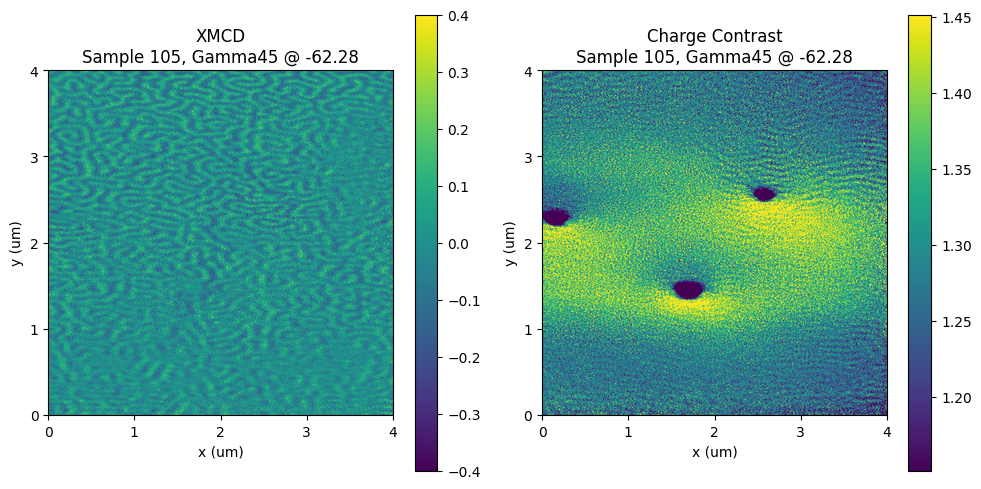

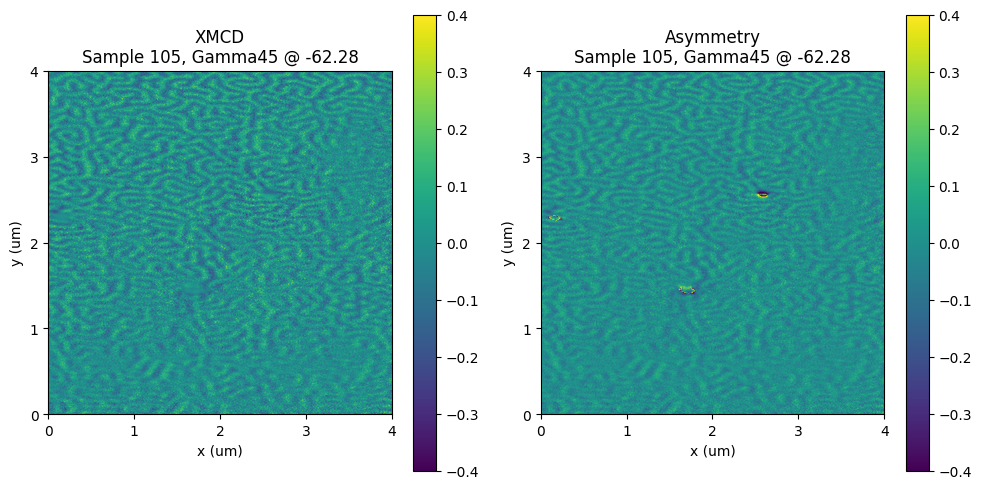

1


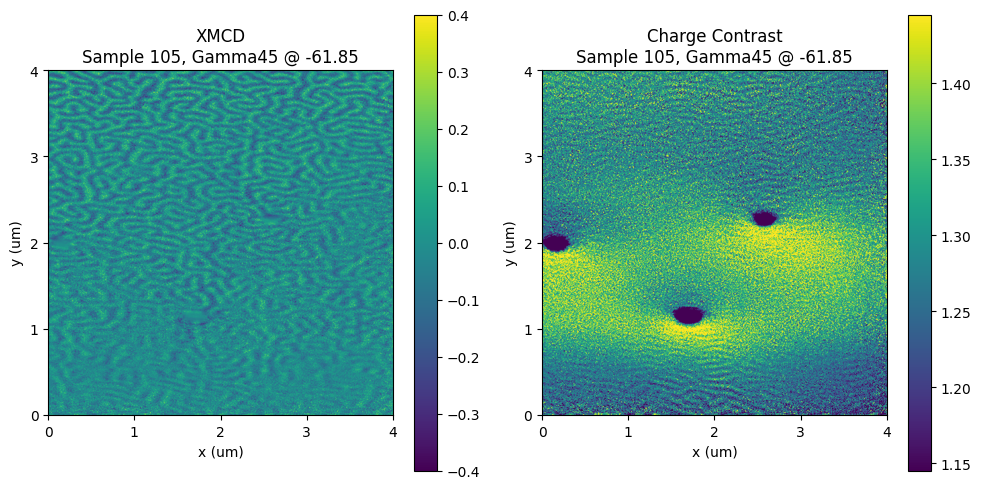

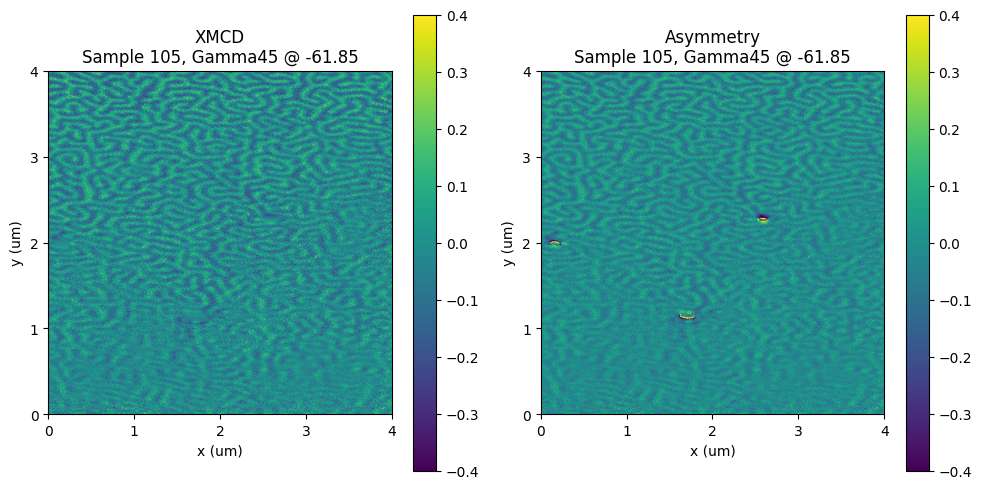

2


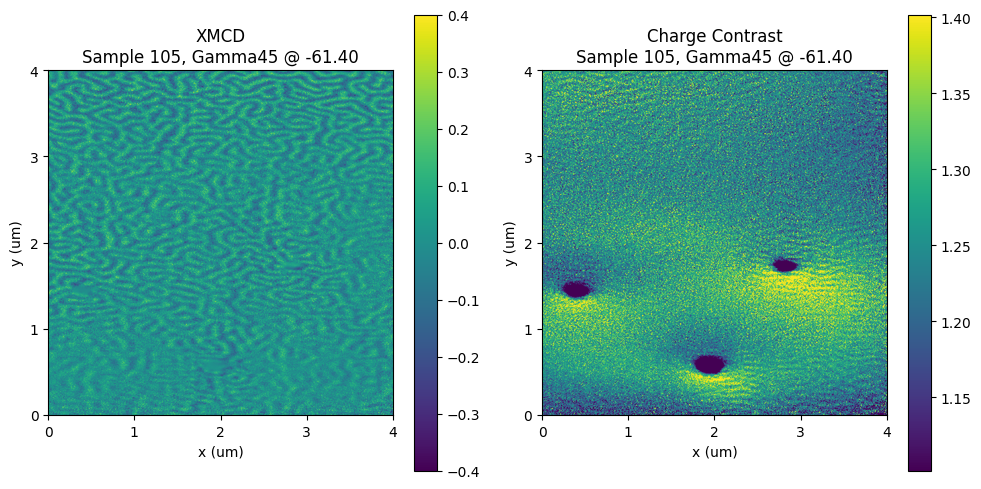

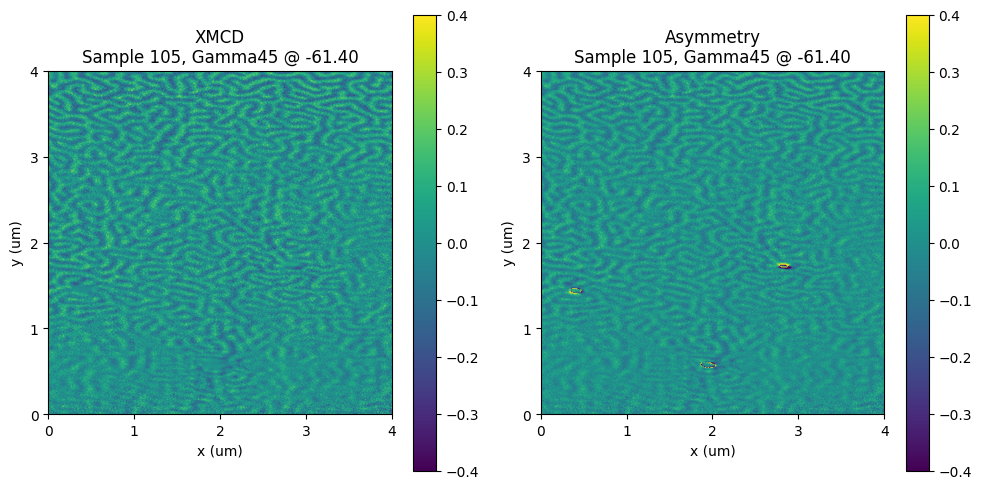

3


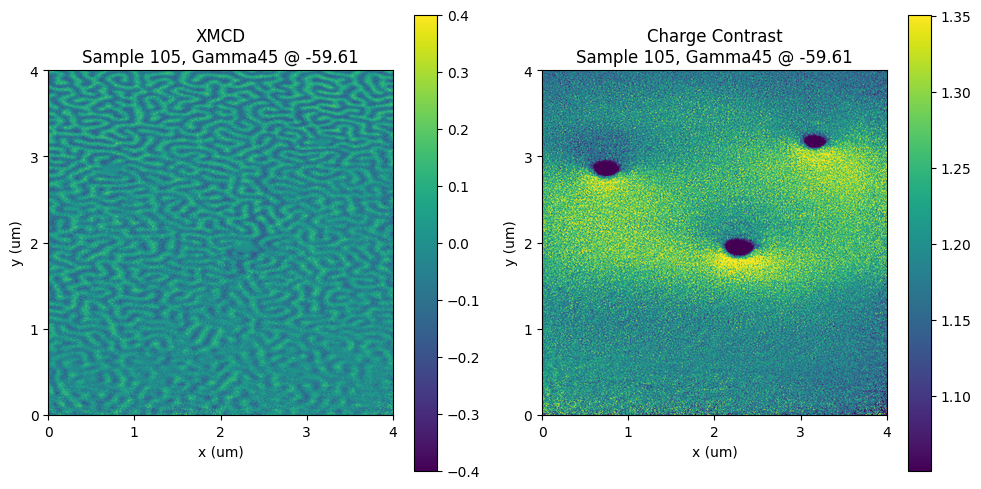

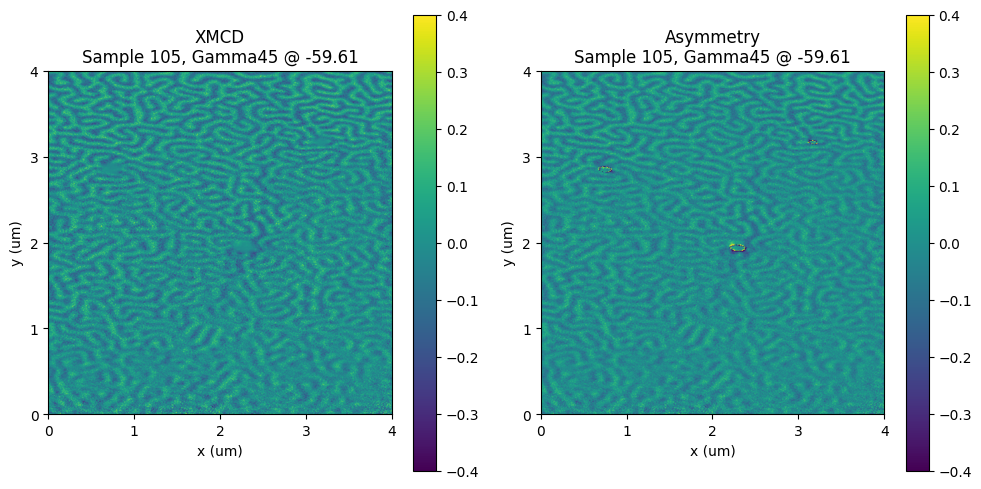

4


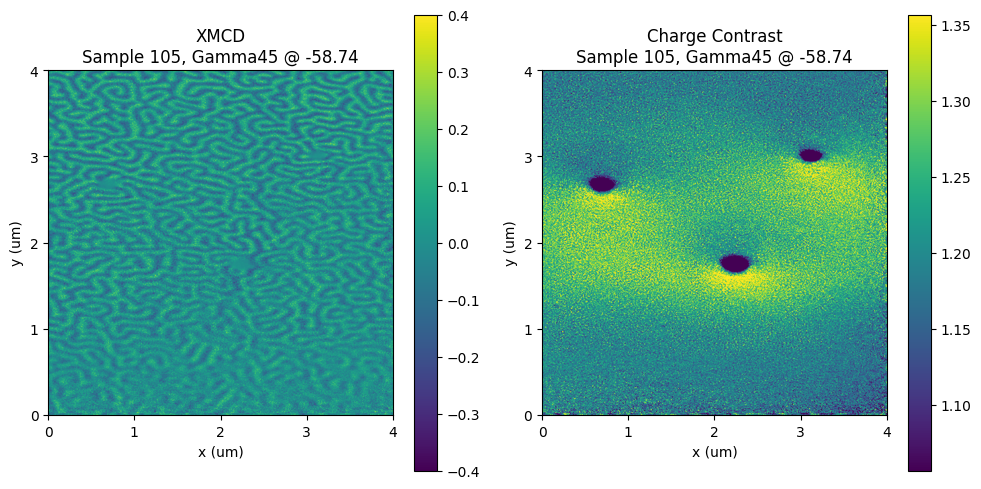

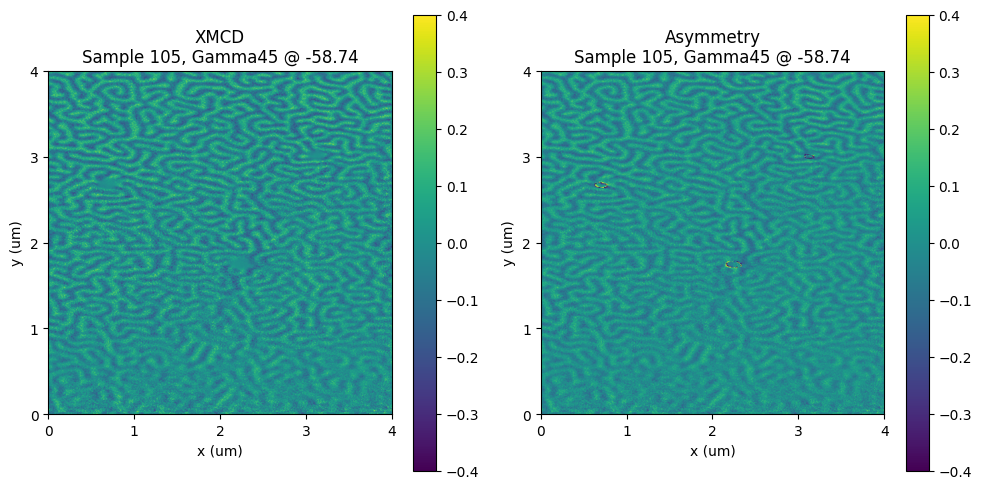

5


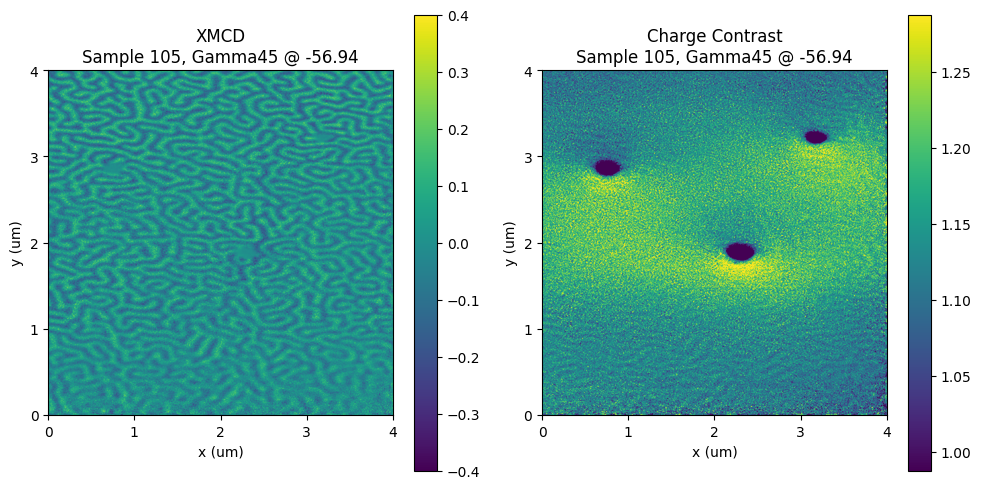

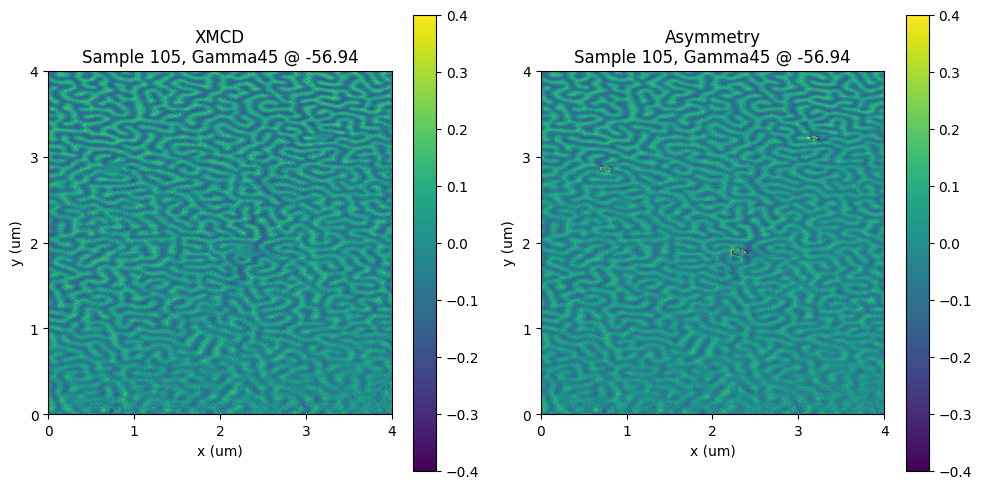

6


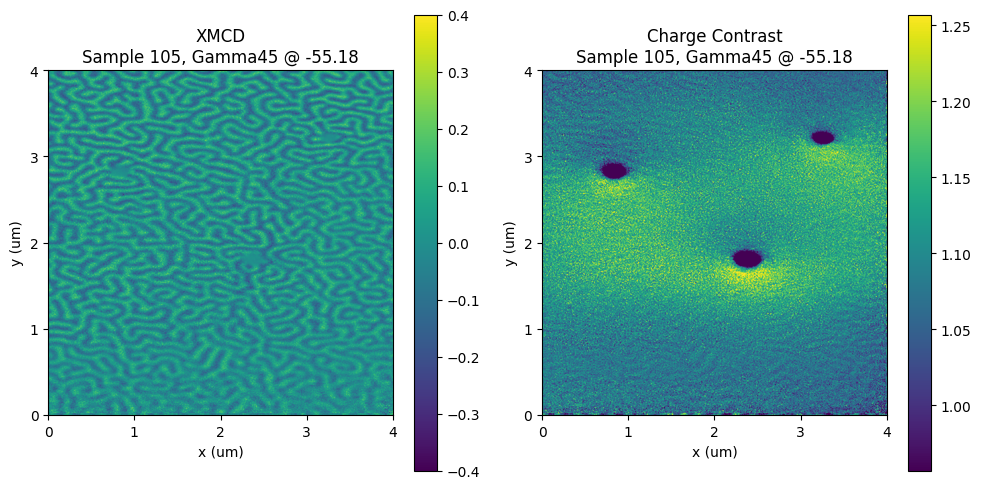

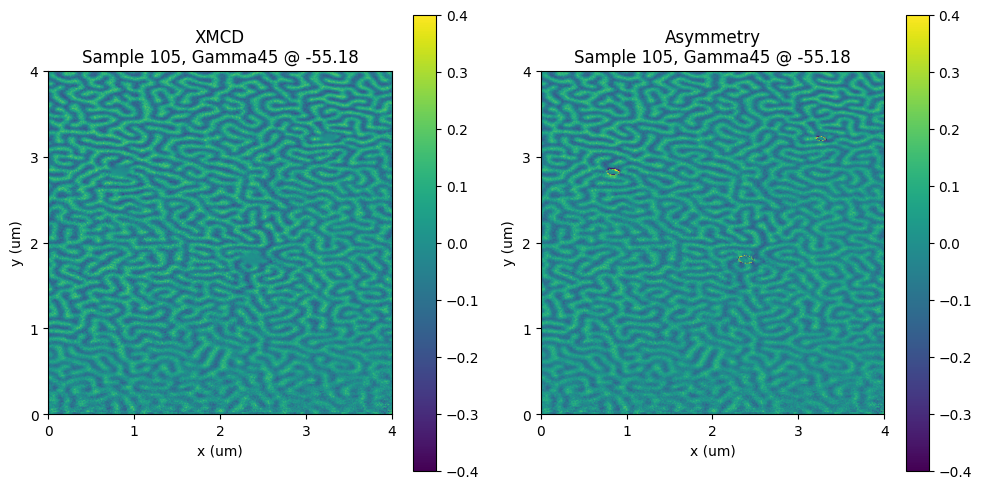

7


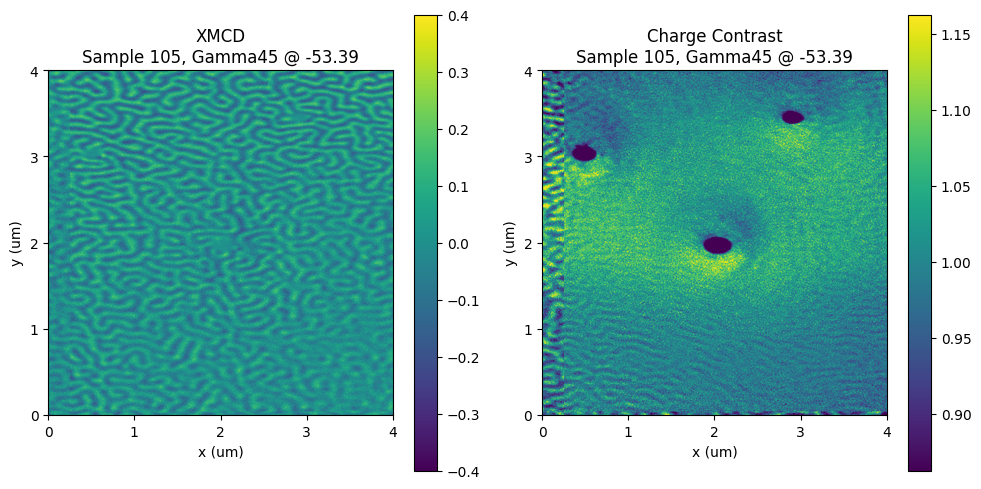

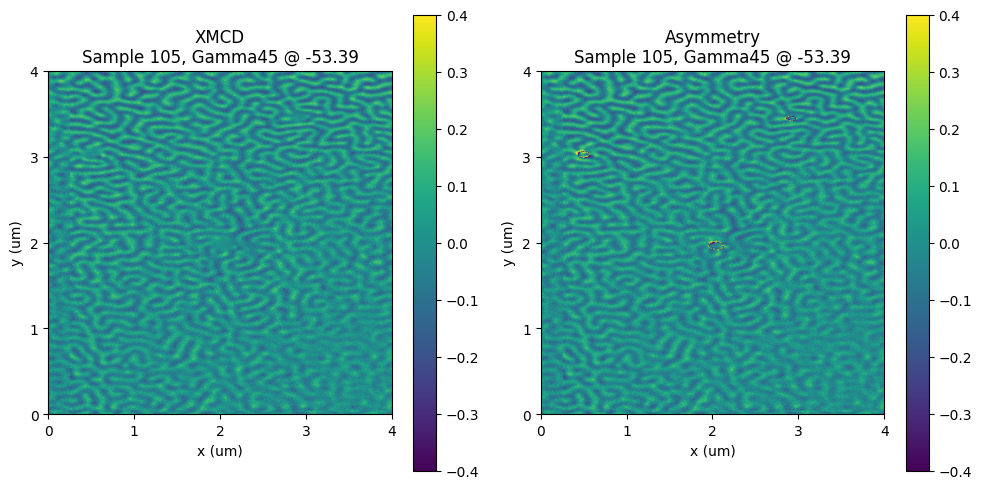

8


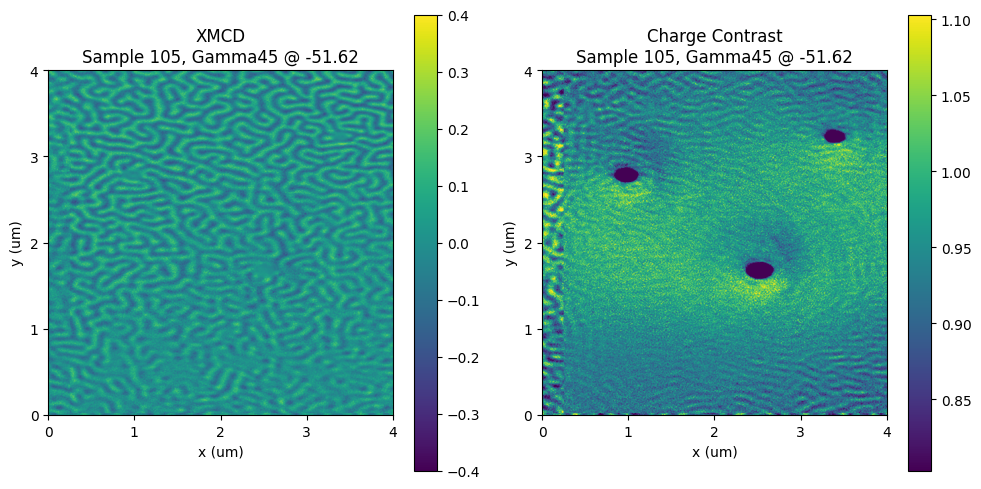

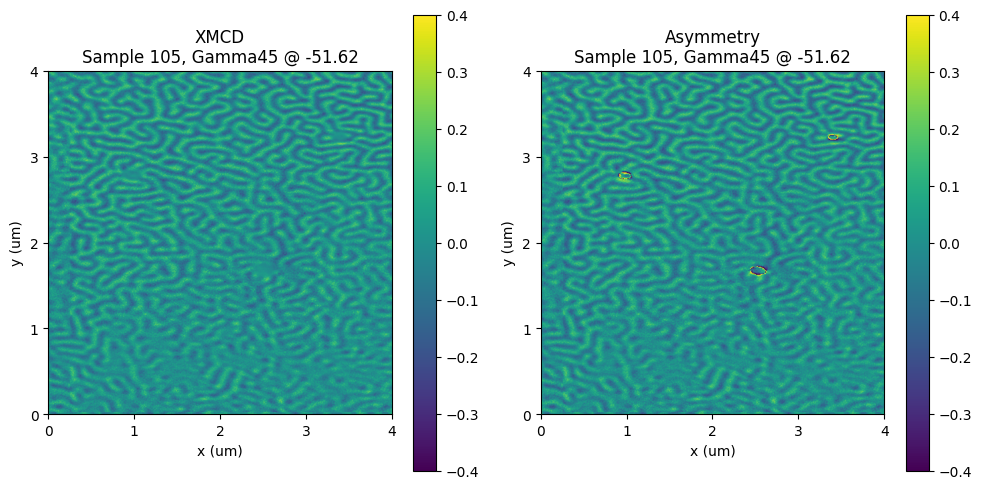

9


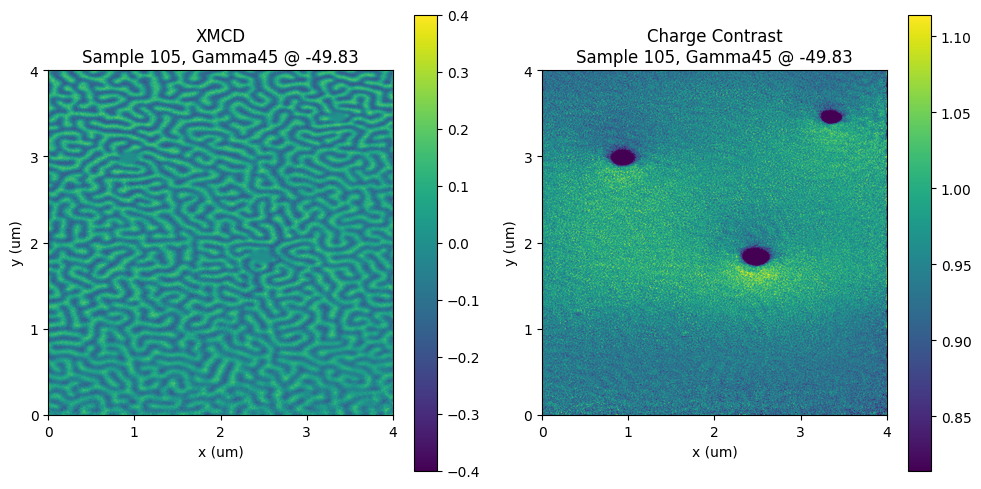

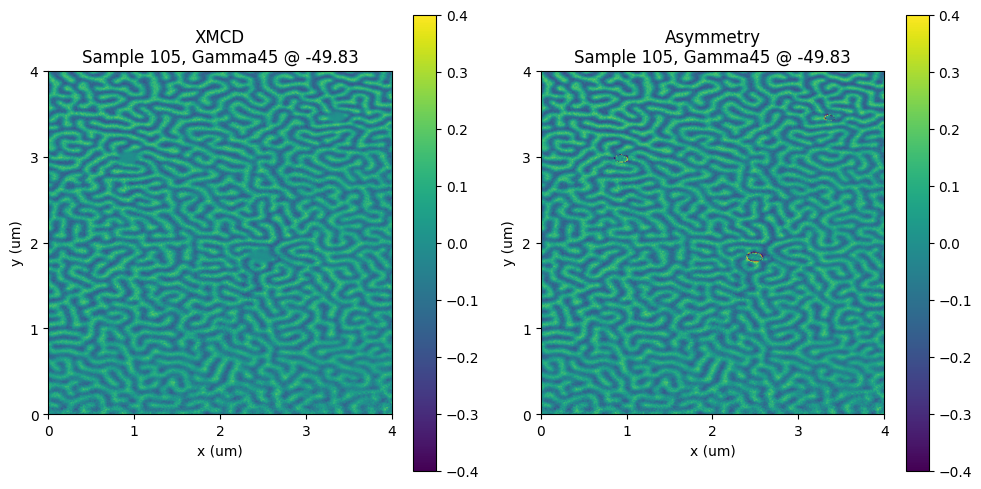

10


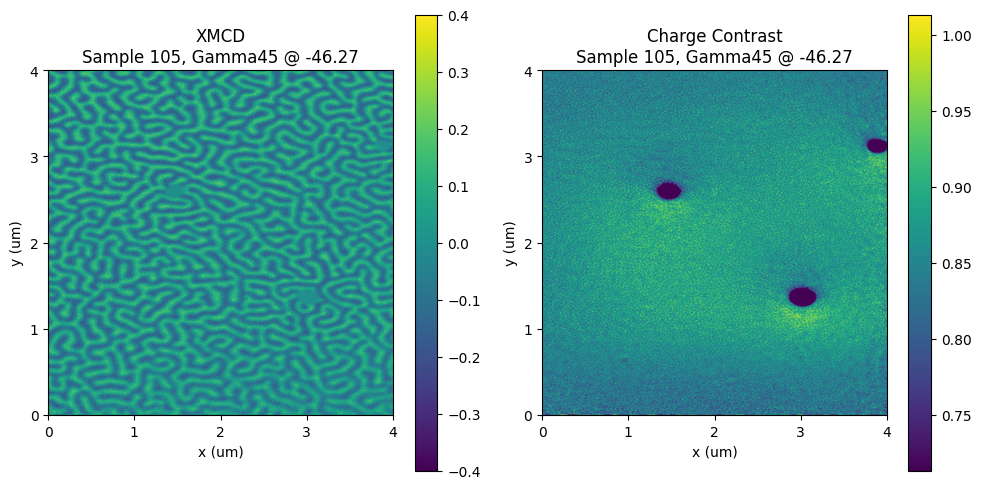

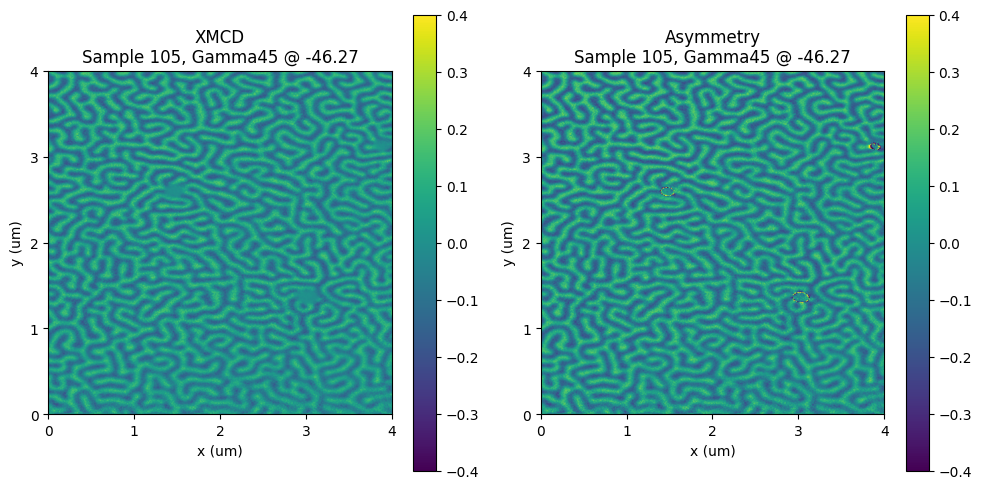

11


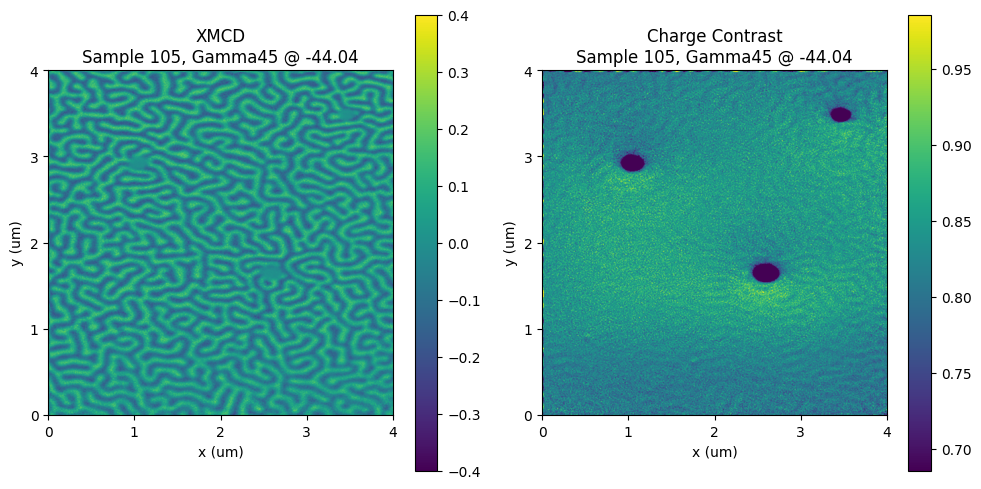

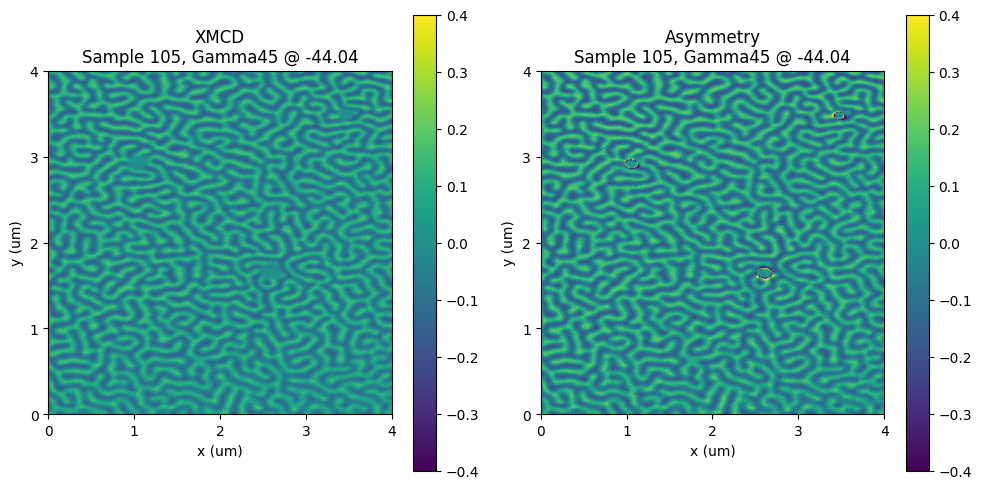

12


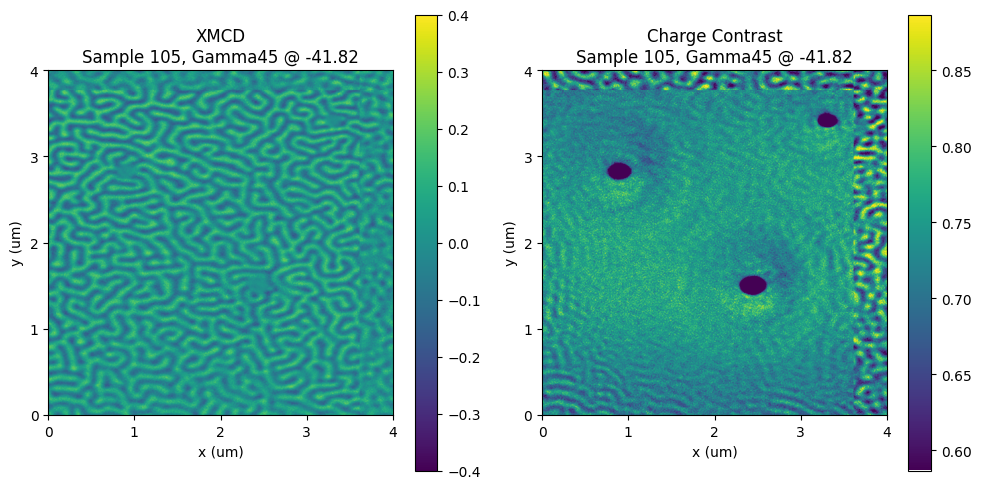

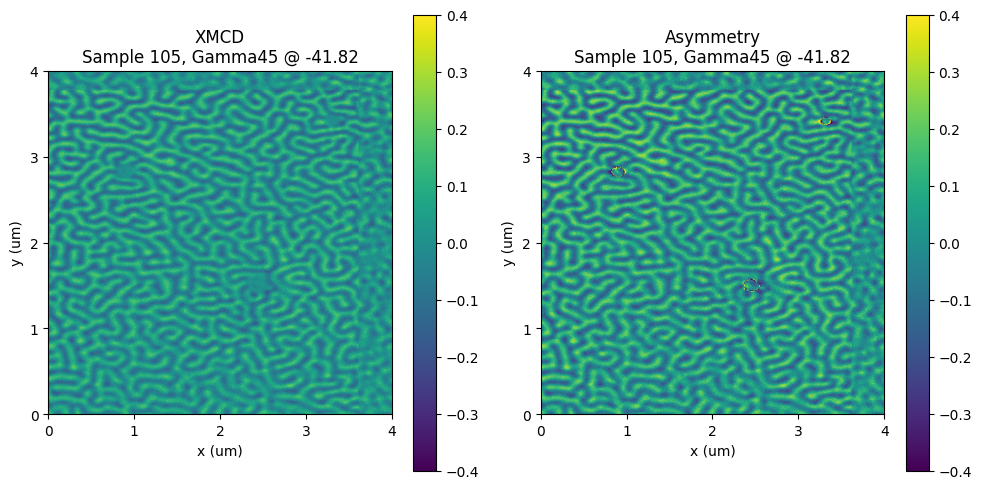

13


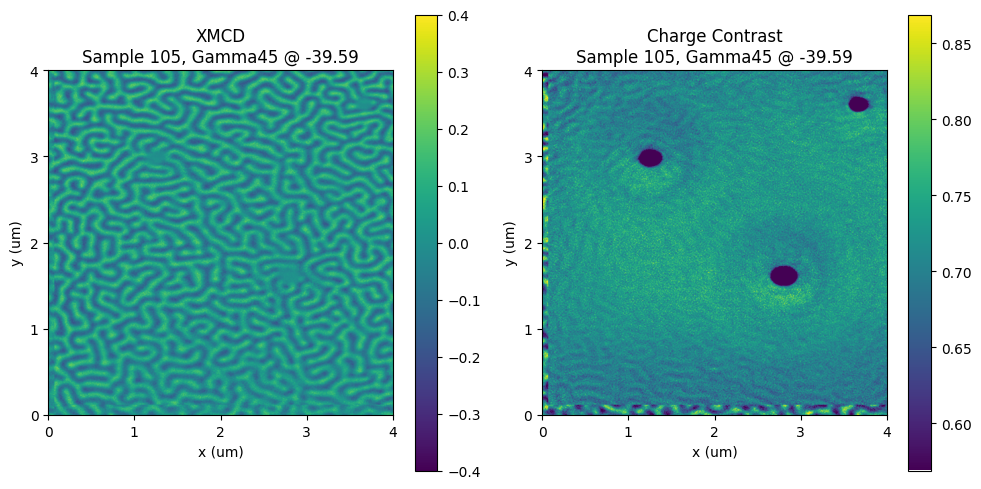

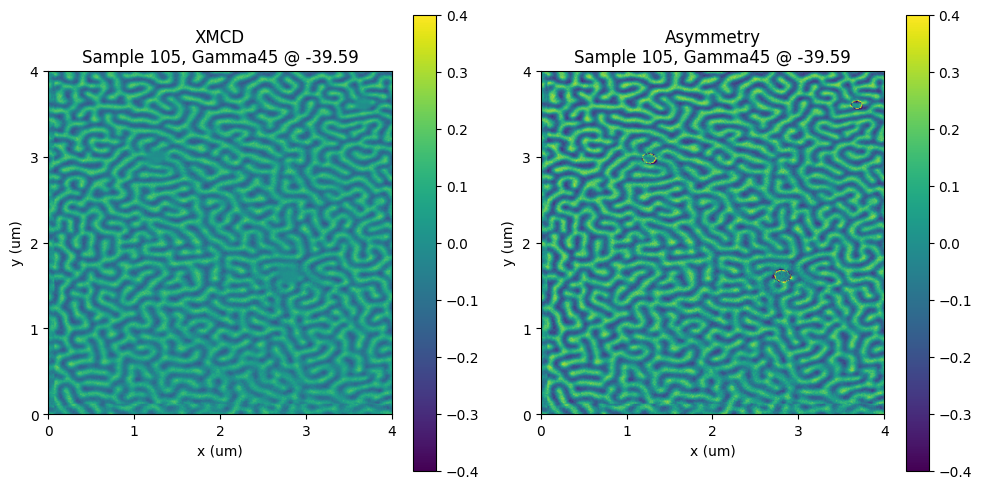

14


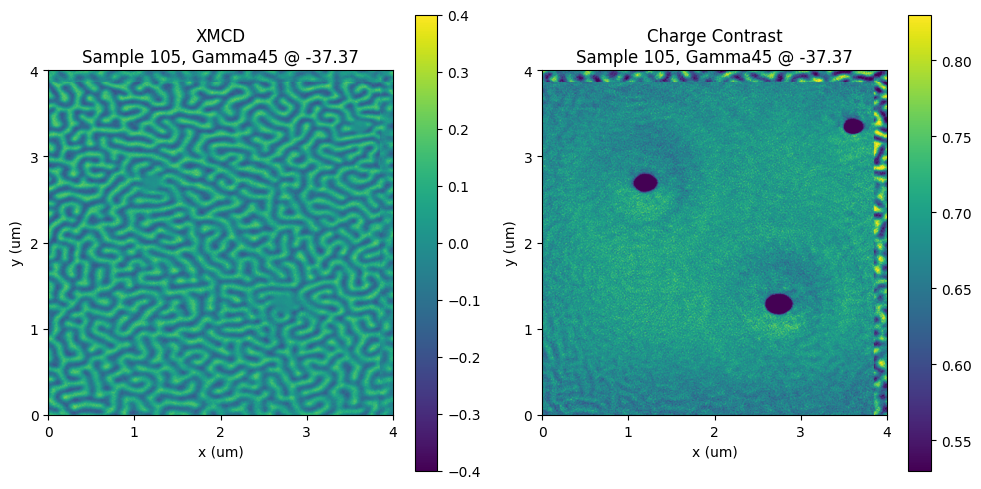

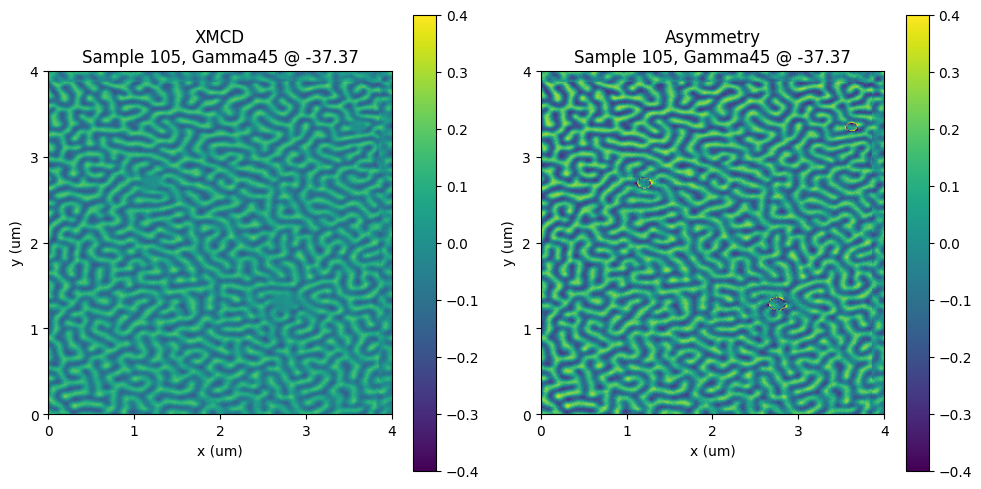

15


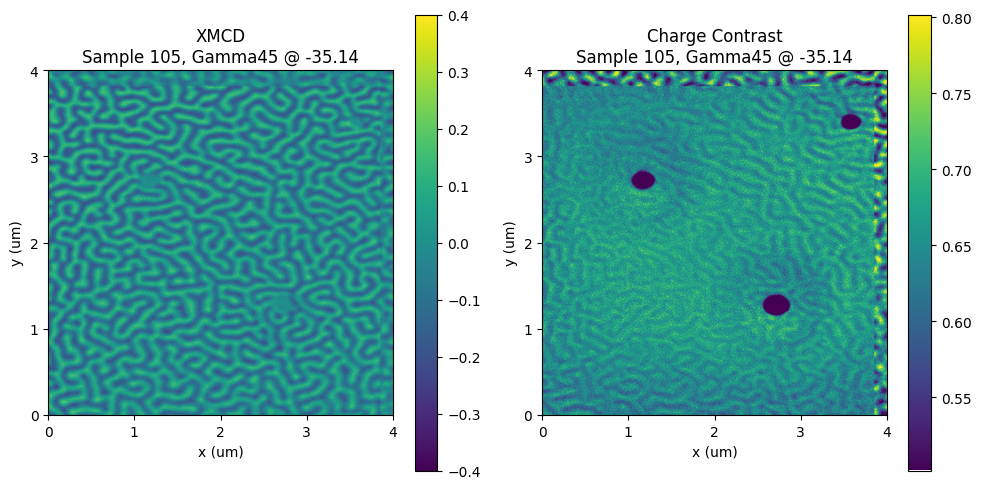

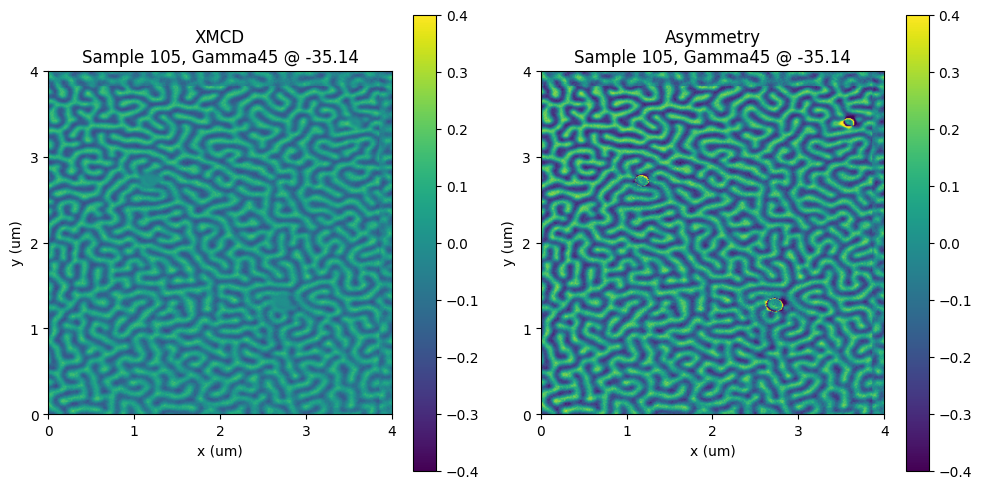

16


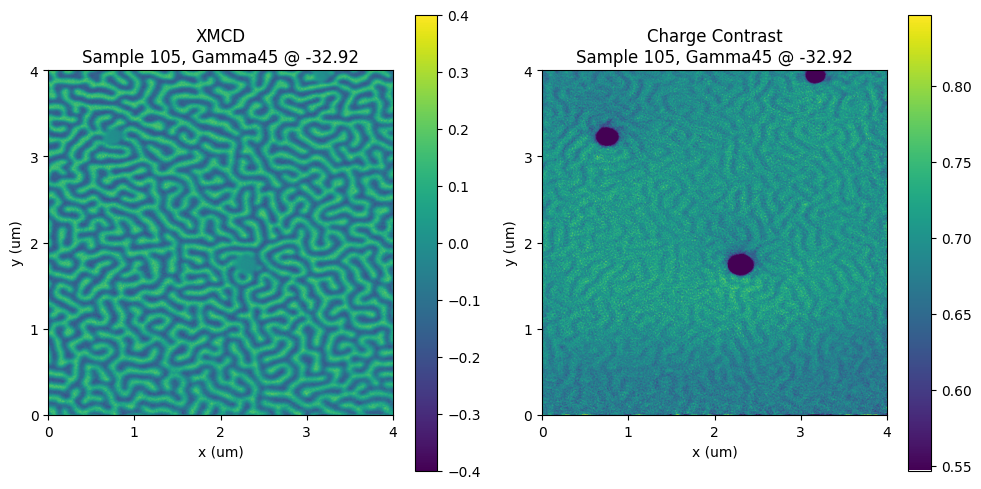

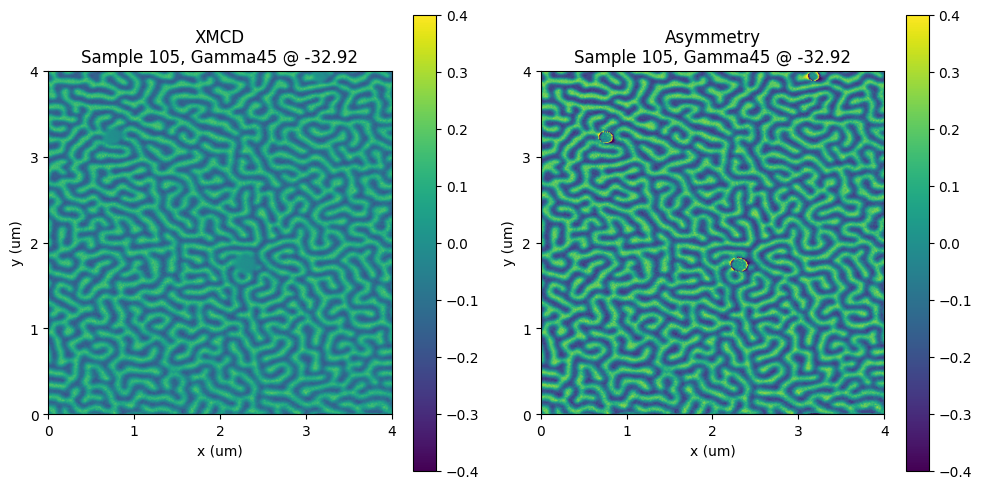

17


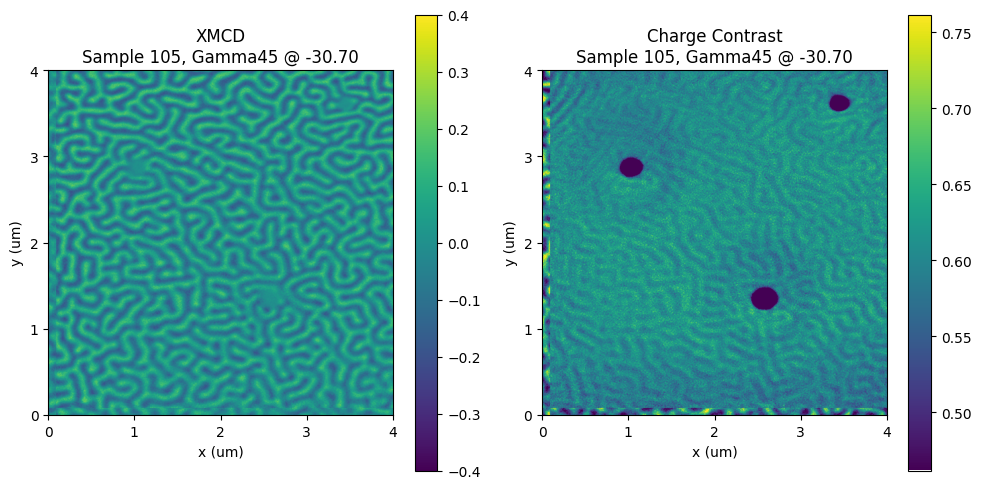

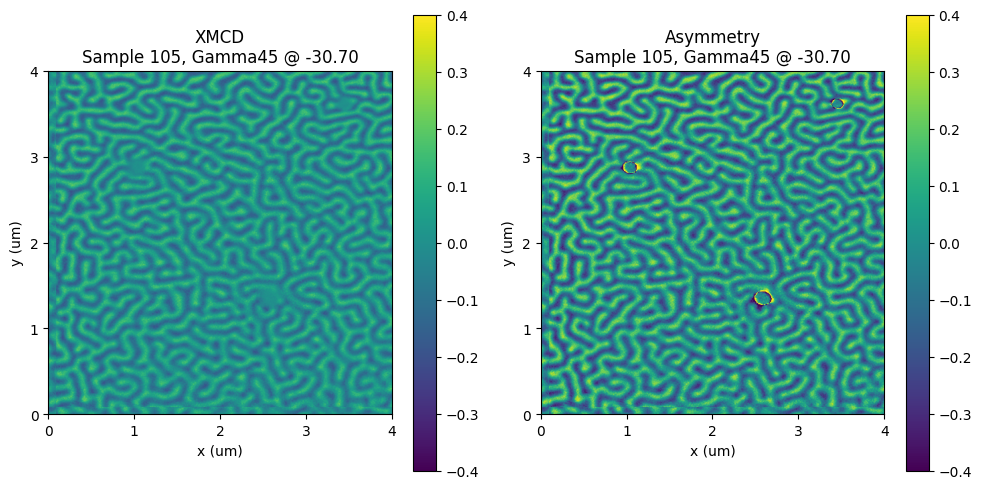

18


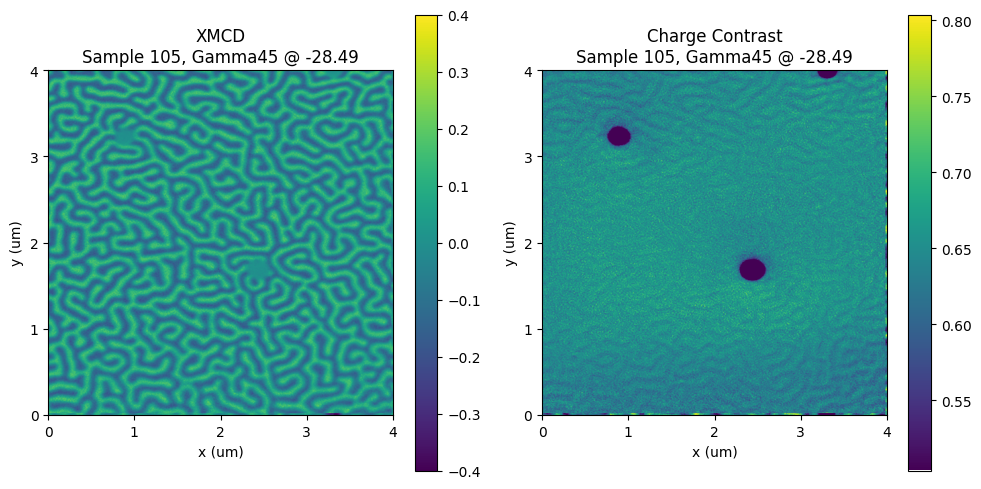

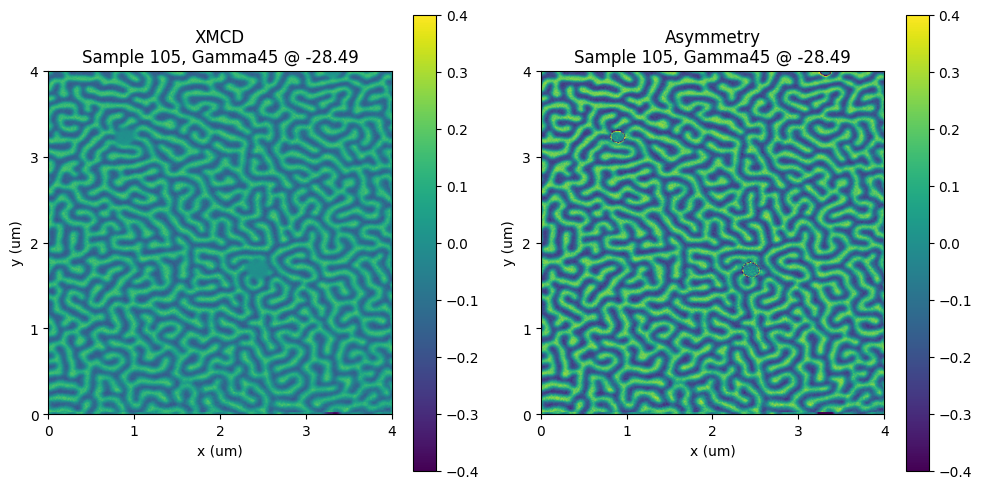

19


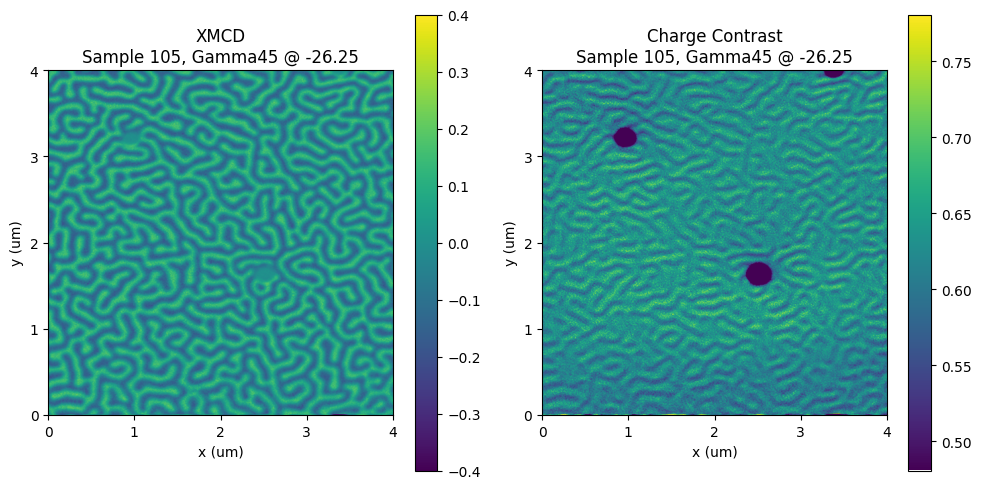

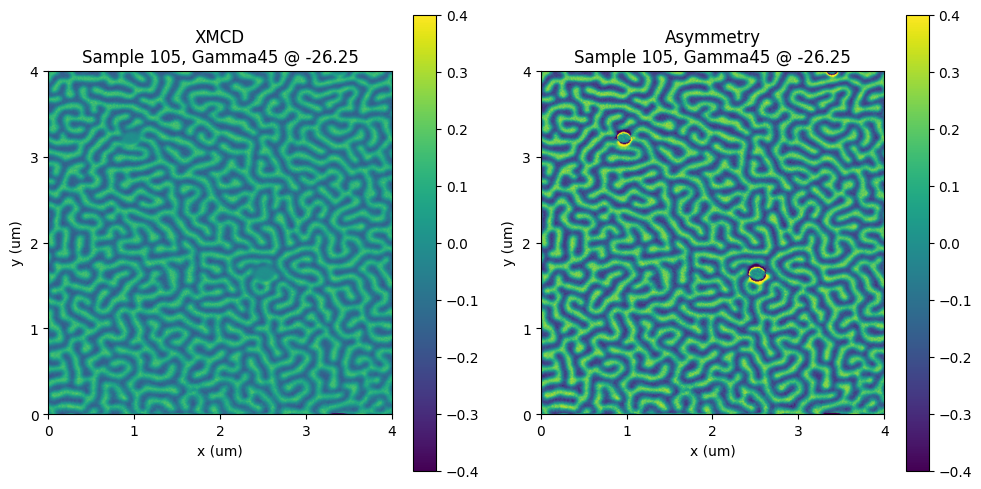

20


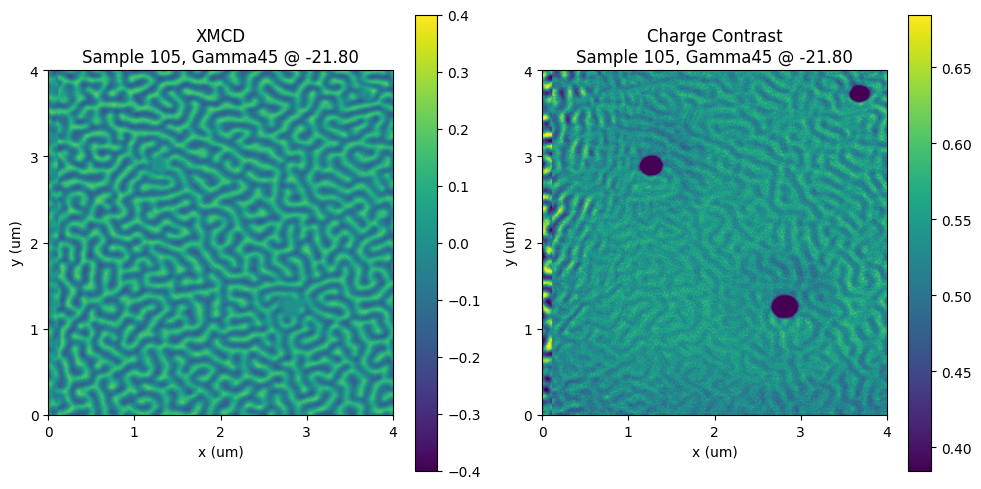

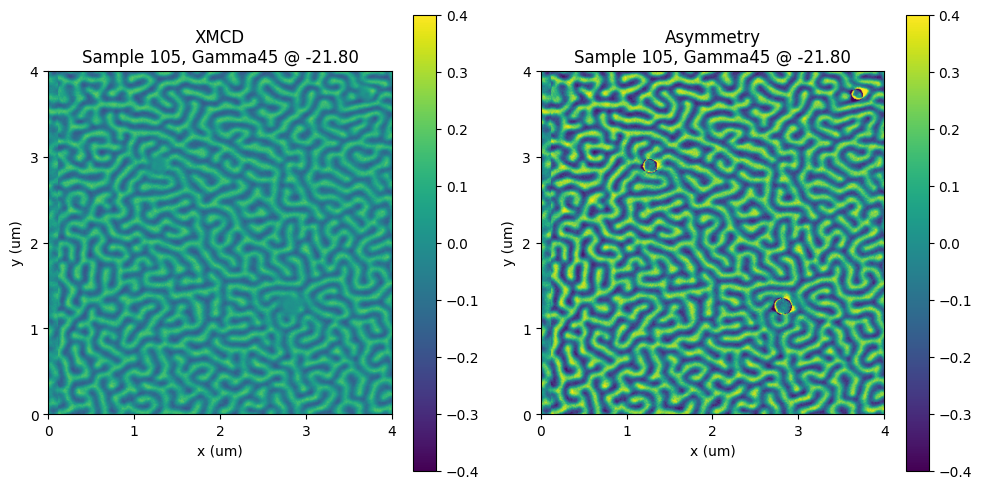

21


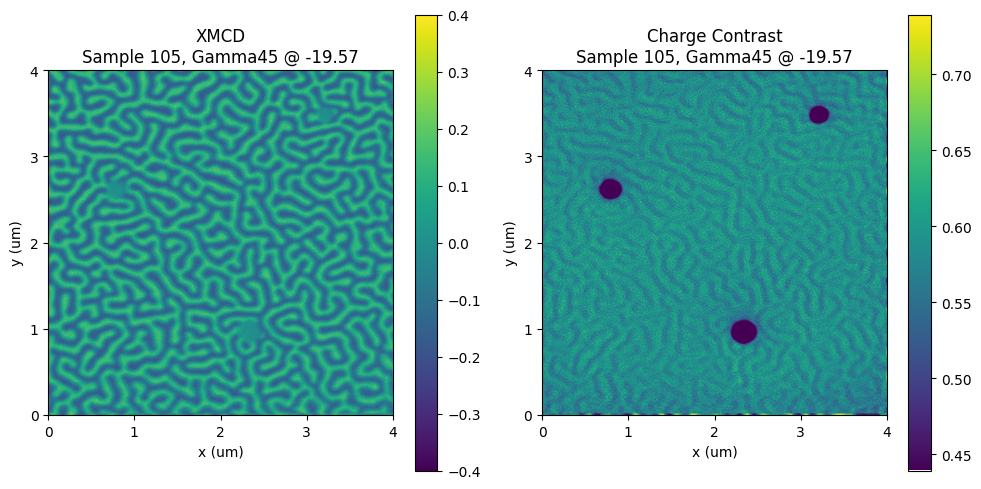

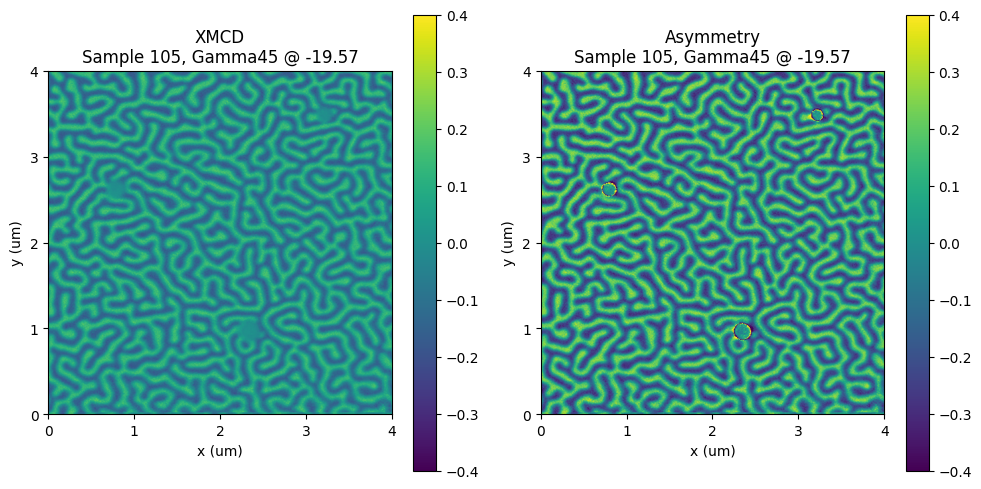

22


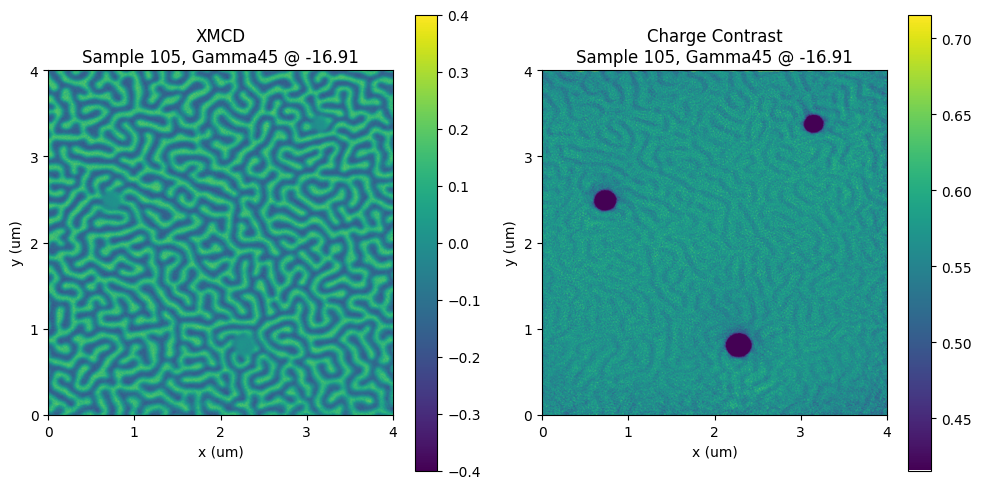

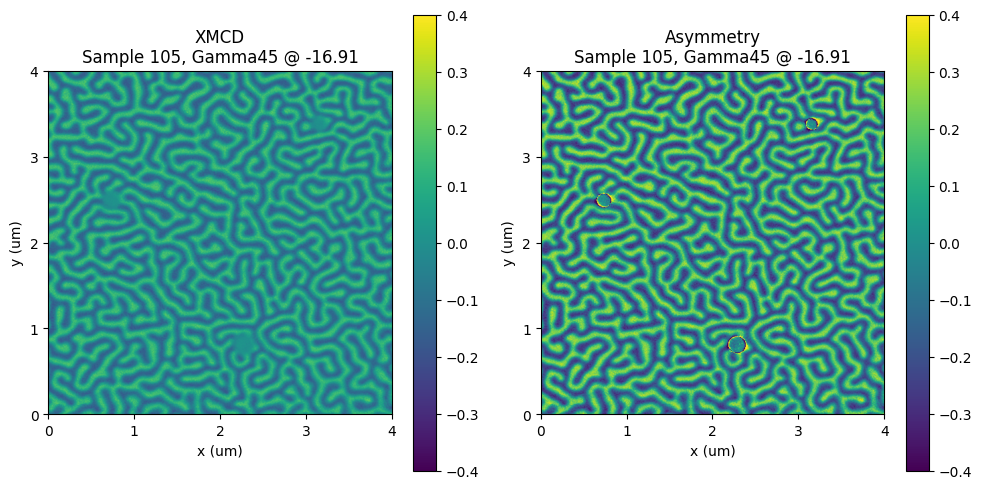

23


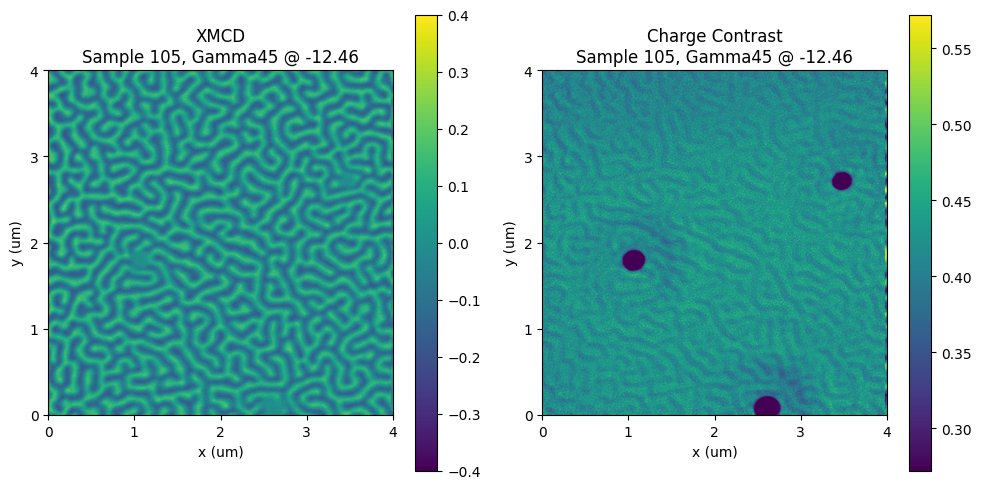

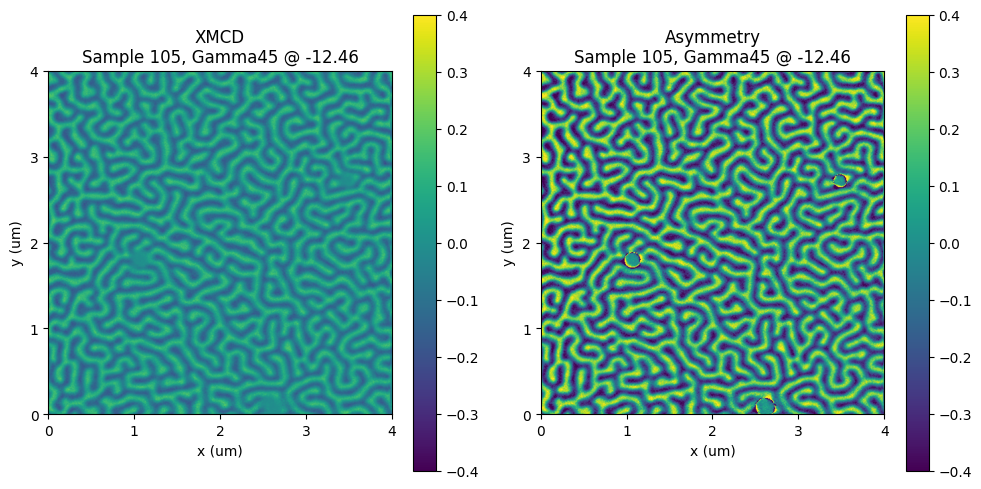

24


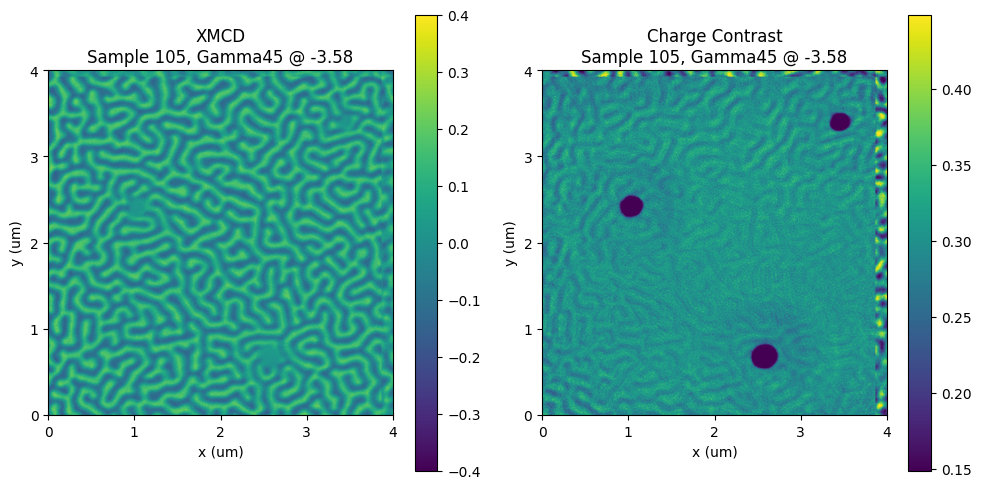

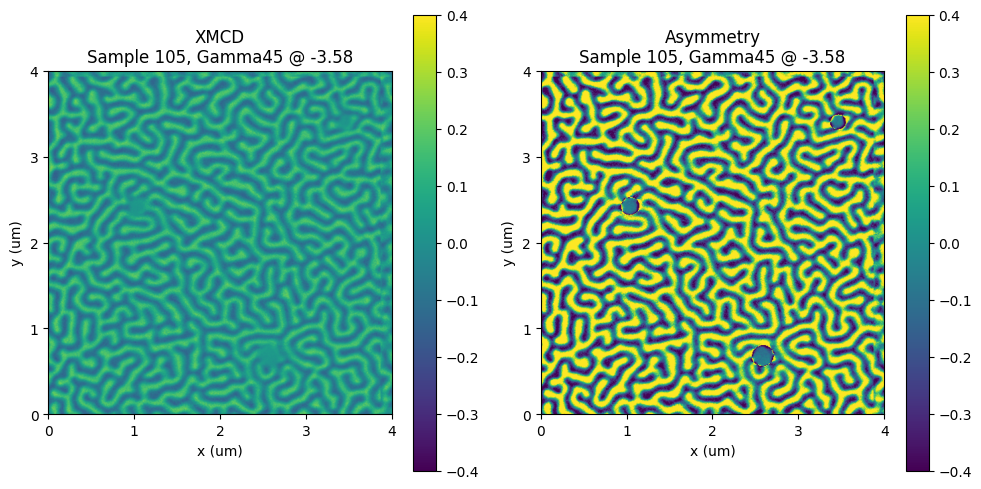

25


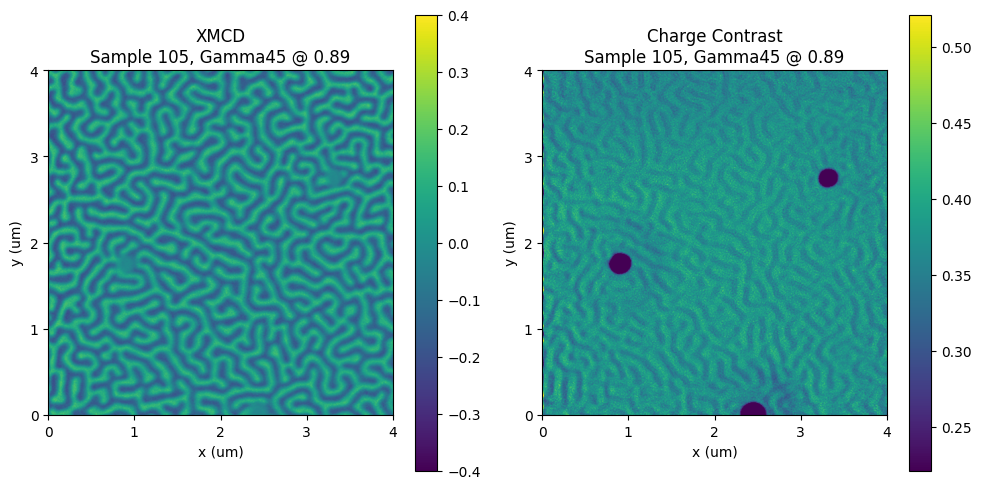

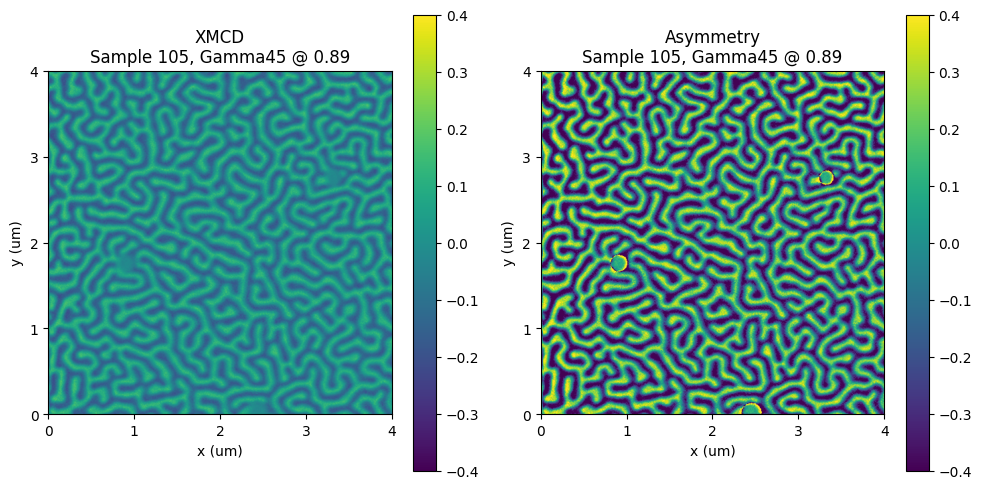

26


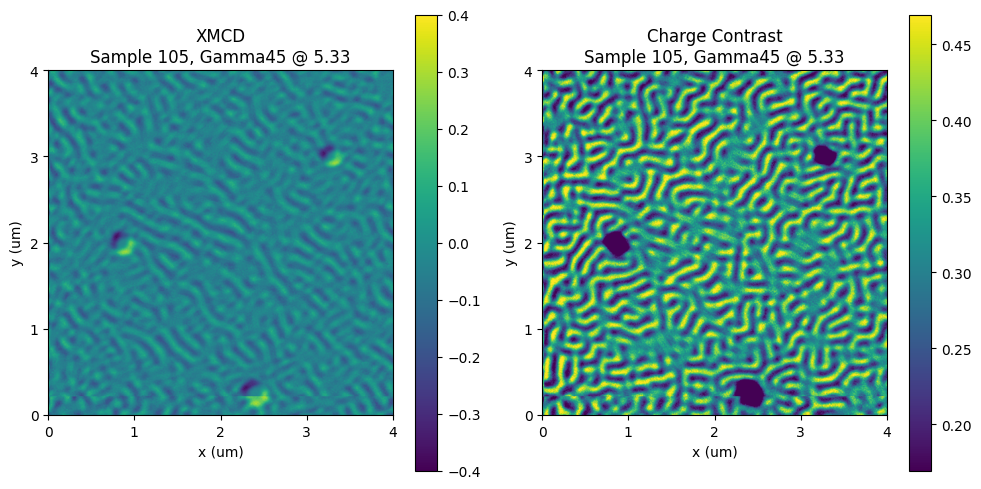

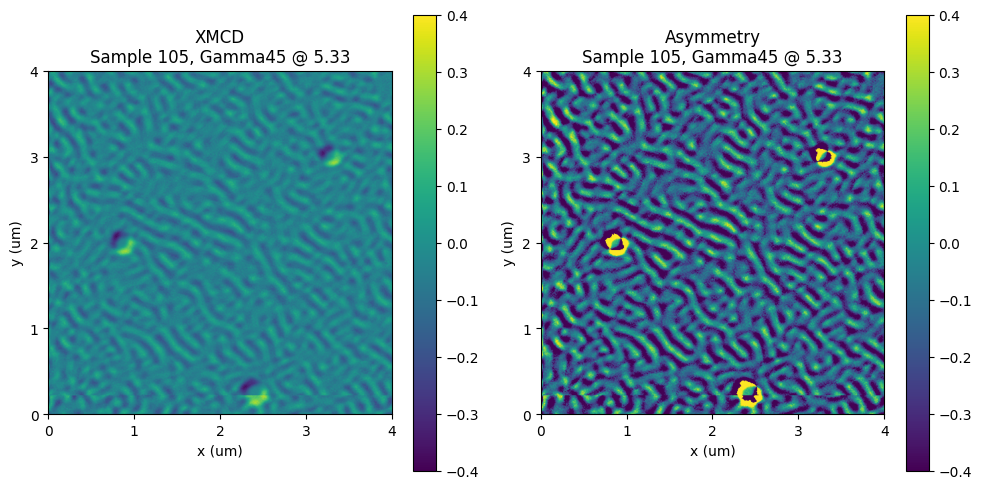

27


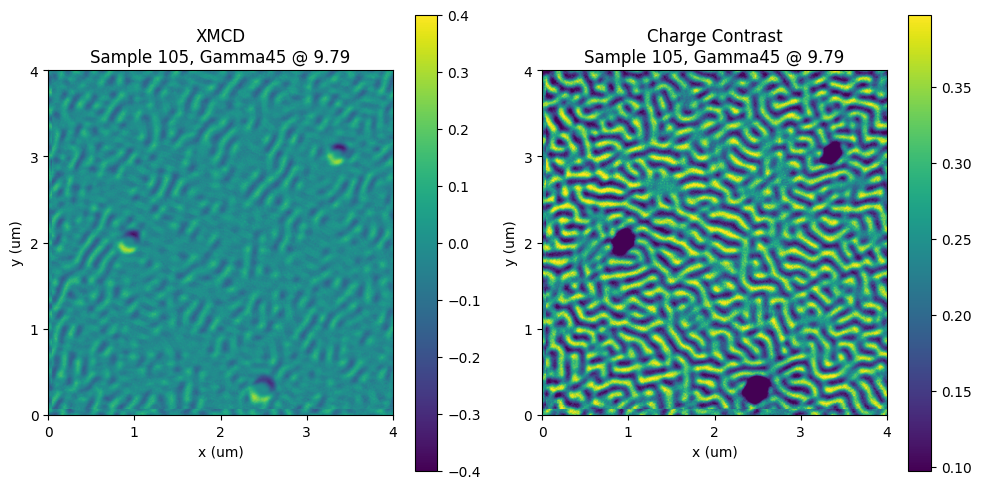

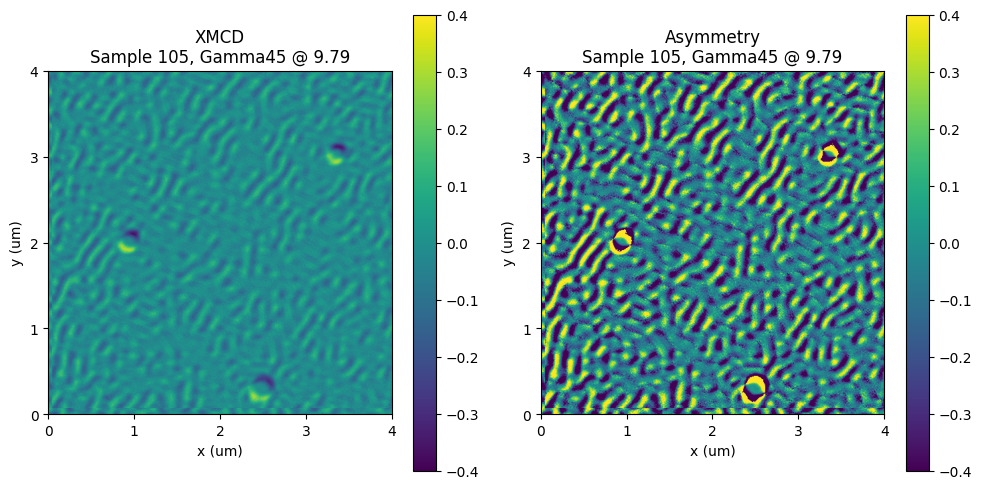

28


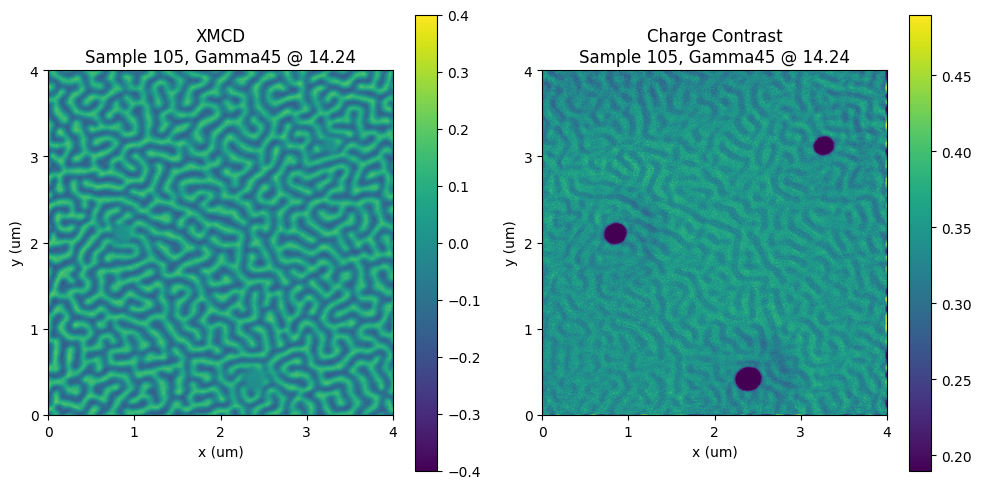

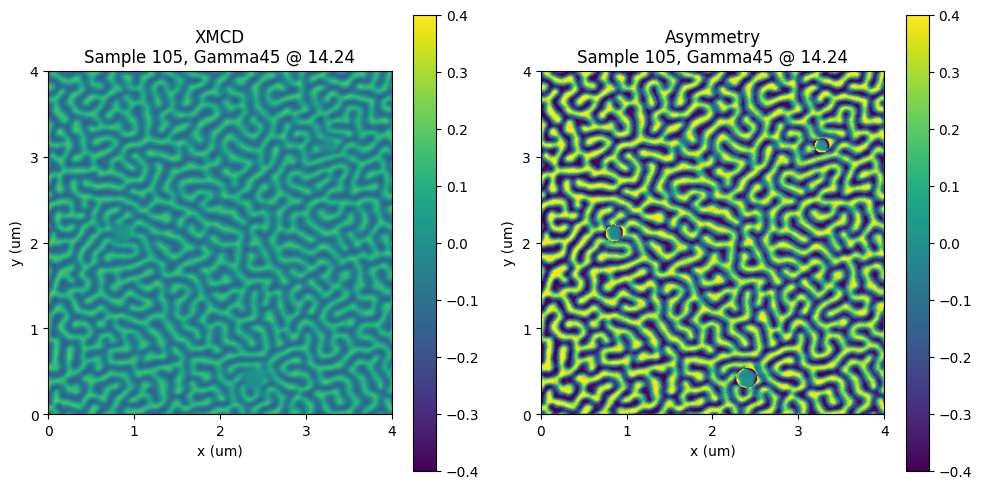

29


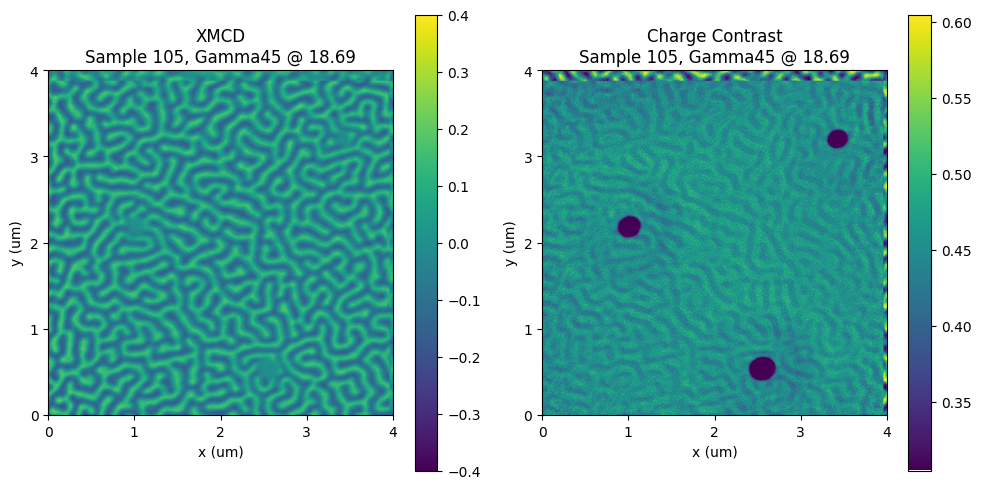

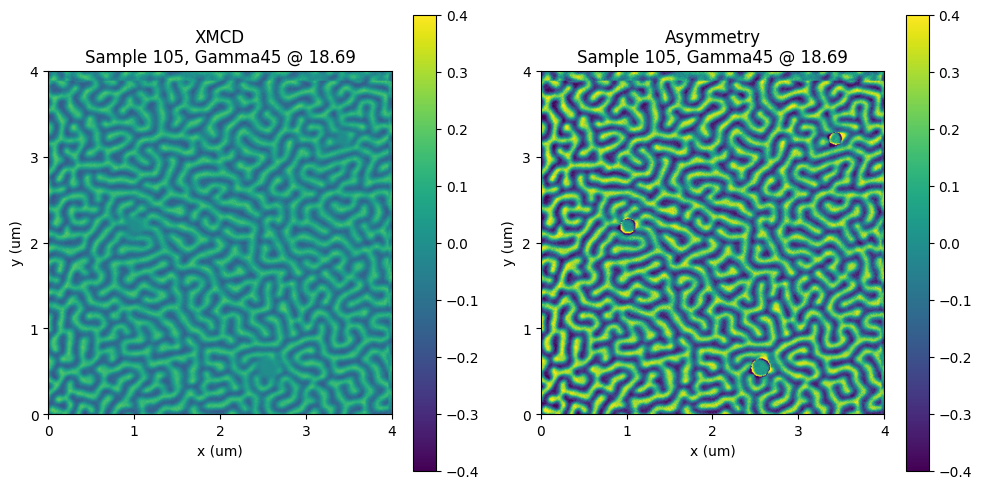

30


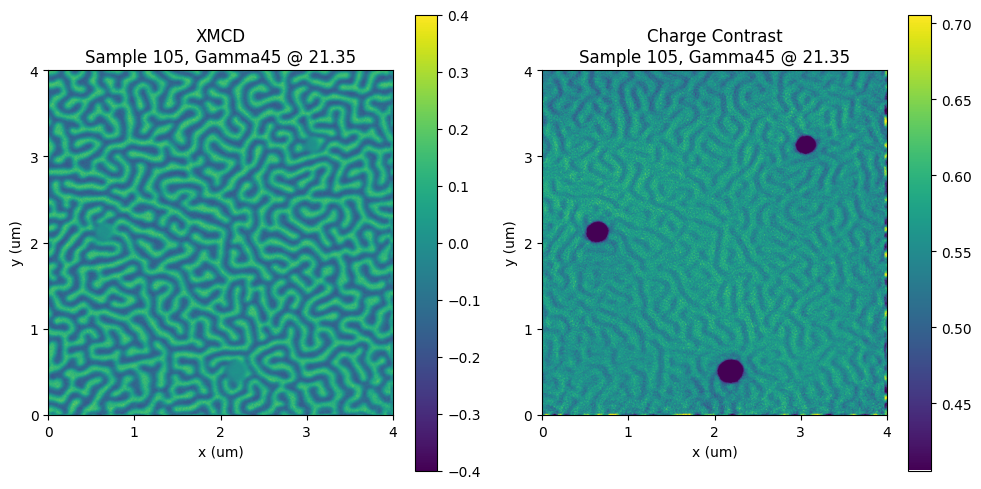

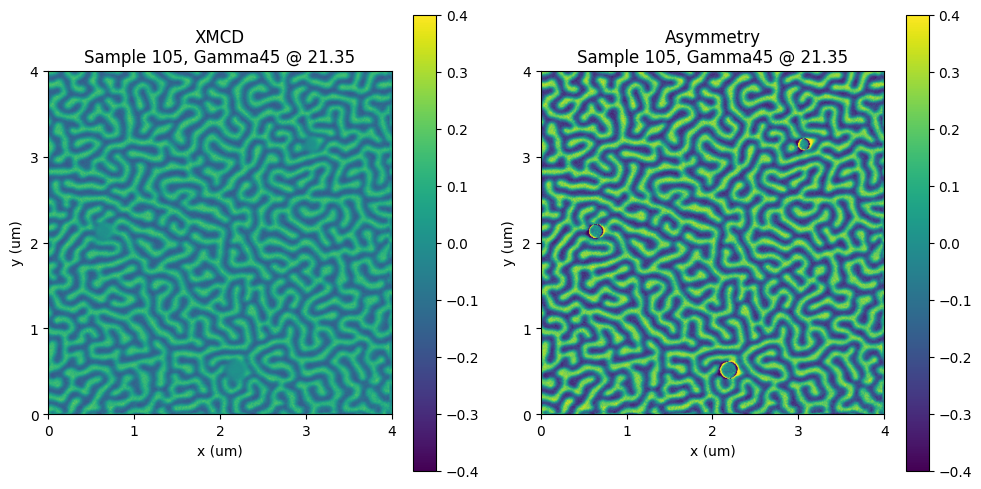

31


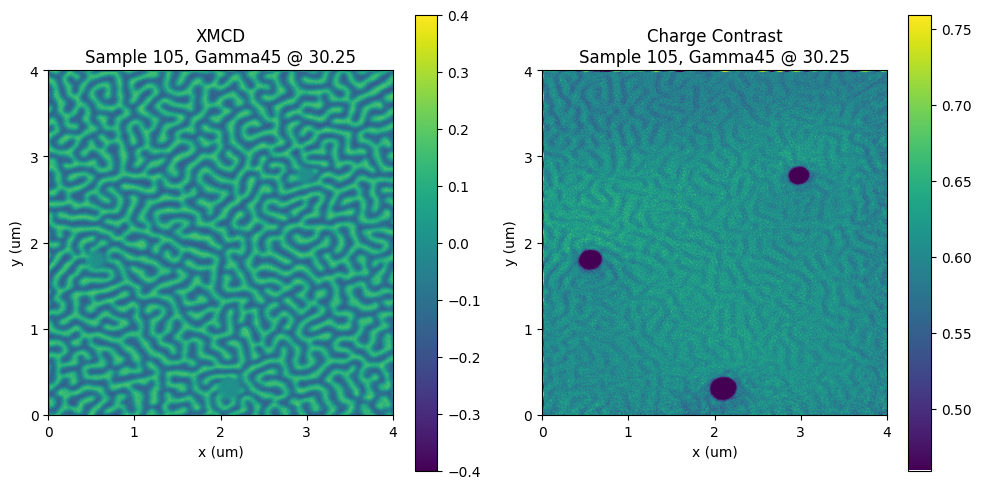

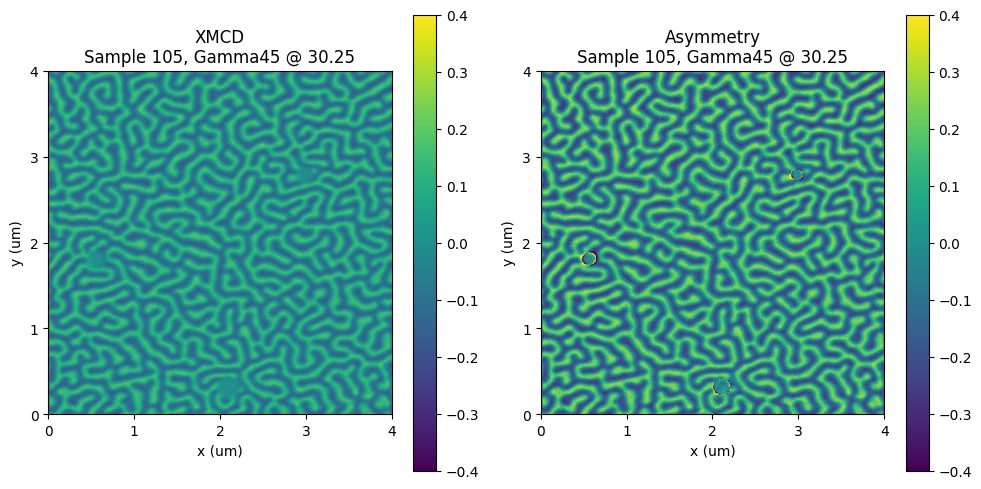

32


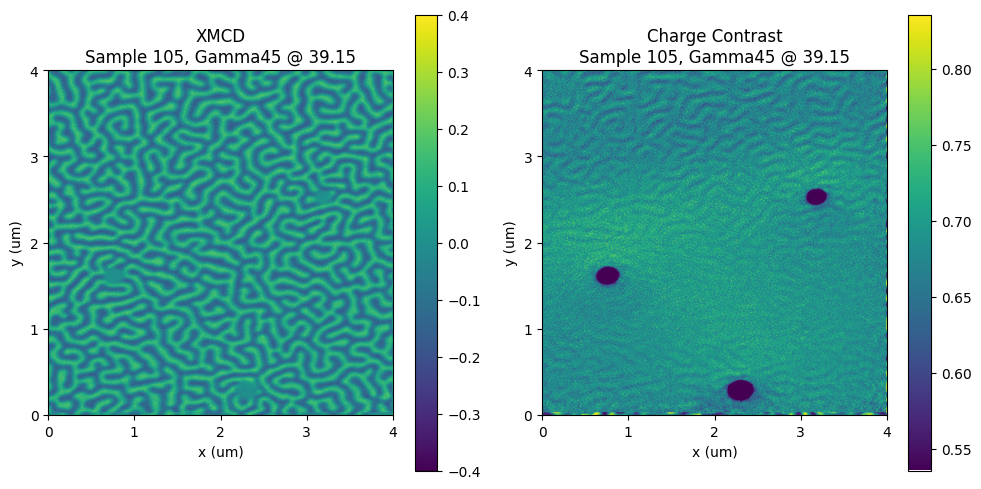

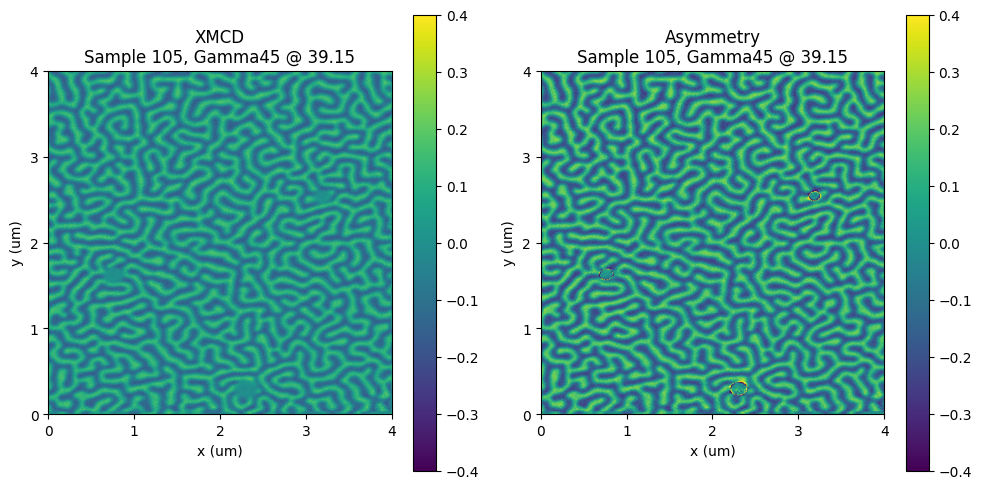

33


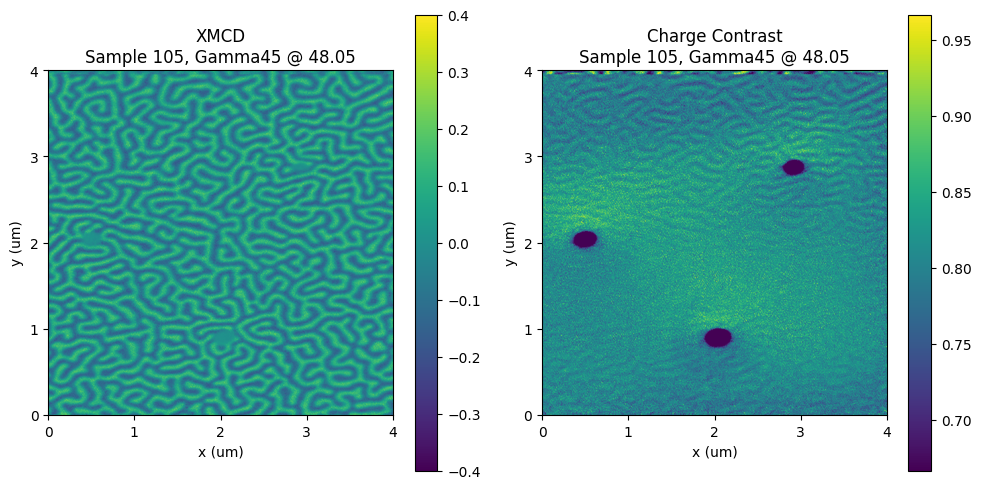

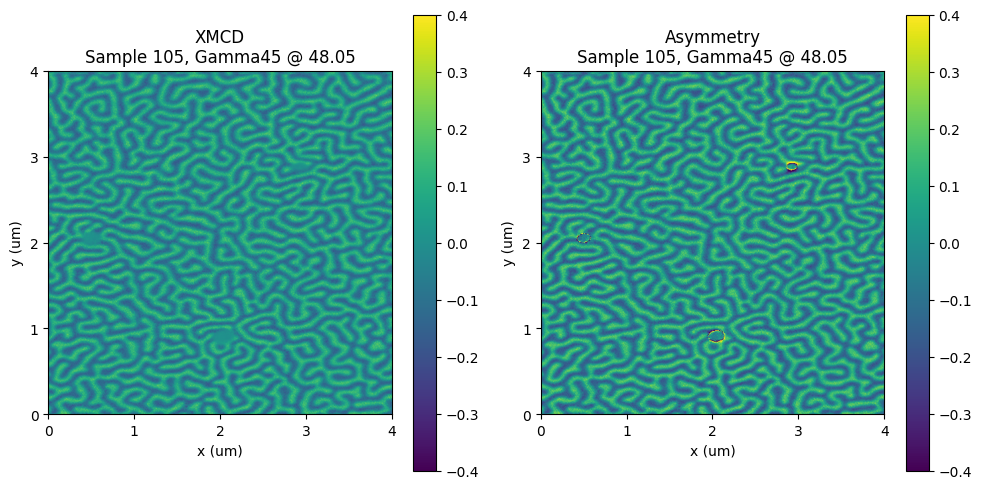

34


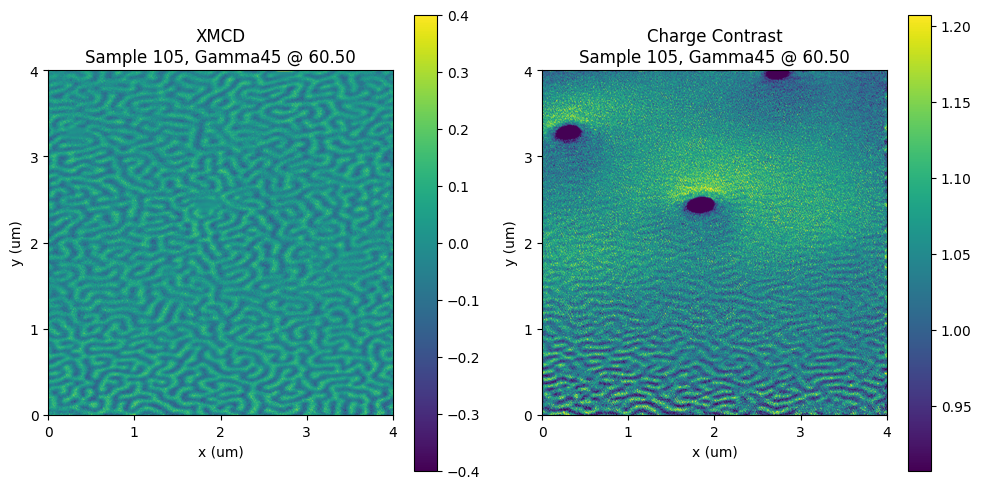

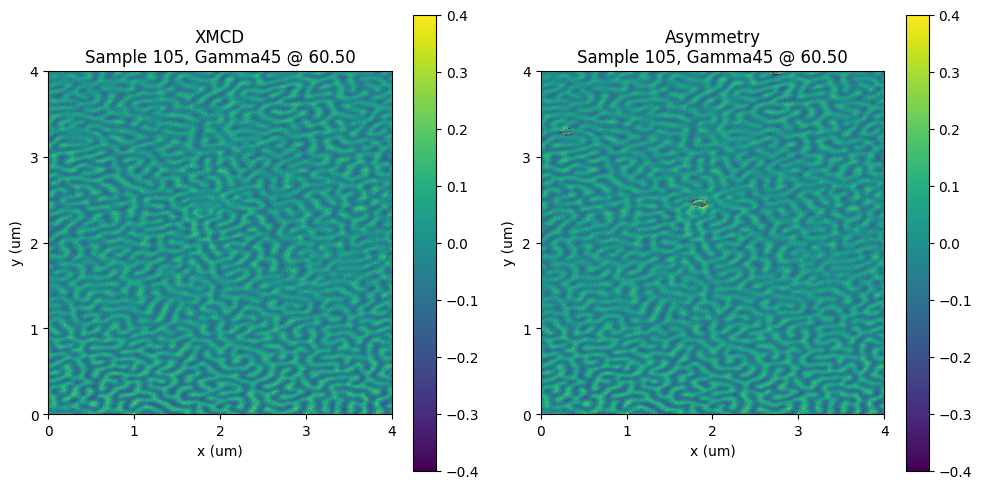

35


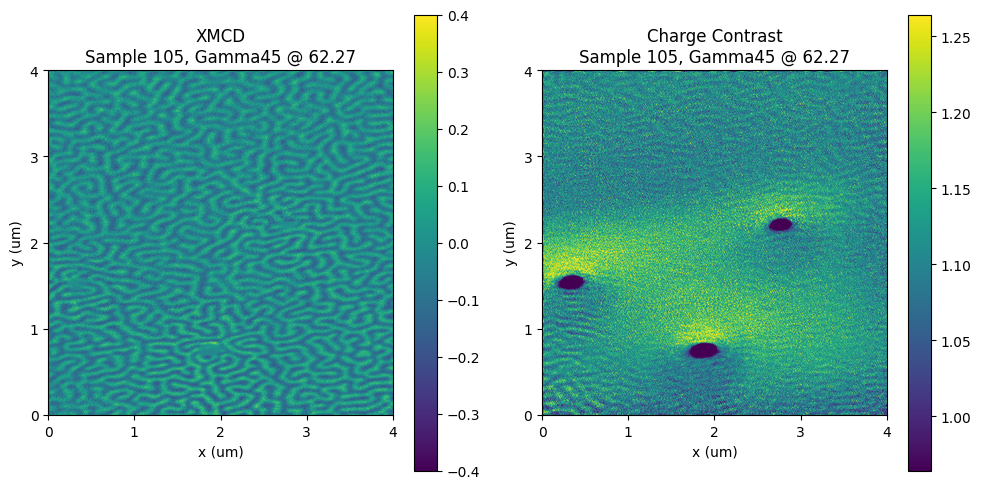

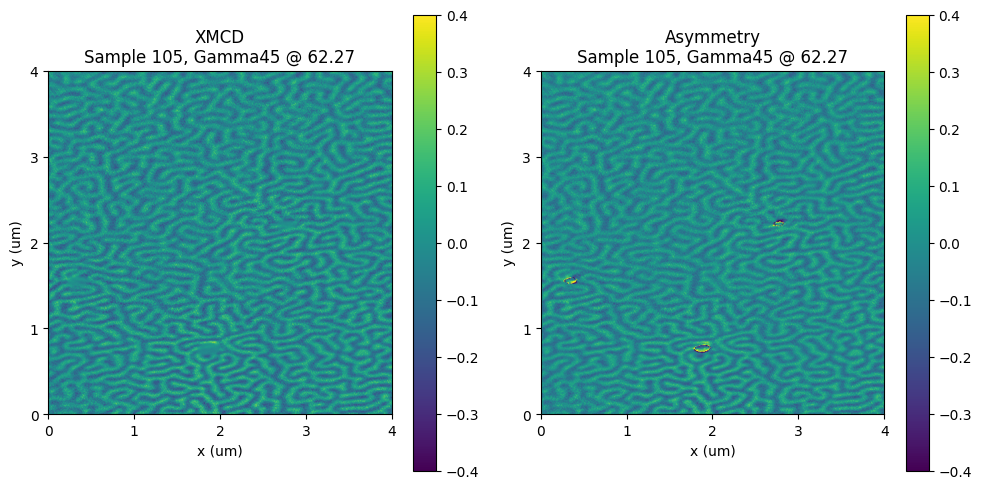

36


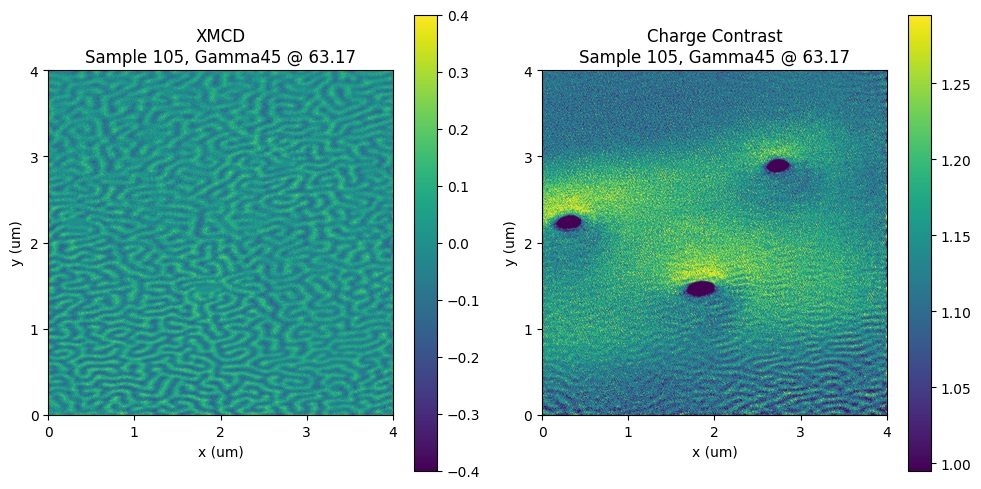

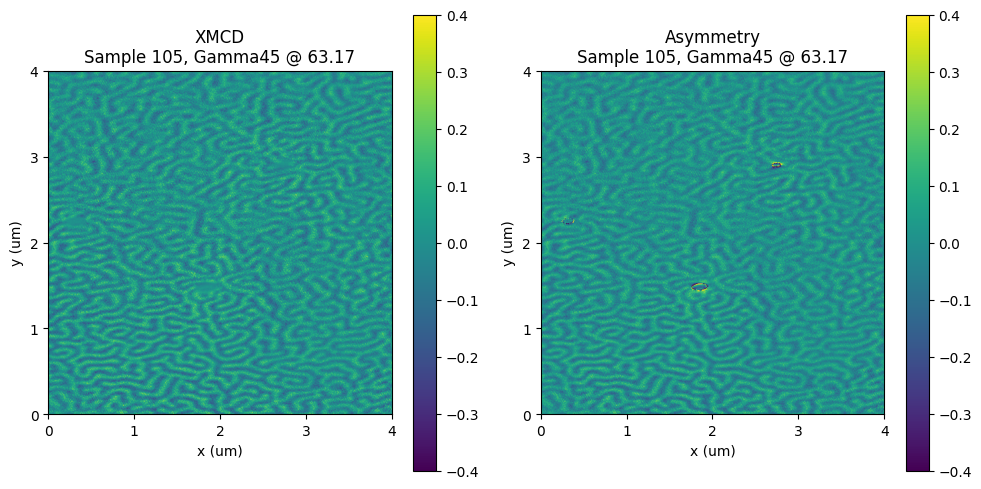

37


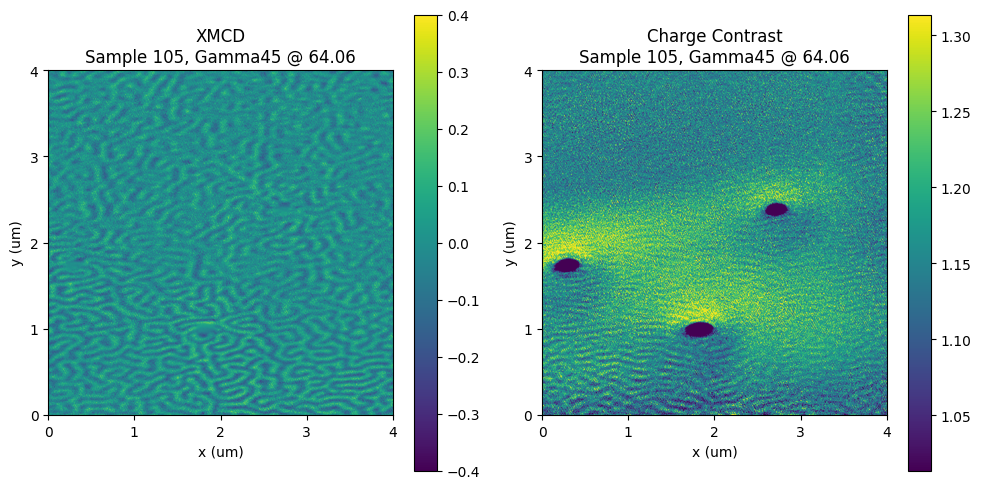

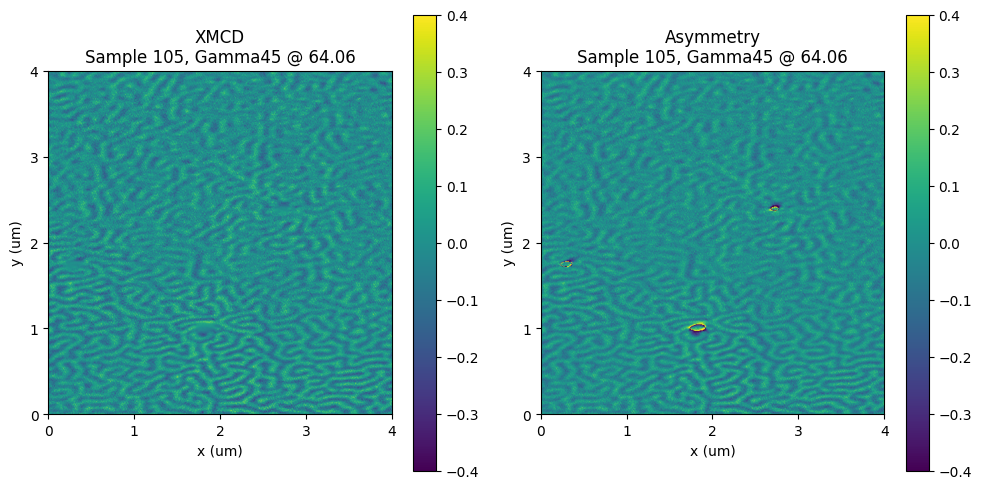

In [7]:
for k in range(image_stack_pospol.shape[0]):
    print(k)
    angle = angles_pospol[k]
    #register.plot_CLCR(image_stack_pospol[k], image_stack_negpol[k],  angle=angle, sample=sample, Gamma=Gamma)
    register.plot_XMCD_CC_normalizeCC(
        OD_XMCD[k], OD_chrgcntrst[k],
        angle=angle, sample=sample, Gamma=Gamma
    )

    register.plot_XMCD_ASYM(
        OD_XMCD[k], OD_ASYM[k],
        angle=angle, sample=sample, Gamma=Gamma
    )

---
## Step 11 — Regional Variance and PSD Quality Check

### 11a — Define Averaging Regions
Select small patches across the field of view. Their mean and variance in
charge contrast are tracked to detect scans with anomalous signal or noise.

In [8]:
# --- Patch parameters --------------------------------------------------------
half_size = 30   # half-width of each square patch (pixels)

# Grid of patch center coordinates (y, x) covering the field of view
height, width = image_stack_pospol.shape[1:]
center_y = np.array([60, 300, 475,  60, height // 2, 475,  60, 300, 475])
center_x = np.array([60,  60,  60, 300, width  // 2, 200, 475, 475, 475])

print(f"Defined {len(center_y)} regions with half_size={half_size} px")


Defined 9 regions with half_size=30 px


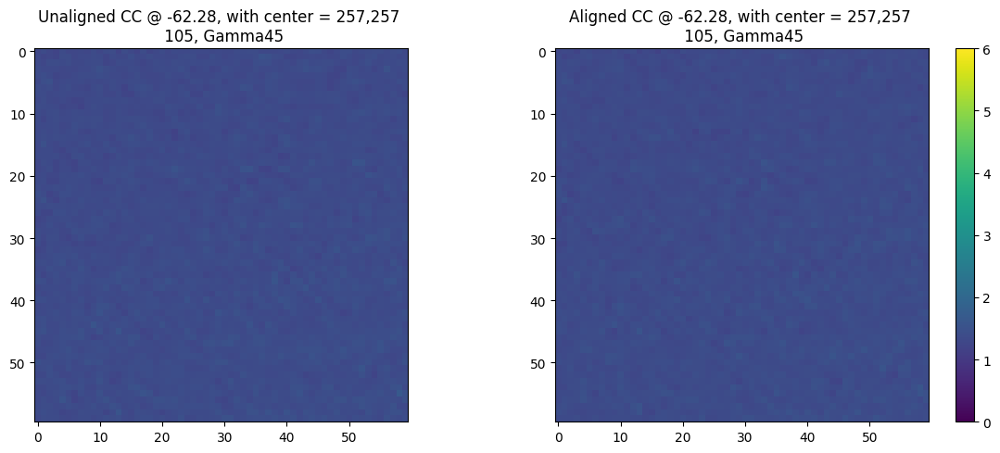

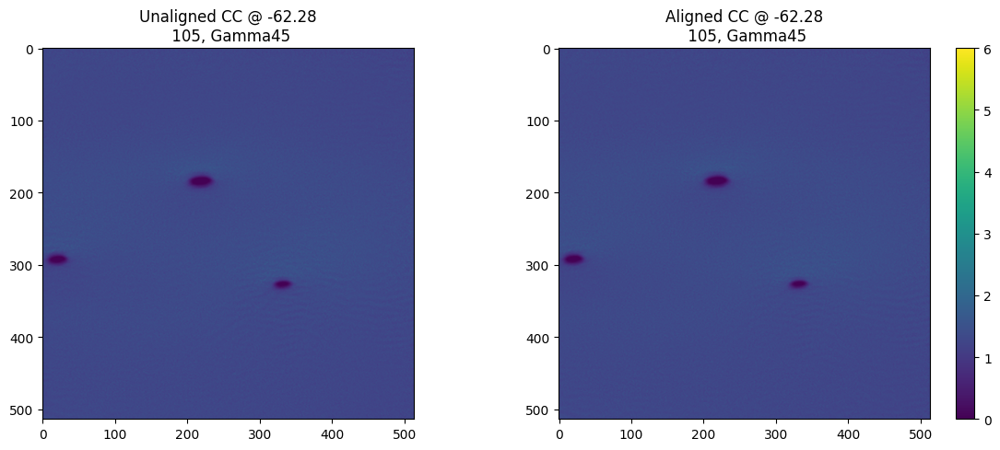

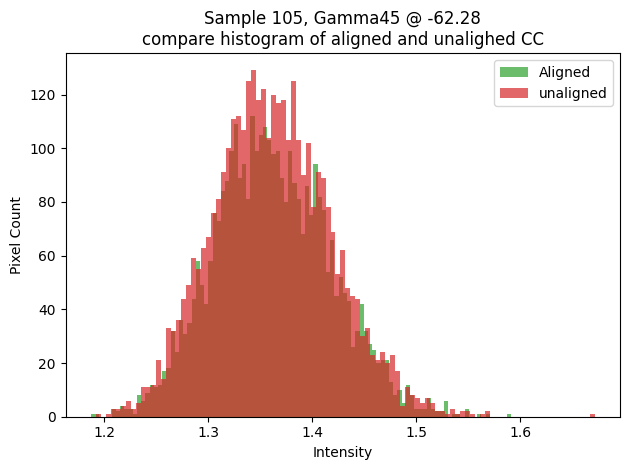

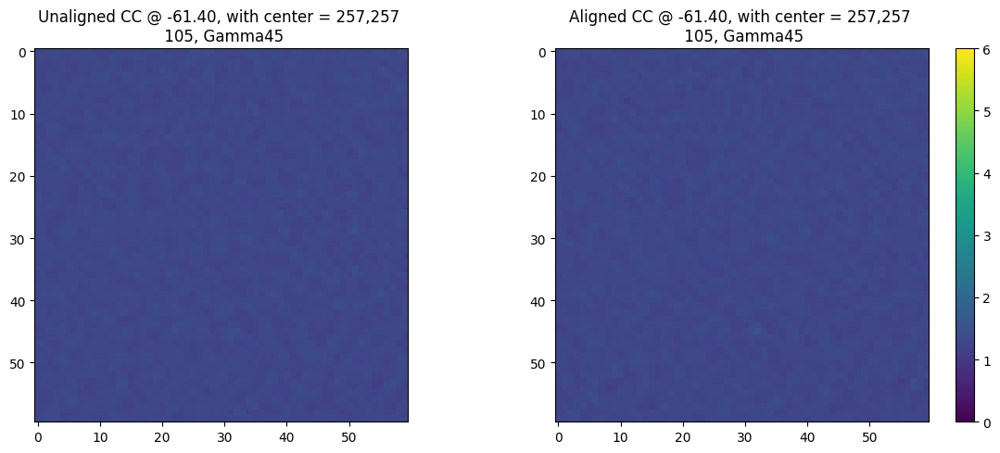

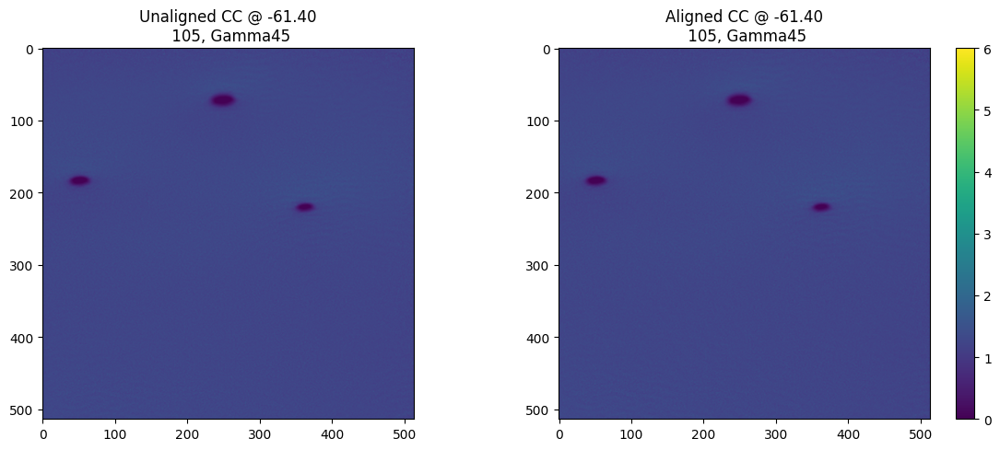

...

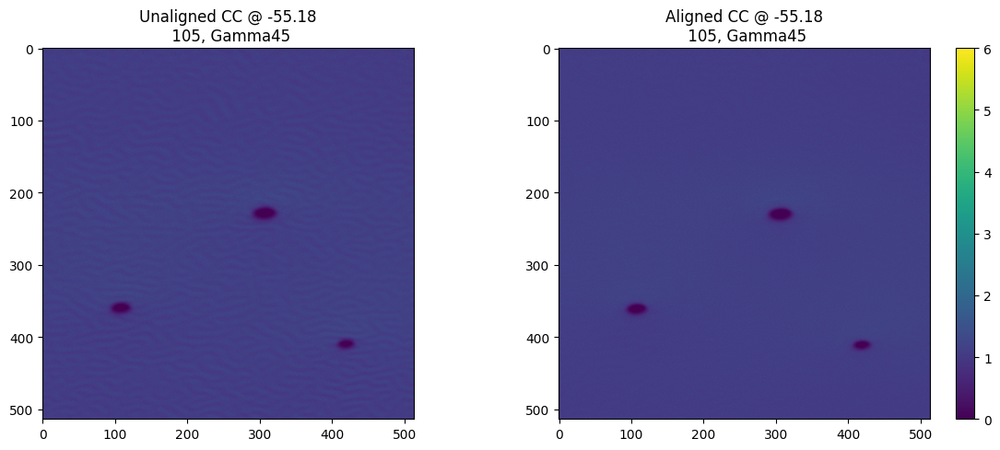

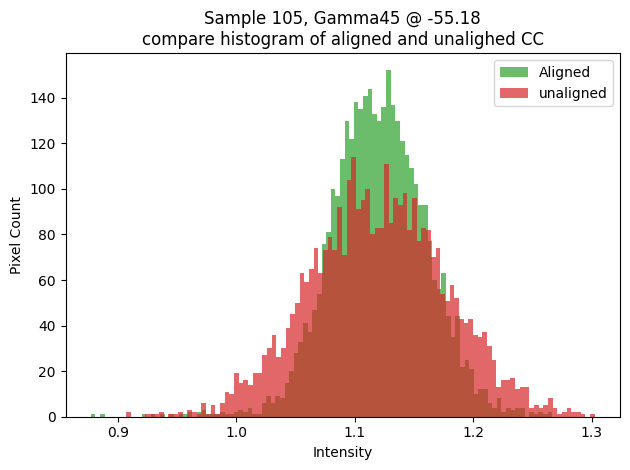

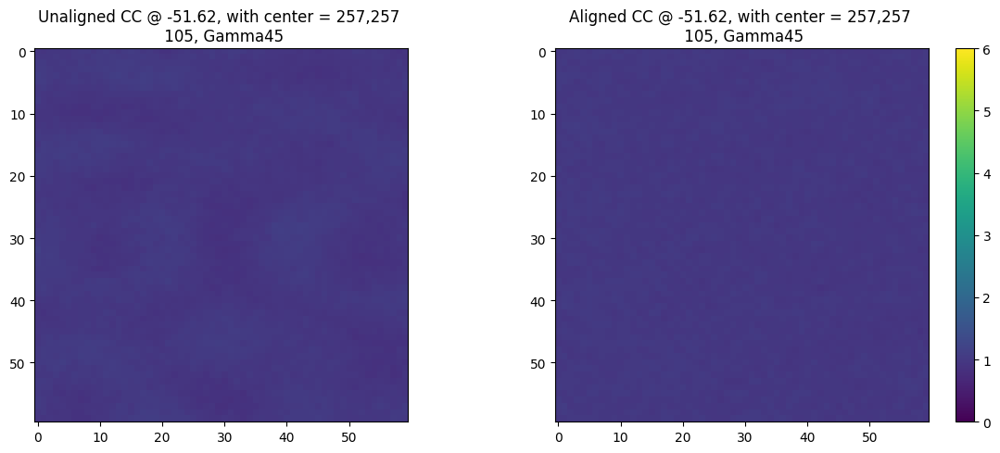

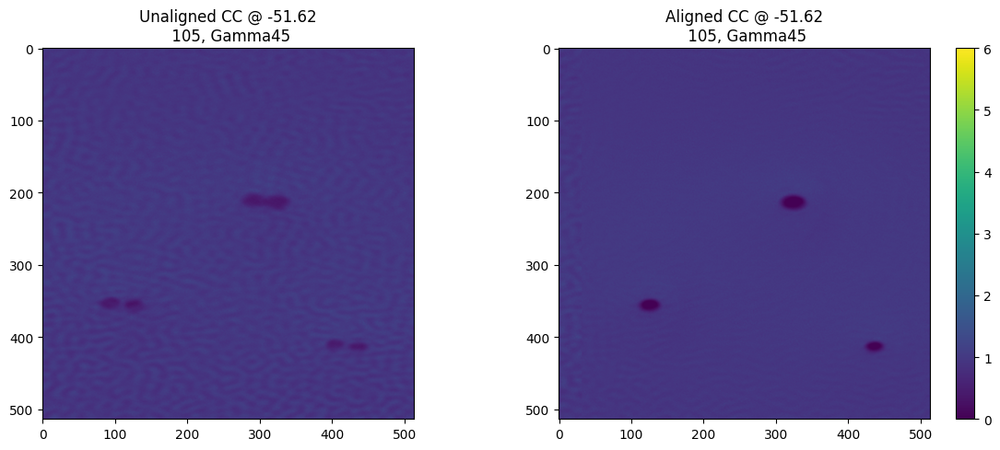

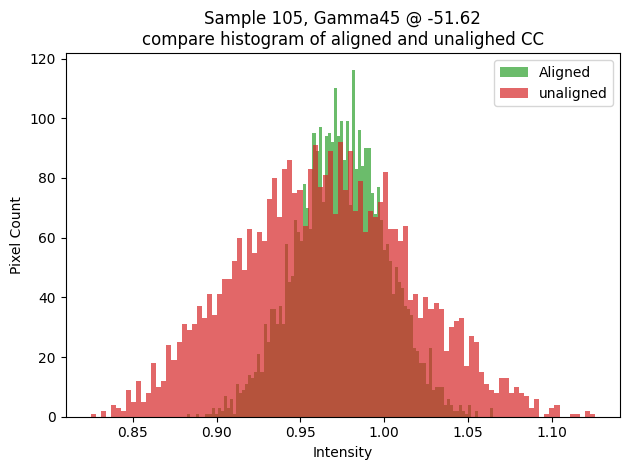

In [9]:
images_to_test = [0, 2, 4, 6, 8]  
i = 4   # <-- change to inspect a different region

for k in images_to_test:
    cy, cx = center_y[i], center_x[i]
    patch_cc  = OD_chrgcntrst[k][cy - half_size:cy + half_size,
                                  cx - half_size:cx + half_size]
    patch_ua  = CC_unaligned_OD[k][cy - half_size:cy + half_size,
                                cx - half_size:cx + half_size]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    norm_CC = mpl.colors.Normalize(vmin=0, vmax=6)
    axes[0].imshow(patch_ua, norm = norm_CC)
    axes[0].set_title(f'Unaligned CC @ {angles_pospol[k]:.2f}, with center = {cy},{cx} \n {sample}, {Gamma}')
    algined = axes[1].imshow(patch_cc, norm = norm_CC)
    axes[1].set_title(f'Aligned CC @ {angles_pospol[k]:.2f}, with center = {cy},{cx} \n {sample}, {Gamma}')
    fig.colorbar(algined, ax=axes[1])
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    norm_CC = mpl.colors.Normalize(vmin=0, vmax=6)
    axes[0].imshow(CC_unaligned_OD[k], norm = norm_CC)
    axes[0].set_title(f'Unaligned CC @ {angles_pospol[k]:.2f}\n {sample}, {Gamma}')
    algined = axes[1].imshow(OD_chrgcntrst[k], norm = norm_CC)
    axes[1].set_title(f'Aligned CC @ {angles_pospol[k]:.2f}\n {sample}, {Gamma}')
    fig.colorbar(algined, ax=axes[1])
    plt.tight_layout()
    plt.show()


    # 3. Intensity histograms (raw)
    register.plot_histogram(
        patch_cc.flatten(), patch_ua.flatten(), bin_size,
        'tab:green', 'tab:red',
        angle=angles_pospol[k], sample=sample, Gamma=Gamma, 
        label1 = 'Aligned', label2 = 'unaligned', title='compare histogram of aligned and unalighed CC'
    )



### 11b — Mean and Variance Over All Scans

Track patch mean and variance of CC (aligned and unaligned) across every scan.
`avg_mean` and `avg_var` are used to construct synthetic noise baselines for
the PSD threshold.

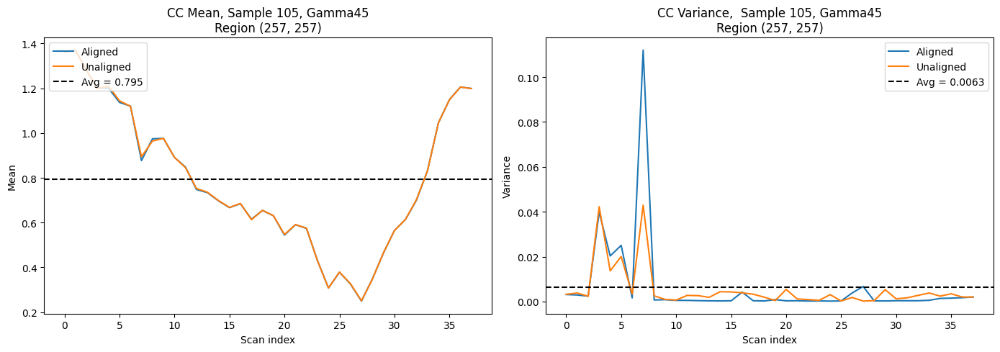

In [10]:
# --- Select region index to analyze ------------------------------------------
mean        = np.zeros(image_stack_pospol.shape[0])
variance    = np.zeros(image_stack_pospol.shape[0])
mean_ua     = np.zeros(image_stack_pospol.shape[0])
variance_ua = np.zeros(image_stack_pospol.shape[0])

for k in range(image_stack_pospol.shape[0]):
    cy, cx = center_y[i], center_x[i]
    patch_cc  = OD_chrgcntrst[k][cy - half_size:cy + half_size,
                                  cx - half_size:cx + half_size]
    patch_ua  = CC_unaligned_OD[k][cy - half_size:cy + half_size,
                                cx - half_size:cx + half_size]
    mean[k]        = np.mean(patch_cc)
    variance[k]    = np.var(patch_cc)
    mean_ua[k]     = np.mean(patch_ua)
    variance_ua[k] = np.var(patch_ua)

avg_mean = np.mean(mean)
avg_var  = np.mean(variance)

x = range(image_stack_pospol.shape[0])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(x, mean,    color='tab:blue',   label='Aligned')
axes[0].plot(x, mean_ua, color='tab:orange', label='Unaligned')
axes[0].axhline(avg_mean, color='k', linestyle='--',
                label=f'Avg = {avg_mean:.3f}')
axes[0].set_title(f"CC Mean, Sample {sample}, {Gamma}\n"
                  f"Region ({center_y[i]}, {center_x[i]})")
axes[0].set_xlabel('Scan index')
axes[0].set_ylabel('Mean')
axes[0].legend(loc='upper left')

axes[1].plot(x, variance,    color='tab:blue',   label='Aligned')
axes[1].plot(x, variance_ua, color='tab:orange', label='Unaligned')
axes[1].axhline(avg_var, color='k', linestyle='--',
                label=f'Avg = {avg_var:.4f}')
axes[1].set_title(f"CC Variance,  Sample {sample}, {Gamma}\n"
                  f"Region ({center_y[i]}, {center_x[i]})")
axes[1].set_xlabel('Scan index')
axes[1].set_ylabel('Variance')
axes[1].legend()
plt.tight_layout()
plt.show()

### 11c — PSD Quality Check

Compares the in-band PSD power of each scan against synthetic noise baselines.
Scans above the threshold carry structured (non-noise) signal and are flagged
for review.

In [11]:
band_vals, scans_to_check_uniform, scans_to_check_gauss, scans_to_check_avg = \
    register.PSD_Check(
        OD_chrgcntrst, region=i,
        center_y=center_y, center_x=center_x, half_size=half_size,
        image_stack_pospol=image_stack_pospol,
        avg_mean=avg_mean, avg_var=avg_var, set_plot = False
    )

print(f"Flagged (uniform threshold) : {scans_to_check_uniform}")
print(f"Flagged (Gaussian threshold): {scans_to_check_gauss}")
print(f"Flagged (average threshold) : {scans_to_check_avg}")

Flagged (uniform threshold) : [3, 4, 5, 7, 8, 12, 13, 15, 16, 17, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
Flagged (Gaussian threshold): [0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]
Flagged (average threshold) : [3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


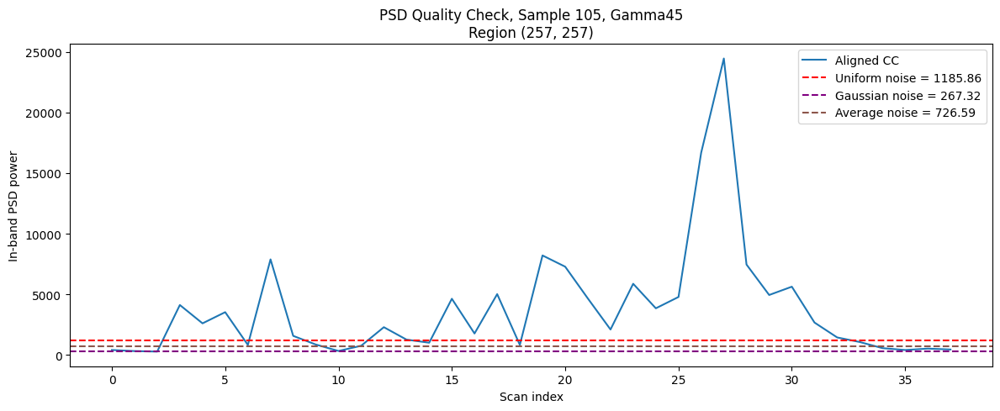

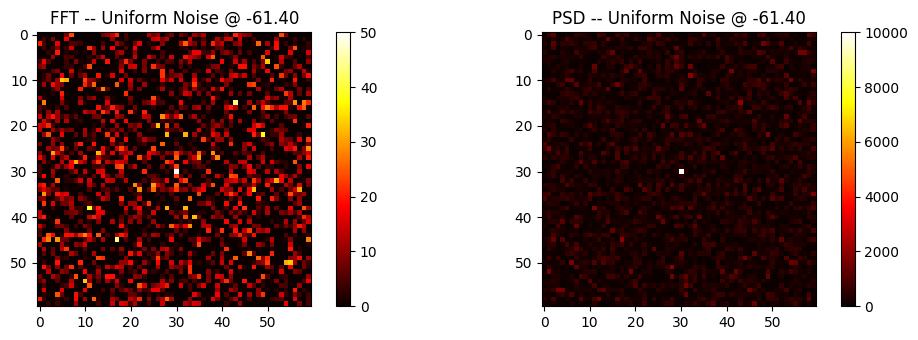

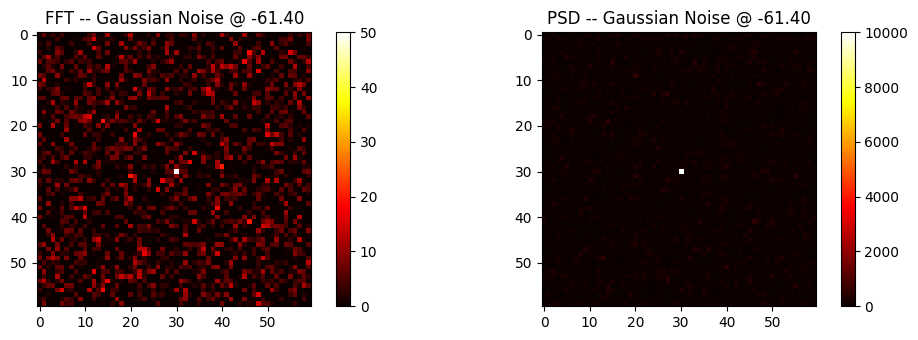

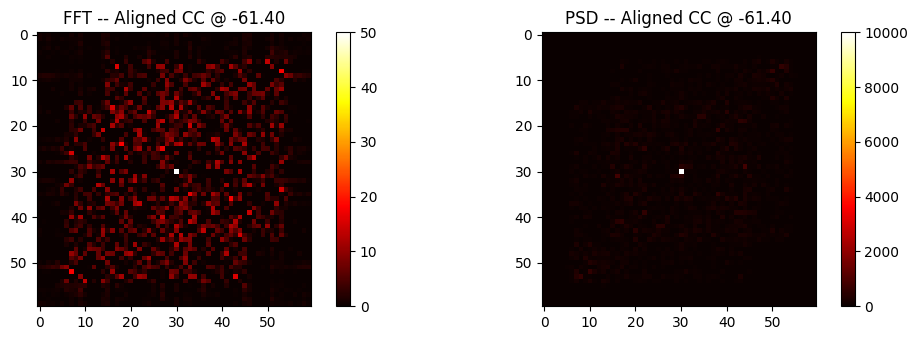

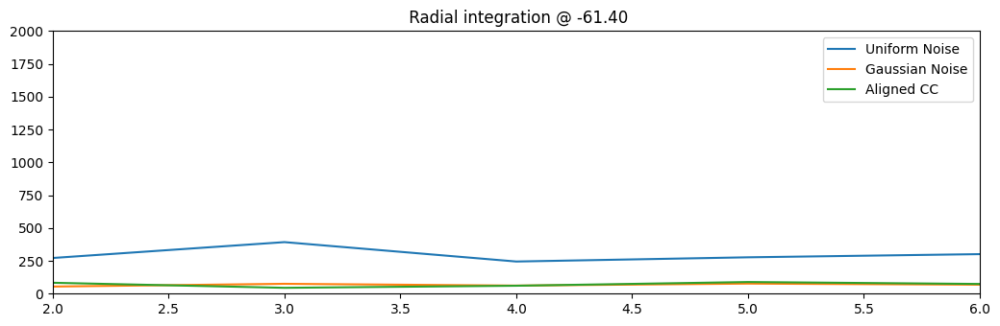

...

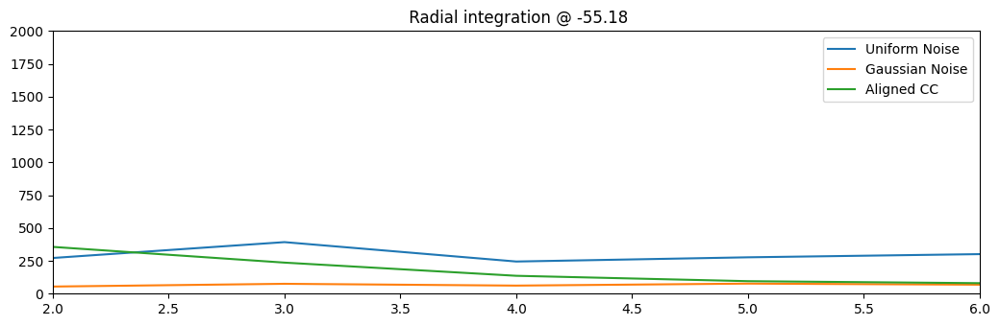

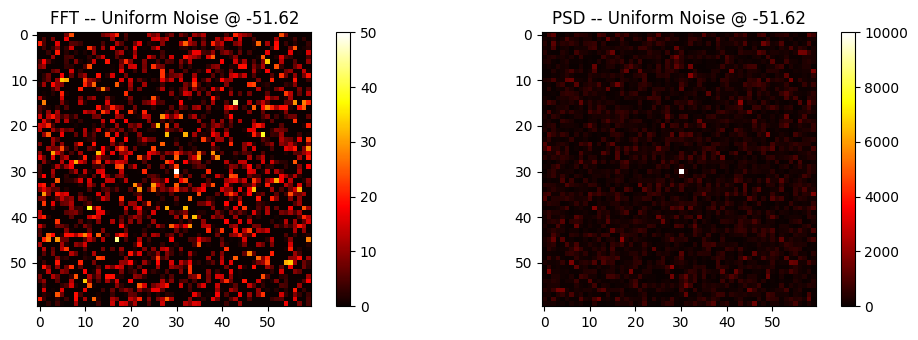

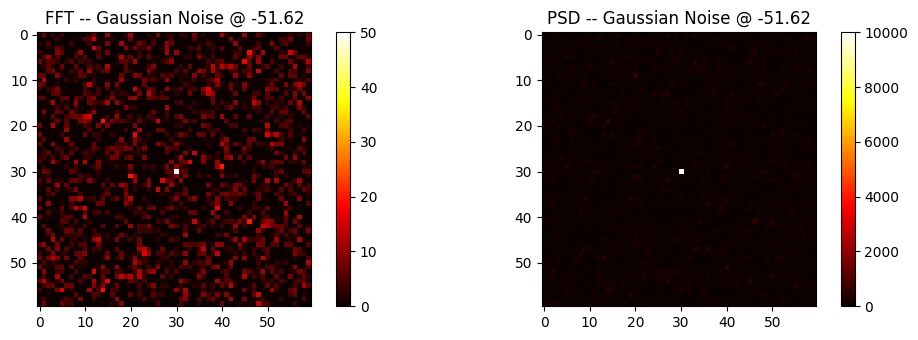

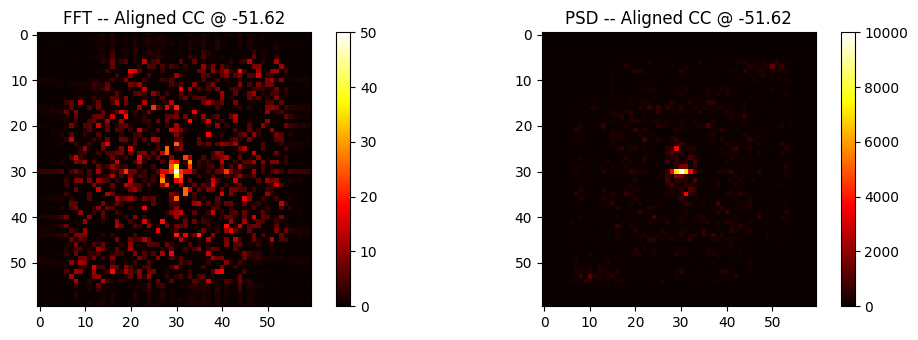

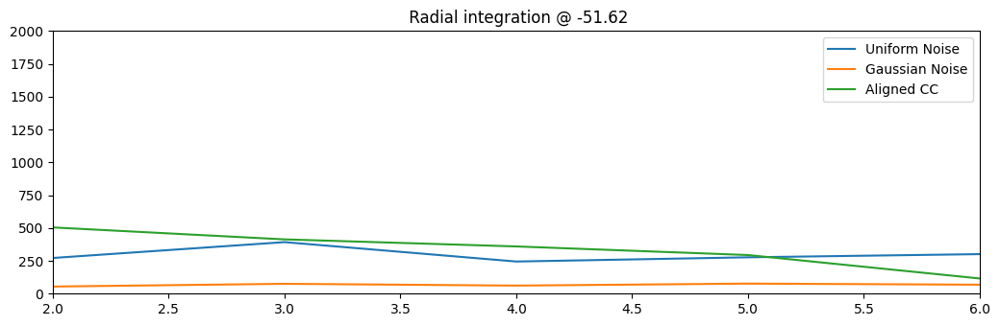

In [12]:
# --- Rebuild noise thresholds for plotting -----------------------------------
patch_shape = (half_size * 2, half_size * 2)
noise_uniform = register.generate_uniform_noise_image(
    patch_shape, avg_mean - np.sqrt(avg_var), avg_mean + np.sqrt(avg_var)
)
noise_gauss = register.generate_gaussian_noise_image(
    patch_shape, avg_mean, np.sqrt(avg_var)
)
band_noise_unif, band_noise_gauss, _ = register.compare_CC(
    noise_uniform, noise_gauss, noise_gauss, plot=False
)
band_noise_avg = np.mean([band_noise_unif, band_noise_gauss])

# --- Plot in-band PSD power vs. scan index -----------------------------------
fig, axes = plt.subplots(1, 1, figsize=(12, 5))
axes.plot(range(image_stack_pospol.shape[0]), band_vals,
          color='tab:blue', label='Aligned CC')
axes.axhline(band_noise_unif,  color='red',       linestyle='--',
             label=f'Uniform noise = {band_noise_unif:.2f}')
axes.axhline(band_noise_gauss, color='purple',    linestyle='--',
             label=f'Gaussian noise = {band_noise_gauss:.2f}')
axes.axhline(band_noise_avg,   color='tab:brown', linestyle='--',
             label=f'Average noise = {band_noise_avg:.2f}')
axes.set_title(f"PSD Quality Check, Sample {sample}, {Gamma}\n"
               f"Region ({center_y[i]}, {center_x[i]})")
axes.set_xlabel('Scan index')
axes.set_ylabel('In-band PSD power')
axes.legend(loc='upper right')
plt.tight_layout()
plt.show()

## look at the band radial average for a few scans 
k_list = [2,4, 6, 8]
for k in k_list: 
    cy, cx = center_y[i], center_x[i]
    cropped = OD_chrgcntrst[k][cy - half_size:cy + half_size,
                             cx - half_size:cx + half_size]
    
    register.compare_CC(noise_uniform, noise_gauss, cropped, plot=True,
                   band=(2, 6), label1='Uniform Noise', label2 = 'Gaussian Noise', label3 = 'Aligned CC', angles_pospol=angles_pospol, k=k)


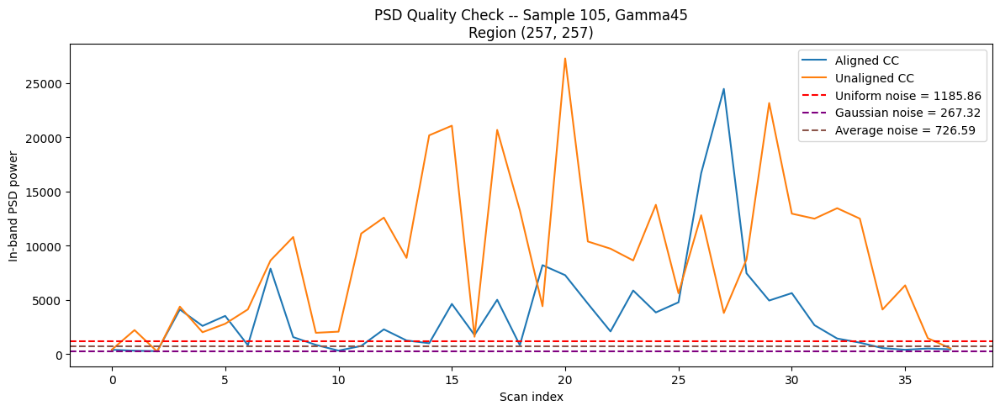

In [13]:
# compare to unaligned images

band_vals_ua, ___, ___, ___ = \
    register.PSD_Check(
        CC_unaligned_OD, region=i,
        center_y=center_y, center_x=center_x, half_size=half_size,
        image_stack_pospol=image_stack_pospol,
        avg_mean=avg_mean, avg_var=avg_var
    )


# --- Plot in-band PSD power vs. scan index -----------------------------------
fig, axes = plt.subplots(1, 1, figsize=(12, 5))
axes.plot(range(image_stack_pospol.shape[0]), band_vals,
          color='tab:blue', label='Aligned CC')

axes.plot(range(image_stack_pospol.shape[0]), band_vals_ua,
          color='tab:orange', label='Unaligned CC')

axes.axhline(band_noise_unif,  color='red',       linestyle='--',
             label=f'Uniform noise = {band_noise_unif:.2f}')
axes.axhline(band_noise_gauss, color='purple',    linestyle='--',
             label=f'Gaussian noise = {band_noise_gauss:.2f}')
axes.axhline(band_noise_avg,   color='tab:brown', linestyle='--',
             label=f'Average noise = {band_noise_avg:.2f}')
axes.set_title(f"PSD Quality Check -- Sample {sample}, {Gamma}\n"
               f"Region ({center_y[i]}, {center_x[i]})")
axes.set_xlabel('Scan index')
axes.set_ylabel('In-band PSD power')
axes.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 11d — Inspect Flagged Scans

View XMCD and CC for each flagged scan to decide whether it should be excluded.

In [ ]:
# Use the average-threshold list as the working set (most conservative).
# Swap in scans_to_check_uniform or scans_to_check_gauss if preferred.
scans_to_review = scans_to_check_avg

print(f"Reviewing {len(scans_to_review)} flagged scans: {scans_to_review}")

for k in scans_to_review:
    angle = angles_pospol[k]
    print(f"  k={k} | angle={angle:.2f}")
    color_cc = 'green'
    range_min, range_max, _, _ = register.auto_normalize_OD_charge(
        OD_chrgcntrst[k], color_cc, plot_hist=PLOT_CHARGE_HIST
    )
    norm_XMCD   = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)
    norm_charge = mpl.colors.Normalize(vmin=range_min, vmax=range_max)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    im0 = axes[0].imshow(OD_XMCD[k], norm=norm_XMCD)
    axes[0].set_title(f"XMCD -- Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(im0, ax=axes[0])
    im1 = axes[1].imshow(OD_chrgcntrst[k], norm=norm_charge)
    axes[1].set_title(f"Charge Contrast -- Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(im1, ax=axes[1])
    plt.tight_layout()
    plt.show()

---
## Step 12 — Optional: Remove Bad Scans and Re-Align

If the PSD check identified scans to exclude, re-run alignment with those scans
skipped (optionally using a tighter search bound). Re-aligned outputs are stored
in `_final` arrays.

> **Edit `scans_to_skip`** with the indices to exclude before running.

In [ ]:
# Intentional stop -- review Step 11 output before proceeding.
raise SystemExit("Review flagged scans above before running the re-alignment.")

In [ ]:
# --- Scans to skip in the re-alignment pass ----------------------------------
scans_to_skip = [4,47] #scans_to_check_avg  # or a custom list, e.g. [7, 41, 44]

# --- Tighter bound used for previously problematic scans ---------------------
bound_tight = 50

print(f"Re-alignment: skipping {len(scans_to_skip)} scans: {scans_to_skip}")

# --- Initialize final output arrays ------------------------------------------
translated_negpol_final  = np.zeros_like(image_stack_negpol, dtype=np.float32)
norm_pos_OD_final        = np.zeros_like(image_stack_pospol, dtype=np.float32)
norm_neg_OD_final        = np.zeros_like(image_stack_negpol, dtype=np.float32)
aligned_error_norm_final = np.empty(image_stack_pospol.shape[0])

# --- Re-alignment loop -------------------------------------------------------
for k in range(image_stack_pospol.shape[0]):
    angle = angles_pospol[k]

    # Use tighter bound for flagged scans
    current_bound = bound_tight if k in scans_to_skip else bound

    norm_neg, _ = register.auto_normalize_by_fiducial(
        image_stack_negpol[k], color_neg, plot_hist=PLOT_FIDUCIAL_HIST
    )
    norm_pos, _ = register.auto_normalize_by_fiducial(
        image_stack_pospol[k], color_pos, plot_hist=PLOT_FIDUCIAL_HIST
    )

    masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)
    translation, corr = register.align_images_CC(masked_pos, masked_neg, current_bound)

    f_target         = fftn(norm_neg)
    f_target_shifted = fourier_shift(f_target, translation)
    translated_OD    = ifftn(f_target_shifted).real

    norm_pos_OD_final[k]       = -1 * np.log(norm_pos)
    norm_neg_OD_final[k]       = -1 * np.log(norm_neg)
    translated_negpol_final[k] = -1 * np.log(translated_OD)

    orig_error = register.calc_NRMSE(image_stack_negpol[k], image_stack_pospol[k])
    aligned_error_norm_final[k] = register.calc_NRMSE(
        translated_negpol_final[k], norm_pos_OD_final[k]
    )

    if PLOT_CROSSCORR:
        unaligned_diff = norm_neg_OD_final[k] - norm_pos_OD_final[k]
        aligned_diff   = translated_negpol_final[k] - norm_pos_OD_final[k]
        register.plot_XMCD_crosscorr(
            unaligned_diff, aligned_diff, corr,
            angle=angle, sample=sample, Gamma=Gamma
        )

    print(f"  k={k:3d} | before={orig_error*100:.2f}%  "
          f"after={aligned_error_norm_final[k]*100:.2f}%")

# --- Compute final CC and XMCD -----------------------------------------------
CC_final   = norm_pos_OD_final + translated_negpol_final
XMCD_final = translated_negpol_final - norm_pos_OD_final

print("\nRe-alignment complete.")
print(f"  CC_final shape   : {CC_final.shape}")
print(f"  XMCD_final shape : {XMCD_final.shape}")

---
## Step 10 — Angle Calibration: Find True Zero

The NRMSE between aligned CPL and CPR images follows a cosine with tilt angle
-- it is maximized at the angle of maximum magnetic contrast (true alpha=0).
We fit this cosine to identify that angle and shift the axis accordingly.

**Output:** `shifted_angles` -- calibrated tilt angle array used in all
subsequent analysis.

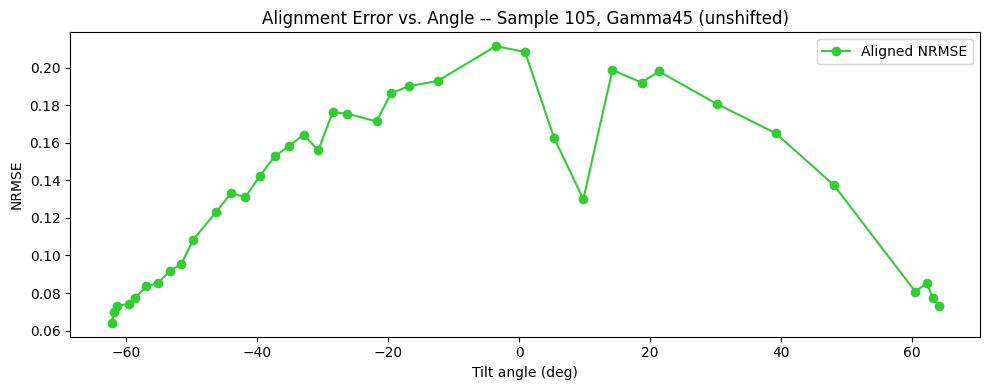

In [14]:
# --- Raw NRMSE vs. angle (unshifted) -----------------------------------------
plt.figure(figsize=(10, 4))
plt.plot(angles_pospol, aligned_error_norm, marker='o', color=color_1,
         label='Aligned NRMSE')
plt.ylabel('NRMSE')
plt.xlabel('Tilt angle (deg)')
plt.title(f"Alignment Error vs. Angle -- Sample {sample}, {Gamma} (unshifted)")
plt.legend()
plt.tight_layout()
plt.show()

Cosine peak (unshifted) at 0.89 deg
  --> This angle will be shifted to zero.


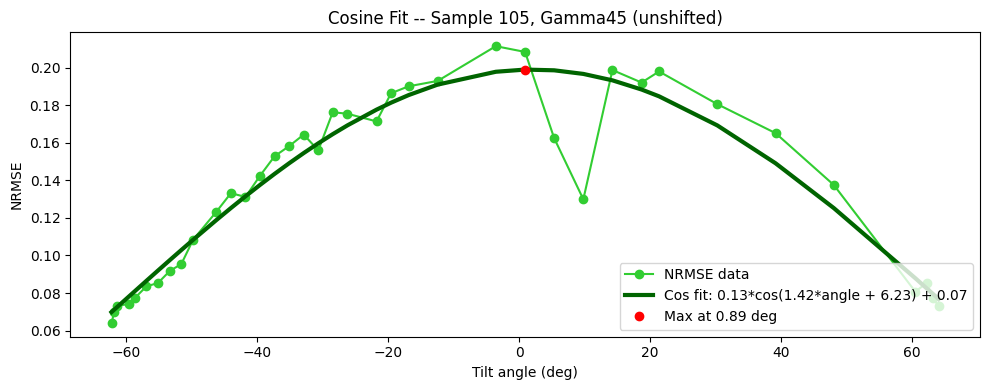

In [15]:
# --- Fit cosine to raw (unshifted) angles ------------------------------------
# plot_angles     = np.linspace(angles_pospol[0], np.max(angles_pospol),
#                               angles_pospol.shape[0]*2)
plot_angles_rad = np.deg2rad(angles_pospol)

bounds = ([0, 0, -2 * np.pi], [np.inf, np.inf, 2 * np.pi])
guess  = [0.1, 2 * np.mean(aligned_error_norm), 6]

y_params, _ = curve_fit(
    register.cos_fit, plot_angles_rad, aligned_error_norm,
    p0=guess, bounds=bounds
)
y_cos_fit = register.cos_fit(plot_angles_rad, *y_params)
b_fix     = np.pi / np.ptp(plot_angles_rad)

peak_idx   = np.argmax(y_cos_fit)
peak_angle = angles_pospol[peak_idx]
print(f"Cosine peak (unshifted) at {peak_angle:.2f} deg")
print(f"  --> This angle will be shifted to zero.")

plt.figure(figsize=(10, 4))
plt.plot(angles_pospol, aligned_error_norm, marker='o', color=color_1,
         label='NRMSE data')
plt.plot(angles_pospol, y_cos_fit, color=color_2, linewidth=3,
         label=(f"Cos fit: {y_params[0]:.2f}*cos({b_fix:.2f}*angle"
                f" + {y_params[2]:.2f}) + {y_params[1]:.2f}"))
plt.plot(peak_angle, np.max(y_cos_fit), 'ro',
         label=f"Max at {peak_angle:.2f} deg")
plt.xlabel('Tilt angle (deg)')
plt.ylabel('NRMSE')
plt.title(f"Cosine Fit -- Sample {sample}, {Gamma} (unshifted)")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Angle range after shift: [-63.17, 63.17] deg


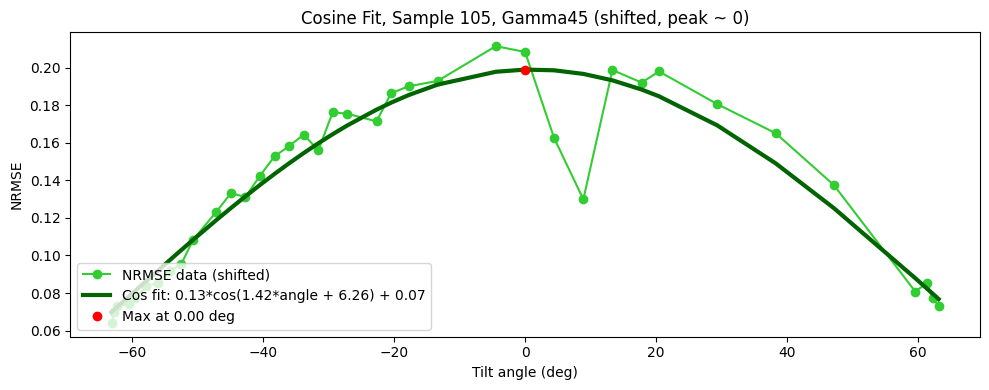

In [16]:
# --- Shift angles so that cosine maximum = 0 deg -----------------------------
shifted_angles = angles_pospol - peak_angle
print(f"Angle range after shift: [{shifted_angles[0]:.2f}, {shifted_angles[-1]:.2f}] deg")

# --- Fit cosine to shifted angles to confirm peak is near zero ---------------
# plot_angles_shift     = np.linspace(shifted_angles[0], np.max(shifted_angles),
#                                     shifted_angles.shape[0])
plot_angles_rad_shift = np.deg2rad(shifted_angles)

guess_shift = [5, np.mean(aligned_error_norm), 2]
y_params_shift, _ = curve_fit(
    register.cos_fit, plot_angles_rad_shift, aligned_error_norm,
    p0=guess_shift, bounds=bounds
)
y_cos_fit_shift = register.cos_fit(plot_angles_rad_shift, *y_params_shift)
b_fix_shift     = np.pi / np.ptp(plot_angles_rad_shift)

peak_idx_shift   = np.argmax(y_cos_fit_shift)
peak_angle_shift = shifted_angles[peak_idx_shift]

plt.figure(figsize=(10, 4))
plt.plot(shifted_angles, aligned_error_norm, marker='o', color=color_1,
         label='NRMSE data (shifted)')
plt.plot(shifted_angles, y_cos_fit_shift, color=color_2, linewidth=3,
         label=(f"Cos fit: {y_params_shift[0]:.2f}*cos({b_fix_shift:.2f}*angle"
                f" + {y_params_shift[2]:.2f}) + {y_params_shift[1]:.2f}"))
plt.plot(peak_angle_shift, np.max(y_cos_fit_shift), 'ro',
         label=f"Max at {peak_angle_shift:.2f} deg")
plt.xlabel('Tilt angle (deg)')
plt.ylabel('NRMSE')
plt.title(f"Cosine Fit, Sample {sample}, {Gamma} (shifted, peak ~ 0)")
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()


---
## Step 13 — Optional: Build Scan-Skipped Dataset

If some scans are permanently excluded, create compact stacks containing only
the valid scans for downstream tomographic reconstruction.

In [ ]:
raise SystemExit("Confirm scans_to_skip before building the skipped dataset.")

In [ ]:
# Indices to permanently exclude (copy from scans_to_skip or define custom)
exclude_indices = scans_to_skip   # <-- edit if needed

valid_indices = [k for k in range(image_stack_pospol.shape[0])
                 if k not in exclude_indices]

CC_skipped     = OD_chrgcntrst[valid_indices]
XMCD_skipped   = OD_XMCD[valid_indices]
angles_skipped = angles_pospol[valid_indices]

print(f"Kept {len(valid_indices)} / {image_stack_pospol.shape[0]} scans")
print(f"  CC_skipped shape     : {CC_skipped.shape}")
print(f"  angles_skipped shape : {angles_skipped.shape}")

---
## Step 14 — Save Outputs

Write aligned stacks and angle arrays to disk in the same `data_dir` as the
inputs. The `modifier` string (set in Step 2) is appended to filenames
to distinguish processing runs.

Uncomment the blocks for the datasets you want to save.

In [ ]:
raise SystemExit("Review all outputs above before saving to disk.")

In [17]:
# --- Output Modifier ---------------------------------------------------------
# Appended to all output filenames to label this processing run.
modifier = 'bsub_kmeans_log10'      # e.g. 'all_scans_failed_psd', '_test', '_skipped'

print(f"Saving to   : {data_dir}")
print(f"Date / Gamma : {date}, {Gamma}")
print(f"Modifier    : '{modifier}'")


Saving to   : /homes/emma/notebooks/RawData/105/Gamma45/
Date / Gamma : _19NOV25_select_fullrange, Gamma45
Modifier    : 'bsub_kmeans_log10'


In [ ]:
save = False

if save == True: 
    # np.savetxt(os.path.join(data_dir, f"unaligned_mean_{date}_{modifier}.txt"), mean_ua)
    # np.savetxt(os.path.join(data_dir, f"unaligned_var_{date}_{modifier}.txt"), variance_ua)
  
    # np.savetxt(os.path.join(data_dir, f"aligned_mean_{date}_{modifier}.txt"), mean)
    # np.savetxt(os.path.join(data_dir, f"aligned_var_{date}_{modifier}.txt"), variance)

    np.savetxt(os.path.join(data_dir, f"fid_amp_neg_{date}_{modifier}.txt"), fid_amp_neg)
    np.savetxt(os.path.join(data_dir, f"fid_amp_pos_{date}_{modifier}.txt"), fid_amp_pos)

In [18]:
# --- Initial alignment outputs -----------------------------------------------
tifffile.imwrite(
    os.path.join(data_dir, f"OD_negpol_aligned_stack{date}_{Gamma}_{modifier}.tiff"),
    translated_negpol
)
tifffile.imwrite(
    os.path.join(data_dir, f"OD_chrgcntrst_stack{date}_{Gamma}_{modifier}.tiff"),
    OD_chrgcntrst
)
tifffile.imwrite(
    os.path.join(data_dir, f"OD_XMCD_stack{date}_{Gamma}_{modifier}.tiff"),
    OD_XMCD
)

tifffile.imwrite(
    os.path.join(data_dir, f"OD_ASYM_stack{date}_{Gamma}_{modifier}.tiff"),
    OD_ASYM
)

# --- Re-alignment / final outputs (uncomment if Step 12 was run) -------------
# tifffile.imwrite(
#     os.path.join(data_dir, f"OD_chrgcntrst_stack{date}_{Gamma}{modifier}_final.tiff"),
#     CC_final
# )
# tifffile.imwrite(
#     os.path.join(data_dir, f"OD_XMCD_stack{date}_{Gamma}{modifier}_final.tiff"),
#     XMCD_final
# )

# --- Scan-skipped outputs (uncomment if Step 13 was run) ---------------------
# tifffile.imwrite(
#     os.path.join(data_dir,
#                  f"OD_chrgcntrst_stack{date}_{Gamma}{modifier}_skipped.tiff"),
#     CC_skipped
# )
# tifffile.imwrite(
#     os.path.join(data_dir,
#                  f"OD_XMCD_stack{date}_{Gamma}{modifier}_skipped.tiff"),
#     XMCD_skipped
# )
# np.savetxt(
#     os.path.join(data_dir, f"angles{date}_{Gamma}{modifier}_skipped.txt"),
#     angles_skipped
# )

#--- Shifted angle array (uncomment to save) ---------------------------------
np.savetxt(
    os.path.join(data_dir, f"angles_shifted{date}_{Gamma}_{modifier}.txt"),
    shifted_angles
)



print("\nSave complete.")


Save complete.
